In [1]:
from pathlib import Path
import sys
import os
import json
import math
import datetime
import warnings
from datetime import datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
import joblib
import xgboost as xgb
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve,
)
import findspark
findspark.init()

from pyspark.sql import SparkSession, DataFrame
from pyspark.sql import functions as func
from pyspark.sql.functions import col, desc, udf
from pyspark.sql.types import StructType, StructField, StringType

from ortools.linear_solver import pywraplp

warnings.filterwarnings("ignore")


# Backflow imports
from backflow import exp_setting
from backflow.programming import pgt
from backflow.calib import metrics as calib_metric
from backflow.calib import stats as calib_stats
from backflow.visualization import vis
from backflow.programming import simulation as pgtsimu
from backflow.utils import tools as bkfl_tools


# Matplotlib font

from pyspark.sql import SparkSession
spark3conf_best = {
    "spark.submit.deployMode": "client",
    "spark.yarn.queue": "root.growstrategy_group_prod",

    "spark.driver.memory": "24g",
    "spark.driver.memoryOverhead": "4g",

    "spark.dynamicAllocation.enabled": "true",
    "spark.dynamicAllocation.minExecutors": "80",
    "spark.dynamicAllocation.initialExecutors": "80",
    "spark.dynamicAllocation.maxExecutors": "120",
    "spark.dynamicAllocation.shuffleTracking.enabled": "true",

    "spark.executor.cores": "2",
    "spark.executor.memory": "12g",
    "spark.executor.memoryOverhead": "8g",

    "spark.default.parallelism": "1200",
    "spark.sql.shuffle.partitions": "1200",

    "spark.sql.adaptive.enabled": "true",
    "spark.sql.adaptive.coalescePartitions.enabled": "true",
    "spark.sql.adaptive.skewJoin.enabled": "true",
    "spark.sql.adaptive.advisoryPartitionSizeInBytes": "134217728",

    "spark.sql.autoBroadcastJoinThreshold": "104857600",
    "spark.sql.broadcastTimeout": "3000",

    "spark.network.timeout": "600s",
    "spark.executor.heartbeatInterval": "60s",

    "spark.memory.fraction": "0.8",
    "spark.memory.storageFraction": "0.3",

    "spark.sql.execution.arrow.pyspark.enabled": "true",
    "spark.sql.execution.arrow.maxRecordsPerBatch": "5000",

    "mapred.input.dir.recursive": "TRUE",
    "hive.mapred.supports.subdirectories": "TRUE",

    "spark.serializer": "org.apache.spark.serializer.KryoSerializer",
    "spark.kryoserializer.buffer.max": "1024m",

    "spark.yarn.dist.archives": "hdfs://difed/user/dm/ENV/dlflow/v2/py3.7.15_for_tfcluster_63.tgz",
    "spark.executorEnv.PYSPARK_PYTHON": "./py3.7.15_for_tfcluster_63.tgz/py3.7.15_for_tfcluster/bin/python3",

    "spark.extraListeners": "sparkmonitor.listener.JupyterSparkMonitorListener",

    "spark.sql.merge.mode": "FAST",
    "spark.sql.merge.enabled": "TRUE",
}

builder = (
    SparkSession
    .builder
    .appName("flowback_euen_v22")
    .master("yarn")
)

for k, v in spark3conf_best.items():
    builder = builder.config(k, v)

spark = builder.enableHiveSupport().getOrCreate()

print("[Info] Spark Version:", spark.version)
print("[Info] Spark Queue:", spark.conf.get("spark.yarn.queue"))
print("[Info] Spark App ID:", spark.sparkContext.applicationId)
print(spark.conf.get("spark.yarn.queue"))
print(spark.sparkContext.applicationId)

load metric func from causalml...


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
Application Id: application_1782979140233_37372018, Tracking URL: http://bigdata-nmg-hdprm00.nmg01:8088/proxy/application_1782979140233_37372018/
INFO:SparkMonitorKernel:Client Connected ('127.0.0.1', 40978)


[Info] Spark Version: 3.2.0-101
[Info] Spark Queue: root.growstrategy_group_prod
[Info] Spark App ID: application_1782979140233_37372018
root.growstrategy_group_prod
application_1782979140233_37372018


In [2]:
plt.rcParams.update({
    # 按系统优先级填写中文字体
    "font.sans-serif": [
        "Microsoft YaHei",   # Windows 微软雅黑
        "SimHei",            # Windows 黑体
        "Arial Unicode MS",  # MacOS
        "PingFang SC",       # MacOS 苹方
        "WenQuanYi Zen Hei"  # Linux
    ],
    "axes.unicode_minus": False,  # 解决负号 '-' 变成方框
})

In [3]:
import datetime
from itertools import product

# 生成一段日期列表。从 start_dt 开始，一天一天往前或往后走，收集够 degree_days 天，最后排序并返回最后 degree_days 个日期
def smart_generate_dt_list(start_dt, degree_days, step=1, format="%Y-%m-%d", flag=1, 
                          ignore_dts=[]):
    
    strptime, strftime = datetime.datetime.strptime, datetime.datetime.strftime
    
    gen_dts = []
    curr_dt = start_dt
    
    while len(gen_dts)<degree_days:
        if curr_dt not in ignore_dts:
            gen_dts.append(curr_dt)
        
        __dt = strftime(strptime(curr_dt, format) - datetime.timedelta(1), format)
        if flag == 1:
            __dt = strftime(strptime(curr_dt, format) + datetime.timedelta(1), format)
            
        curr_dt = __dt
    
        
    gen_dts = sorted(gen_dts)
    if gen_dts[-1] != start_dt:
        gen_dts.append(start_dt)
    return sorted(gen_dts)[-degree_days:]

In [4]:
# delta_cac:每多带来1个增量完单，需要多花多少钱

def calculate_delta_metrics(df, group_name_1, group_name_2):
    # 计算通补delta cac、delta cvr函数
    # 取出当前 bucket 下的数据
    bucket_data = df

    # 分别取出 group_name_eve 为 group_name_1 和 group_name_2 的数据
    data_1 = bucket_data[bucket_data['group_name_eve'] == group_name_1]
    data_2 = bucket_data[bucket_data['group_name_eve'] == group_name_2]

    # 计算各自的总数量和 cost_7d 的总和
    total_count_1 = len(data_1)
    total_cost_1 = data_1['cost_7d'].sum()
    total_cvr_1 = data_1['pv_label_7d'].sum()

    total_count_2 = len(data_2)
    total_cost_2 = data_2['cost_7d'].sum()
    total_cvr_2 = data_2['pv_label_7d'].sum()

    # cac1，2:是人均成本; cvr1,2是人均7日完单。
    # 实验组每人平均成本 - 对照组每人平均成本 / 实验组每人平均订单 - 对照组每人平均订单
    cac_1 = total_cost_1 / total_count_1 if total_count_1 > 0 else 0
    cac_2 = total_cost_2 / total_count_2 if total_count_2 > 0 else 0

    cvr_1 = total_cvr_1 / total_count_1 if total_count_1 > 0 else 0
    cvr_2 = total_cvr_2 / total_count_2 if total_count_2 > 0 else 0

    delta_cost = cac_1 - cac_2
    delta_cvr = cvr_1 - cvr_2
    delta_cac = delta_cost / delta_cvr if delta_cvr != 0 else 0

    return delta_cac, delta_cvr

In [5]:
def calculate_percentile_thresholds(data, columns, quantiles):
    thresholds = {}
    for col in columns:
        if col in data.columns:
            # 使用 nvl 类似的功能，将 NaN 替换为 999
            filled_data = data[col].fillna(999)
            # 检查是否所有值都相同或为空
            if filled_data.nunique() > 1:  # 检查非空且唯一值的数量
                thresholds[col] = filled_data.quantile(quantiles).values
            else:
                # 如果所有值都相同，设置默认的阈值（这里设置为 None 或其他默认值）
                thresholds[col] = np.array([None] * len(quantiles))
    return thresholds # 一个字典，记录每个字段的 10 分位切分阈值。

In [6]:
def assign_quantile_buckets(data, quantile_thresholds, columns, quantiles):
    for col in columns:
        if col in data.columns:
            new_col_name = f"{col}_per"
            thresholds = quantile_thresholds[col]
            if thresholds is not None:
                # 使用训练集计算的阈值进行分位点划分
                bins = np.concatenate([[-np.inf], thresholds, [np.inf]])  # 包括 -inf 和 inf 的边界
                labels = [round(q, 1) for q in quantiles] + [1.0]  # 添加一个额外的标签 1.0
                # 使用 pd.cut 将数据分到对应的区间中
                data[new_col_name] = pd.cut(data[col].fillna(999), bins=bins, labels=labels, include_lowest=True, duplicates='drop')
    return data

In [7]:
def move_threshold_main(data_pdf, group_name_list, columns, train_dates, val_dates):
    all_val_data = []
    quantile_thresholds_list = []
    # 滑动窗口处理
    for i in range(len(val_dates)):
        # 选取当前滑动窗口的train_dt和val_dt
        start_date = train_dates[i]
        train_dt = smart_generate_dt_list(start_dt=start_date, degree_days=7, flag=-1) # 基于smart_generate_dt_list对train日期向前扩展7天。
        val_dt = [val_dates[i]]
        print(train_dt)
        print(val_dt) # 验证 06-24 时，用 06-17~06-23 训练 ; 验证 06-25 时，也用 06-17~06-23 训练 ; 验证 06-26 时，也用 06-17~06-23 训练
        train_data = data_pdf[data_pdf['dt'].isin(train_dt)]
        quantiles = np.arange(0.1, 1.0, 0.1)  # 从0.1到0.9，9个分位点--10桶
        
        # 计算分位数阈值：quantile_thresholds
        '''
        {'cost_1':  [0.22, 0.35, ... , 0.88],
         'left65':  [left65的10%, left65的20%, ..., left65的90%],
         'left853': [left853的10%, left853的20%, ..., left853的90%] }
        '''
        quantile_thresholds = calculate_percentile_thresholds(train_data, columns, quantiles)
        quantile_thresholds_list.append(quantile_thresholds)
        
        
        # 对验证集数据进行分位数划分
        val_data = data_pdf[data_pdf['dt'].isin(val_dt)]

        for col in columns:
            if col in val_data.columns:
                new_col_name = f"{col}_per"
                thresholds = quantile_thresholds[col]
                # 使用训练集计算的阈值进行分位点划分
                bins = np.concatenate([[-np.inf], thresholds, [np.inf]])  # 包括 -inf 和 inf 的边界
                labels = [round(q, 1) for q in quantiles] + [1.0]  # 添加一个额外的标签 1.0
                val_data[new_col_name] = pd.cut(val_data[col].fillna(999), bins=bins, labels=labels, include_lowest=True)
        all_val_data.append(val_data)
        
    # 合并所有的val_data
    combined_val_data = pd.concat(all_val_data).reset_index(drop=True)    
    # 分配训练集
    quantiles = np.arange(0.1, 1.0, 0.1)
    use_train_all = assign_quantile_buckets(train_data, quantile_thresholds, columns, quantiles)
    train_df = use_train_all[use_train_all['group_name_eve'].isin(group_name_list)]
    val_df = combined_val_data[combined_val_data['group_name_eve'].isin(group_name_list)]
    return quantile_thresholds_list, train_df, val_df



In [8]:
# cominbed_val_data
'''
pid   dt          group_name_eve   real_treatment   pv_label_7d   cost_7d     cost_1    left63   left853   left65   cost_1_per   left63_per   left853_per   left65_per   left65_minus_left63_per   left853_minus_left63_per
p001  2026-06-24  DS空白               0                   0          0.0       0.13     0.0021   0.0032    0.0040   0.3          0.4          0.5           0.6             0.7                      0.5
p002  2026-06-24  留存6张3元            1                   1          0.8       0.21     0.0065   0.0051    0.0072   0.5          0.8          0.7           0.9             0.8                      0.3
p003  2026-06-25  8元留存5张3           2                   2          1.4       0.44     0.0010   0.0044    0.0035   0.8          0.2          0.6           0.5             0.4                      0.9
p004  2026-06-30  10元留存5张3          4                   0          0.0       0.31     0.0080   0.0071    0.0095   0.7          0.9          0.8           1.0             0.9                      0.4
'''

'\npid   dt          group_name_eve   real_treatment   pv_label_7d   cost_7d     cost_1    left63   left853   left65   cost_1_per   left63_per   left853_per   left65_per   left65_minus_left63_per   left853_minus_left63_per\np001  2026-06-24  DS空白               0                   0          0.0       0.13     0.0021   0.0032    0.0040   0.3          0.4          0.5           0.6             0.7                      0.5\np002  2026-06-24  留存6张3元            1                   1          0.8       0.21     0.0065   0.0051    0.0072   0.5          0.8          0.7           0.9             0.8                      0.3\np003  2026-06-25  8元留存5张3           2                   2          1.4       0.44     0.0010   0.0044    0.0035   0.8          0.2          0.6           0.5             0.4                      0.9\np004  2026-06-30  10元留存5张3          4                   0          0.0       0.31     0.0080   0.0071    0.0095   0.7          0.9          0.8           1.0             0.9  

In [9]:
# 判断哪些分桶组合样本量足够，哪些组合样本量太小；样本够的先保留下来，样本不够的交给下一阶段继续合并。
# 在当前 stage 下，把组合分成“大样本组合”和“小样本组合”。


def split_small_data_debug(small_data, columns, all_columns, min_count):
    
    
    # 它不需要直接传 stage，因为调用时已经把当前 stage 拆成了columns, min_count = stage
    # 仅使用指定列进行分组和统计，但保留所有列, columns:当前 stage 用哪些字段判断样本量; all_columns:完整组合字段，用于后面生成映射
    combination_counts = small_data.groupby(columns)['pid'].count().reset_index(name='counts')
    print("step1.....")

    # 获取大于等于最小数量的组合
    large_combinations = combination_counts[combination_counts['counts'] >= min_count]
    small_combinations = combination_counts[combination_counts['counts'] < min_count]
    
    print("step2.....")


    # 根据组合数量大于等于最小数量的组合，拆出数据，并保留完整的列
    large_sample_data = small_data.merge(large_combinations[columns], on=columns, how='inner')
    large_sample_data = large_sample_data[all_columns]

    # 根据组合数量小于最小数量的组合，拆出数据，并保留完整的列
    small_sample_data = small_data.merge(small_combinations[columns], on=columns, how='inner')
    #small_sample_data = small_sample_data[all_columns]

    print("step3.....")

    # 计算大组合和小组合的数据统计
    large_use_combinations = large_sample_data.groupby(all_columns).size().reset_index(name='counts')
    small_use_combinations = small_sample_data.groupby(all_columns).size().reset_index(name='counts')
    large_use_combinations = large_use_combinations[large_use_combinations['counts'] > 0]
    small_use_combinations = small_use_combinations[small_use_combinations['counts'] > 0]
    
    print("step4.....")

    return large_sample_data, small_sample_data, large_combinations, small_combinations, large_use_combinations, small_use_combinations

# large/small_sample_data        # 大样本/小样本 用户明细
# large/small_combinations        # 当前阶段字段组合统计
# large/small_use_combinations   # 完整字段组合统计，用于后面建立完整组合到 bucket_num 的映射。



In [10]:
# 生成“桶号 -> 完整组合列表

def generate_bucket_mapping_final(stage_combinations, all_columns, stage_columns):
    bucket_mapping = {}
    bucket_id = 0
    
    # 创建一个字典来存储每个组合的bucket_id，键为base_combination， 值为bucket_id
    combination_to_bucket = {}

    # 处理每个阶段的大样本数的组合
    for stage_idx, (large_combinations, small_combinations, columns) in enumerate(stage_combinations):
        if large_combinations is not None and not large_combinations.empty:
            for index, row in large_combinations.iterrows():
                # combination是完整组合值 (0.1 0.7 0.2 0.3)
                combination = tuple(row[col] for col in all_columns)
                # 对应于降级后的组合 如(0.8 0.2 8888 8888), (0.7, 8888, 8888, 8888), (0.6, 8888, 8888, 8888)
                base_combination = tuple(row[col] for col in columns) + (8888,) * (len(all_columns) - len(columns))
                # 如果此时字典没有这种base_combination，则为这种组合分配新桶号
                if base_combination not in combination_to_bucket:
                    combination_to_bucket[base_combination] = bucket_id
                    bucket_id += 1
                if combination_to_bucket[base_combination] not in bucket_mapping:
                    bucket_mapping[combination_to_bucket[base_combination]] = []
                bucket_mapping[combination_to_bucket[base_combination]].append(combination)
    
    # 处理最后一个阶段的小样本数的组合，归为一个桶
    if small_combinations is not None and not small_combinations.empty:
        final_bucket_id = bucket_id
        for index, row in small_combinations.iterrows():
            combination = tuple(row[col] for col in all_columns)
            if final_bucket_id not in bucket_mapping:
                bucket_mapping[final_bucket_id] = []
            bucket_mapping[final_bucket_id].append(combination)
    
    return bucket_mapping


In [11]:
# 给每一行用户数据打最终 bucket_num。

def assign_bucket_num(row, columns, reverse_mapping, train_flag=False):
    prob_tuple = tuple(row[col] for col in columns)
    if train_flag and reverse_mapping.get(prob_tuple) is None:
        print("训练集组合出现与mapping表不重合部分:" + str(prob_tuple))
        #raise ValueError("训练集组合出现与mapping表不重合部分")
    return reverse_mapping.get(prob_tuple, -1)  # -1 表示没有找到对应的 bucket

In [12]:
# 桶内实验组配平/放缩，然后计算桶内每个 treatment 相对 control 的增量效果。

def process_df(df, control_name, bucket_name = 'bucket_name'):
    """
    :param df: DataFrame, with columns ['bucket_name', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv', 'total_cost']
    :param control_name: string, 控制组实验名称
    :return: DataFrame
    """
    new_df = pd.DataFrame()
    for name, group in df.groupby(['bucket_name']): # 将每个桶中不同折扣的数据进行放缩
        sample = group['in_uv'].sum() # 该分桶下的总人数，也即某一桶下所有treatment总和
        group['zoom_sample'] = sample 
        group['zoom_first'] = group.apply(lambda row: row.zoom_sample/row.in_uv * row.finish_uv, axis=1)
        
        # 如果这个 bucket 里的全部人都走这个 treatment，按照该 treatment 观测到的人均完单/人均成本，预计会产生多少完单/成本？
        group['zoom_finish'] = group.apply(lambda row: row.zoom_sample/row.in_uv * row.finish_pv, axis=1) #桶级完单量
        group['zoom_cost'] = group.apply(lambda row: row.zoom_sample/row.in_uv * float(row.total_cost), axis=1)
        group['cvr_pv'] = group.apply(lambda row: row.zoom_finish/row.zoom_sample if row.zoom_sample != 0 else 0, axis=1)
        
        control_finish = group[group['exp_name'] == control_name]['zoom_finish'].sum()
        # control_first = group[group['exp_name'] == control_name]['zoom_first'].sum()
        control_cost = group[group['exp_name'] == control_name]['zoom_cost'].sum()
        group['zoom_delta_cost'] = group.apply(lambda row: row.zoom_cost - control_cost, axis=1)
        group['zoom_delta_finish'] = group.apply(lambda row: row.zoom_finish - control_finish, axis=1) # #桶级完单增量
        # group['zoom_delta_finish'] = group.apply(lambda row: row.zoom_finish - control_finish if row.zoom_finish - control_finish >= 0 else 0.1, axis=1)  #对于负弹的给一个较小的正值
        # group['zoom_delta_first'] = group.apply(lambda row: row.zoom_first - control_first, axis=1)
        new_df = new_df.append(group, ignore_index=True)
    return new_df


In [13]:

# 给后续的运筹定义基本的变量和编码
def data_prepare(df, para, bucket_col, group_name, control_name):
    """
    df: DataFrame, 数据源
    para: dict, 补贴形式
    bucket_col: string, 表示用户所在分桶的列
    group_name: string, 表示用户实际发券的分组
    control_name: string, Control组名称
    """
    dis_num = len(para)  # 补贴种类
    bucket_info = df[bucket_col].unique()  # 用户分桶信息
    bucket_num = len(bucket_info)  # 桶数量
    N = dis_num * bucket_num #决策量
    Y = np.ones((1, N))  # 目标人数最多 # 优化目标
    C = np.ones((1, N))  # 整体成本符合要求
    
    
    for i in range(bucket_num):  # 遍历桶
        bucket_id = bucket_info[i]  # 桶编码
        part_df = df[df[bucket_col] == bucket_id]  # 相应桶的数据
        sub = i * dis_num  # 索引位置。sub + para[row[group_name]]：就是当前桶、当前券型在 Y/C 数组里的位置
        used = set()
        if part_df[part_df[group_name] == control_name].empty:
            raise ValueError("出现空白为空的情况")
            
        # 把某一个桶里的每个券型，填到 OR-Tools 的 Y 和 C 数组里    
        for _, row in part_df.iterrows():
            if row[group_name] not in para:
                continue
            if row[group_name] == control_name:
                Y[0][sub + para[row[group_name]]] = row.zoom_delta_finish  # delta_CAC约束
                C[0][sub + para[row[group_name]]] = 0
            else:
                finish_uv = row.zoom_delta_finish  # delta_CAC约束
                coupon_cost = row.zoom_cost
                if finish_uv == 0 and coupon_cost == 0:
                    finish_uv = -100  # 保证不会被选择
                    coupon_cost = 0
                Y[0][sub + para[row[group_name]]] = finish_uv #相当于tao_ij，给这个bucket的用户发券j带来的增量。
                C[0][sub + para[row[group_name]]] = coupon_cost
            used.add(row[group_name])
        if len(used) != dis_num:
            raise ValueError("折扣数量不一致")

    C = C.reshape(-1)
    Y = Y.reshape(-1)
    return Y, C, bucket_info

In [14]:
def ortools_coupon(target, constraint, bucket_num, set_cost, para):
    """
    调用谷歌ortools包求解
    :param target: 目标表达式
    :param constraint: 约束表达式
    :param bucket_num: int, 桶数量
    :param set_cost: float, 成本信息
    :param para: dict, 补贴信息
    :return:
    """
    discount_num = len(para)
    N = len(target) # target：每个 bucket 每个券型的增量完单 PV
    st_exp_cost, obj_exp = None, None
    # 模型
    optimization_problem_type = 'SCIP'
    solver = pywraplp.Solver.CreateSolver(optimization_problem_type)
    
    # 创建N个二进制变量：每个 x[i] 表示：第 i 个“bucket + 券”方案是否被选中。
    x = [solver.IntVar(0, 1, 'x' + str(i)) for i in range(N)]
    
    # 优化目标：每个桶中不同券的delta_finish
    for i in range(N):
        if obj_exp is None:
            obj_exp = x[i] * target[i]
        else:
            obj_exp = obj_exp + x[i] * target[i] #累加成总增量完单
        #     print('obj_exp:')

    # 成本表达式: 每个桶中不同券的的cost 累加
    for i in range(N):
        if st_exp_cost is None:
            st_exp_cost = x[i] * constraint[i]
        else:
            st_exp_cost = st_exp_cost + x[i] * constraint[i] 
        #     print('st_exp_cost:')

    # 约束条件1: 每个桶只能选择一种折扣
    for i in range(bucket_num):
        bucket_vars = [x[j] for j in range(i * discount_num, (i + 1) * discount_num)]
        solver.Add(solver.Sum(bucket_vars) == 1)
        
    # 约束条件2: 成本约束 ：总成本 <= 目标CAC * 总增量完单
    solver.Add(st_exp_cost <= set_cost * obj_exp)   # st_exp_cost = 选中策略的总成本 ； obj_exp = 选中策略的总增量完单
    
    # 定义优化目标
    solver.Maximize(obj_exp) 
    # 调用求解器
    result_status = solver.Solve()
    res = []
    max_finish = 0
    if result_status == pywraplp.Solver.OPTIMAL:
        for i in range(len(x)):
            res.append(x[i].solution_value())
        max_finish = solver.Objective().Value()

    return (max_finish, res)

In [15]:
def or_convert(res, bucket_info, para):
    """
    :param res: 求解结果
    :param bucket_info: 桶信息
    :param para: 补贴信息
    :return: dict, 每个城市具体发券情况
    """
    new_para = dict((v, k) for k, v in para.items())
    discount_num = len(para)  # 补贴券数量
    coupon_ans = {}
    bucket_num = len(bucket_info) # 桶数量
    for i in range(bucket_num):
        tag = 0
        for j in range(i * discount_num, (i + 1) * discount_num):
            if res[j] == 1:
                index = j - i * discount_num
                coupon_ans[bucket_info[i]] = new_para[index]
                tag = 1
                break
        if tag == 0:
            try:
                coupon_ans[bucket_info[i]] = new_para[0]
            except:
                raise ValueError("未设置默认发券情况")
    return coupon_ans

In [16]:
def mock_use(df, coupon_ans, control_name, default_coupon, all_default_coupon_flag=False):
    treat_sample, treat_finish_uv, treat_finish_pv, treat_cost = 0, 0, 0, 0
    control_sample, control_finish_uv, control_finish_pv, control_cost = 0, 0, 0, 0
    
    # 处理传入的 coupon_ans 中的折扣
    for key, value in coupon_ans.items():
        treat_df = df[(df['bucket_name'] == key) & (df['exp_name'] == value)]
        control_df = df[(df['bucket_name'] == key) & (df['exp_name'] == control_name)]
        if treat_df.shape[0] == 0 or control_df.shape[0] == 0:
            # 未匹配到数据，继续处理下一个 key
            continue
        treat_sample += treat_df['zoom_sample'].values[0]
        treat_finish_uv += treat_df['zoom_first'].values[0]
        treat_finish_pv += treat_df['zoom_finish'].values[0]
        treat_cost += treat_df['zoom_cost'].values[0]
        control_sample += control_df['zoom_sample'].values[0]
        control_finish_uv += control_df['zoom_first'].values[0]
        control_finish_pv += control_df['zoom_finish'].values[0]
        control_cost += control_df['zoom_cost'].values[0]
        if treat_sample != control_sample:
            raise ValueError("数据源中，同一个桶下的人群未配平")

    # 处理 bucket_name 为 -1 的情况
    default_keys = [-1]
    for key in default_keys:
        if key in df['bucket_name'].values:
            if all_default_coupon_flag:
                print("into all default & -1")
                value = coupon_ans[0] # 按通补指定的券来
                print(value)
            else:
                value = default_coupon # 为-1的桶分配线上的基线券
            treat_df = df[(df['bucket_name'] == key) & (df['exp_name'] == value)]
            control_df = df[(df['bucket_name'] == key) & (df['exp_name'] == control_name)]
            if treat_df.shape[0] == 0 or control_df.shape[0] == 0:
                # 未匹配到数据，继续处理下一个 key
                continue
            treat_sample += treat_df['zoom_sample'].values[0]
            treat_finish_uv += treat_df['zoom_first'].values[0]
            treat_finish_pv += treat_df['zoom_finish'].values[0]
            treat_cost += treat_df['zoom_cost'].values[0]
            control_sample += control_df['zoom_sample'].values[0]
            control_finish_uv += control_df['zoom_first'].values[0]
            control_finish_pv += control_df['zoom_finish'].values[0]
            control_cost += control_df['zoom_cost'].values[0]
            if treat_sample != control_sample:
                raise ValueError("数据源中，同一个桶下的人群未配平")

    delta_finish_uv = treat_finish_uv - control_finish_uv
    delta_finish_pv = treat_finish_pv - control_finish_pv
    delta_cost = treat_cost - control_cost
    delta_uv_cac = (treat_cost - control_cost) / delta_finish_uv
    delta_pv_cac = (treat_cost - control_cost) / delta_finish_pv
    delta_finish_ratio = delta_finish_uv / treat_sample
    delta_finish_pv_ratio = delta_finish_pv / treat_sample

    return [treat_sample, treat_finish_uv, treat_finish_pv, delta_finish_uv, delta_finish_pv, delta_cost, 
            delta_finish_ratio, delta_finish_pv_ratio, delta_uv_cac, delta_pv_cac] 

In [17]:
# 仿真时采用新聚合方式模拟
def mock_use_simulation(df, control_name):
    treat_sample, treat_finish_uv, treat_finish_pv, treat_cost = 0, 0, 0, 0
    control_sample, control_finish_uv, control_finish_pv, control_cost = 0, 0, 0, 0

    # 遍历每个桶，取桶名对应的干预动作作为treat的模拟数据
    for value in list(df['bucket_name'].unique()):
        treat_df = df[(df['bucket_name'] == value) & (df['exp_name'] == df['bucket_value'])] #取bucket_value的券对应的RCT数据
        control_df = df[(df['bucket_name'] == value) & (df['exp_name'] == control_name)]
        if treat_df.shape[0] == 0 or control_df.shape[0] == 0:
            # 未匹配到数据，继续处理下一个 key
            continue
        treat_sample += treat_df['zoom_sample'].values[0]
        treat_finish_uv += treat_df['zoom_first'].values[0]
        treat_finish_pv += treat_df['zoom_finish'].values[0]
        treat_cost += treat_df['zoom_cost'].values[0]
        control_sample += control_df['zoom_sample'].values[0]
        control_finish_uv += control_df['zoom_first'].values[0]
        control_finish_pv += control_df['zoom_finish'].values[0]
        control_cost += control_df['zoom_cost'].values[0]
        if treat_sample != control_sample:
            raise ValueError("数据源中，同一个桶下的人群未配平")

    delta_finish_uv = treat_finish_uv - control_finish_uv
    delta_finish_pv = treat_finish_pv - control_finish_pv
    delta_cost = treat_cost - control_cost
    delta_uv_cac = (treat_cost - control_cost) / delta_finish_uv
    delta_pv_cac = (treat_cost - control_cost) / delta_finish_pv
    delta_finish_ratio = delta_finish_uv / treat_sample
    delta_finish_pv_ratio = delta_finish_pv / treat_sample

    return [treat_sample, treat_finish_uv, treat_finish_pv, delta_finish_uv, delta_finish_pv, delta_cost,
            delta_finish_ratio, delta_finish_pv_ratio, delta_uv_cac, delta_pv_cac]

In [18]:
def simulate_and_plot_all(train_df, val_df, Y, C, bucket_info, group_name_list, control_name, cost_list, discount_para,
                          processed_data, next_processed_data, ortools_coupon, or_convert, mock_use, default_coupon,
                          mock_use_simulation, simulation_flag):
    """
    运行仿真并收集结果，绘制训练集和测试集结果曲线图。
    Parameters:
    Y:
    C:
    bucket_info: list, 桶信息
    group_name_list: 指定讨论干预组
    cost_list: list, 成本列表
    discount_para: dict, 折扣参数
    processed_data: DataFrame, 训练数据
    next_processed_data: DataFrame, 测试数据
    ortools_coupon: function, 计算优惠券的函数
    or_convert: function, 转换优惠券信息的函数
    mock_use: function, 模拟使用优惠券的函数
    mock_use_simulation: function, 新版模拟使用优惠券的函数
    simulation_flag: bool, 是否用新版模拟仿真效果
    """

    # 初始化结果列表
    train_x = []
    train_y = []
    test_x = []
    test_y = []
    discount_res_list = []
    discount_res_test_list = []
    discount_res = {}
    train_list = []
    test_list = []
    tongbu_list = []
    tongbu_all_list = []

    color_mapping = {
        '555': 'brown',
        '留存6张3元': 'darkgreen',
        '留存6张5元': 'darkorange',
        '8元留存5张3': 'purple',
        '8元留存5张5元': 'pink'
        # add others...
    }
    
    #basic_colors = ['red', 'blue', 'green', 'yellow', 
               #'orange', 'purple', 'black', 'gray']

    # 运行仿真并收集结果
    for cost_value in cost_list:
        max_finish, res = ortools_coupon(Y, C, len(bucket_info), cost_value, discount_para)
        print('max_finish', max_finish)
#         print('res', res)
        discount_res = or_convert(res, bucket_info, discount_para)
#         print('discount_res', discount_res)
        discount_res[-1] = default_coupon  # 结果字典中添加关联不上的桶号-1发放兜底券
        discount_res_list.append(discount_res)

        if simulation_flag:
            # 仿真时基于决策的券类别进行二次合并
            # 计算训练集结果
            rct_pred_data = []
            train_df['bucket_num_discount'] = train_df['bucket_num'].map(discount_res)
            for name, group in train_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = bucket_id #仿真合并时的新桶决策的是什么券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            rct_pred_data = pd.DataFrame(rct_pred_data,
                                         columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                  'total_cost'])

            processed_data = process_df(rct_pred_data, control_name='DS空白')
            train_ans = mock_use_simulation(processed_data, control_name='DS空白')

            # 计算测试集结果
            next_rct_pred_data = []
            val_df['bucket_num_discount'] = val_df['bucket_num'].map(discount_res)
            discount_res_test = val_df.groupby('bucket_num')['bucket_num_discount'].first().to_dict()
            discount_res_test_list.append(discount_res_test)
            for name, group in val_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = bucket_id  # 仿真合并时的新桶决策的是什么券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                next_rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            next_rct_pred_data = pd.DataFrame(next_rct_pred_data,
                                              columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                       'total_cost'])
            next_processed_data = process_df(next_rct_pred_data, control_name='DS空白')
            test_ans = mock_use_simulation(next_processed_data, control_name='DS空白')
        else:
            # 计算训练集结果
            train_ans = mock_use(processed_data, discount_res, control_name='DS空白',
                                 default_coupon=default_coupon)  # '5折5折5折(cap5)'
            # 计算测试集结果
            test_ans = mock_use(next_processed_data, discount_res, control_name='DS空白', default_coupon=default_coupon)

        # 提取结果并添加到列表中
        train_x.append(train_ans[-1])
        train_y.append(train_ans[-3])
        test_x.append(test_ans[-1])
        test_y.append(test_ans[-3])
        train_list.append([cost_value, train_ans[-1], train_ans[-3], train_ans[-4], train_ans[-3]/train_ans[-4]])
        test_list.append([cost_value, test_ans[-1], test_ans[-3], test_ans[-4], test_ans[-3]/test_ans[-4]])

    use_group_name_list = [name for name in group_name_list if name != control_name]
    coordinates = {}
    coordinates_total = {}

    for group_name in use_group_name_list:
        # 计算遍历所有桶，指定发放同一种券的结果图
        mid = 5  # len(discount_res_list)//2
        discount_dict = discount_res_list[mid]
        if simulation_flag:
            # 仿真时基于决策的券类别进行二次合并
            # 计算训练集结果
            rct_pred_data = []
            train_df['bucket_num_discount'] = train_df['bucket_num'].map(discount_dict)
            for name, group in train_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = group_name  # 仿真合并时的新桶决策的是什么券；通补时指定发放同一种券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            rct_pred_data = pd.DataFrame(rct_pred_data,
                                         columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                  'total_cost'])
            processed_data = process_df(rct_pred_data, control_name='DS空白')
            train_ans = mock_use_simulation(processed_data, control_name='DS空白')

            # 计算测试集结果
            next_rct_pred_data = []
            val_df['bucket_num_discount'] = val_df['bucket_num'].map(discount_dict)
            for name, group in val_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = group_name  # 仿真合并时的新桶决策的是什么券；通补时指定发放同一种券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                next_rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            next_rct_pred_data = pd.DataFrame(next_rct_pred_data,
                                              columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                       'total_cost'])
            next_processed_data = process_df(next_rct_pred_data, control_name='DS空白')
            test_ans = mock_use_simulation(next_processed_data, control_name='DS空白')
        else:
            train_ans = mock_use(processed_data, discount_dict, control_name=control_name, default_coupon=group_name,
                                 all_default_coupon_flag=True)
            test_ans = mock_use(next_processed_data, discount_dict, control_name=control_name,
                                default_coupon=group_name, all_default_coupon_flag=True)
        # Extract coordinates
        train_x_single, train_y_single = train_ans[-1], train_ans[-3]
        test_x_single, test_y_single = test_ans[-1], test_ans[-3]
        tongbu_list.append([train_x_single, train_y_single, test_x_single, test_y_single])

        # Store the coordinates in the dictionary
        coordinates[group_name] = {
            'train': (train_x_single, train_y_single),
            'test': (test_x_single, test_y_single)
        }

        # 真正彻底的通补
        train_x_total, train_y_total = calculate_delta_metrics(train_df, group_name, control_name)
        test_x_total, test_y_total = calculate_delta_metrics(val_df, group_name, control_name)
        tongbu_all_list.append([train_x_total, train_y_total, test_x_total, test_y_total])

        coordinates_total[group_name] = {
            'train': (train_x_total, train_y_total),
            'test': (test_x_total, test_y_total)
        }

    # 绘制训练集结果曲线图
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.plot(train_x, train_y, marker='.', label='Train')
    for group_name, data in coordinates.items():
        train_x_single, train_y_single = data['train']
        plt.scatter([train_x_single], [train_y_single], color=color_mapping.get(group_name, 'blue'),
                    label=f'train_{group_name}_single', marker='.')

    for group_name, data in coordinates_total.items():
        train_x_total, train_y_total = data['train']
        plt.scatter([train_x_total], [train_y_total], color=color_mapping.get(group_name, 'red'),
                    label=f'train_{group_name}_total', marker='.')
    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('Train Results')
    plt.legend()

    # 绘制测试集结果曲线图
    plt.subplot(1, 2, 2)
    plt.plot(test_x, test_y, marker='.', label='Test')

    # Plotting test data points
    for group_name, data in coordinates.items():
        test_x_single, test_y_single = data['test']
        plt.scatter([test_x_single], [test_y_single], color=color_mapping.get(group_name, 'blue'),
                    label=f'test_{group_name}_single', marker='.')

    for group_name, data in coordinates_total.items():
        test_x_total, test_y_total = data['test']
        plt.scatter([test_x_total], [test_y_total], color=color_mapping.get(group_name, 'red'),
                    label=f'test_{group_name}_total', marker='.')

    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('Test Results')
    plt.legend()

    plt.tight_layout()
    plt.show()

    return discount_res_list, discount_res_test_list, train_list, test_list, tongbu_list, tongbu_all_list

In [19]:

def plot_multi_results(train_list_1, test_list_1, tongbu_list_1, tongbu_all_list_1, 
    train_list_2, test_list_2, tongbu_list_2, tongbu_all_list_2, 
    group_name_list, control_name):
    
    # 根据 group_name_list 和 control_name 生成实际使用的组名列表
    use_group_name_list = [name for name in group_name_list if name != control_name]
    color_list = ['green', 'purple', 'orange', 'red', 'yellow']
    # 提取第一组数据的训练集 x 和 y
    train_x_1 = [x[1] for x in train_list_1]
    train_y_1 = [x[2] for x in train_list_1]

    # 提取第一组数据的测试集 x 和 y
    test_x_1 = [x[1] for x in test_list_1]
    test_y_1 = [x[2] for x in test_list_1]

    # 提取第二组数据的训练集 x 和 y
    train_x_2 = [x[1] for x in train_list_2]
    train_y_2 = [x[2] for x in train_list_2]

    # 提取第二组数据的测试集 x 和 y
    test_x_2 = [x[1] for x in test_list_2]
    test_y_2 = [x[2] for x in test_list_2]
    
    plt.figure(figsize=(12, 6))

    # 绘制第一组的训练集散点图
    plt.subplot(1, 2, 1)
    plt.plot(train_x_1, train_y_1, marker='.', color='blue', label='旧模型训练')
    for (train_x_sync, train_y_sync, _, _), group_name, color in zip(tongbu_list_1, use_group_name_list, color_list):
        plt.scatter([train_x_sync], [train_y_sync], color=color, label=f'{group_name} (旧)', marker='x')
#     for (train_x_total, train_y_total, _, _), group_name, color in zip(tongbu_all_list_1, use_group_name_list, color_list):
#         plt.scatter([train_x_total], [train_y_total], color=color, label=f'{group_name} (tongbu_all_way 1)', marker='o')

    # 绘制第二组的训练集散点图
    plt.plot(train_x_2, train_y_2, marker='.', color='red', label='新模型训练')
    for (train_x_sync, train_y_sync, _, _), group_name, color in zip(tongbu_list_2, use_group_name_list, color_list):
        plt.scatter([train_x_sync], [train_y_sync], color=color, label=f'{group_name} (新)', marker='o')
#     for (train_x_total, train_y_total, _, _), group_name, color in zip(tongbu_all_list_2, use_group_name_list, color_list):
#         plt.scatter([train_x_total], [train_y_total], color=color, label=f'{group_name} (tongbu_all_way 2)', marker='o')

    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('训练集')
    plt.legend(fontsize=10)

    # 绘制第一组的测试集散点图
    plt.subplot(1, 2, 2)
    plt.plot(test_x_1, test_y_1, marker='.', color='blue', label='旧模型预测')
    for (_, _, test_x_sync, test_y_sync), group_name, color in zip(tongbu_list_1, use_group_name_list, color_list):
        plt.scatter([test_x_sync], [test_y_sync], color=color, label=f'{group_name} (旧)', marker='x')
#     for (_, _, test_x_total, test_y_total), group_name, color in zip(tongbu_all_list_1, use_group_name_list, color_list):
#         plt.scatter([test_x_total], [test_y_total], color=color, label=f'{group_name} (tongbu_all_way 1)', marker='o')

    # 绘制第二组的测试集散点图
    plt.plot(test_x_2, test_y_2, marker='.', color='red', label='新模型预测')
    for (_, _, test_x_sync, test_y_sync), group_name, color in zip(tongbu_list_2, use_group_name_list, color_list):
        plt.scatter([test_x_sync], [test_y_sync], color=color, label=f'{group_name} (新)', marker='o')
#     for (_, _, test_x_total, test_y_total), group_name, color in zip(tongbu_all_list_2, use_group_name_list, color_list):
#         plt.scatter([test_x_total], [test_y_total], color=color, label=f'{group_name} (tongbu_all_way 2)', marker='o')

    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('预测集')
    plt.legend(fontsize=10)

    plt.tight_layout()
    plt.show()

In [20]:
def main_try(use_train_all, combined_val_data, group_name_list, control_name,cost_list,
              all_columns, stages, discount_para, method=0,read_directly=True, show_tongbu=True, combinations=True, default_coupon='留存6张3元', simulation_flag =True):
    """
    调用函数，执行规划
    :param sql1: 查询规划训练数据
    :param sql2: 查询规划验证数据
    :param train_dt: 规划依赖数据 查询时间段
    :param val_dt: 规划验证数据依赖 时间段
    :param group_name_list: 指定讨论干预组
    :param control_name: 指定控制组名称，如'DS空白'
    :param cost_list: 规划的折扣范围—-定义成本
    :param all_columns: 规划的折扣范围—-定义成本
    :param stage_params: 规划的折扣范围—-定义成本
    :param method: 暂未使用, 指定不同规划方式。当method为1时, 选择根据分桶桶合并来进行规划、method为2时，选择聚类合并
    :return:
    """
    train_df = use_train_all[use_train_all['group_name_eve'].isin(group_name_list)]
    val_df = combined_val_data[combined_val_data['group_name_eve'].isin(group_name_list)]
    print(train_df.shape,val_df.shape)
    
    if stages:
        # 执行多阶段分层拆分
        use_data_input = train_df.copy()
        stage_results = []
        if combinations:
            # 使用全部分桶字段定义枚举值列表
            lists = []
            for i in all_columns:
                if i == 'fin_order_mini_28d':
                    lists.append([0.0, 1.0])
                else:
                    lists.append(pd.Categorical([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]))

            # 使用itertools.product生成所有组合
            all_combinations = pd.DataFrame(list(product(*lists)), columns = all_columns)

            # 基于所有组合创建和use_data_input字段一致的dataframe，其余字段置为none
            for column in use_data_input.columns:
                if column not in all_combinations.columns:
                    all_combinations[column] = np.nan #pd.NA
            all_combinations = all_combinations[use_data_input.columns.tolist()]
            use_data_input = use_data_input.append(all_combinations, ignore_index=True)
        current_data = use_data_input

        for i,stage in enumerate(stages):
            columns, min_count = stage
            print(columns,min_count)
            large_data, small_data, large_combinations, small_combinations, large_use_combinations, small_use_combinations = split_small_data_debug(current_data, columns, all_columns, min_count)
            current_data = small_data
            stage_results.append((large_use_combinations, small_use_combinations, columns))
            
            # add place 1 start.
            print(f"\n{'='*30} Stage {i} {'='*30}")
            if not large_combinations.empty:
                display(pd.DataFrame(large_combinations))
            else:
                print("\nNo Large Combinations in this stage")
            
            # 最后阶段显示分数打分的小频次组合
            if i == len(stages) - 1:
                print(f"\n{'='*30} Final Small Combinations {'='*30}")
                if not small_combinations.empty:
                    print(f"Small Combinations (<{min_count} samples):")
                    display(pd.DataFrame(small_combinations))
                else:
                    print("\nNo Small Combinations in final stage")
            # add place 1 end.
                    
        # 获取最后阶段的组合数据
        large_use_combinations = stage_results[-1][0]
        small_use_combinations = stage_results[-1][1]

        # 准备传入generate_bucket_mapping_final的组合数据
        stage_combinations = [(res[0], None, res[2]) for res in stage_results[:-1]] + [(large_use_combinations, small_use_combinations, stages[-1][0])]

        # 生成桶号映射
        bucket_mapping = generate_bucket_mapping_final(stage_combinations, all_columns, [stage[0] for stage in stages])
        reverse_mapping = {}
        mapping = bucket_mapping
        for bucket_num, combinations in mapping.items():
            for combination in combinations:
                reverse_mapping[combination] = bucket_num
    else:
        raise ValueError("未能匹配到数据")
        
    # 训练集分桶指定
    train_df['bucket_num'] = train_df.apply(assign_bucket_num, axis=1, columns=all_columns, reverse_mapping=reverse_mapping, train_flag=True)
    print(train_df['bucket_num'].unique())
    
    # 用新的分桶实现：用真实 RCT 数据计算每个桶里每种券的真实表现。也就是从“用户明细表”变成“桶 × 实验组”的聚合表。（train_df）
    rct_pred_data = []
    for name, group in train_df.groupby(['bucket_num', 'group_name_eve']):
        bucket_id = name[0]
        exp_name = name[1]
        in_uv = group['pid'].count()
        finish_uv = group['uv_label_7d'].sum()
        finish_pv = group['pv_label_7d'].sum()
        total_cost = group['cost_7d'].sum()
        rct_pred_data.append([bucket_id, exp_name, in_uv, finish_uv, finish_pv, total_cost])
    rct_pred_data = pd.DataFrame(rct_pred_data,
                                 columns=['bucket_name', 'exp_name', 'in_uv', 'finish_uv',
                                          'finish_pv', 'total_cost'])
    '''
    bucket_name   exp_name      in_uv   finish_uv   finish_pv   total_cost
        0          DS空白        ...
        0         留存6张3        ...
        0        8元留存5张3      ...
    '''
    
    ## add place 2 start.
    # 计算各分桶且各RCT组下后验delta_cvr值
    control_ratio = rct_pred_data[rct_pred_data['exp_name'] == 'DS空白'].groupby('bucket_name').apply(
        lambda x: x['finish_pv'].iloc[0] / x['in_uv'].iloc[0])

    # 将对照值映射到原始数据
    rct_pred_data = rct_pred_data.merge(control_ratio.rename('control_ratio'), how='left', on='bucket_name')

    # 计算实验组数据：每个 bucket 内，每个 treatment 分别相对 control 的增量
    # delta_cvr:这个桶里，发这张券相比不发券，平均每个用户多带来多少 7 日完单。
    # delta_cac: 每多一个增量完单，需要多花多少钱(bucket+treatemnt粒度)
    rct_pred_data['delta_cvr'] = np.where(
        rct_pred_data['exp_name'] != 'DS空白',
        (rct_pred_data['finish_pv'] / rct_pred_data['in_uv']) - rct_pred_data['control_ratio'],
        np.nan  # 对照组保持空值
    )
    rct_pred_data['delta_cac'] = np.where(
        rct_pred_data['exp_name'] != 'DS空白',
        (rct_pred_data['total_cost'] / rct_pred_data['in_uv']) / rct_pred_data['delta_cvr'],
        np.nan  # 对照组保持空值
    )
    

    # 删除临时列
    rct_pred_data.drop('control_ratio', axis=1, inplace=True)
    ## add place 2 end.

    print('rct_pred_data:', rct_pred_data)

    processed_data = process_df(rct_pred_data, control_name='DS空白')
    print('processed_data', processed_data)
    processed_data['zoom_delta_cac'] = processed_data['zoom_delta_cost']/processed_data['zoom_delta_finish']
    processed_data['zoom_delta_cac'] = processed_data['zoom_delta_cac'].fillna(0)
    
    # print('processed_data', processed_data)
    # 基于 zoom_delta_cac 和 zoom_delta_finish 绘制分桶散点图
    # draw_data_plot(processed_data)

    print(discount_para)
    Y, C, bucket_info = data_prepare(processed_data, discount_para, bucket_col='bucket_name', group_name='exp_name', control_name='DS空白')
    print('Y',Y)
    print('C',C)
    print('bucket_info', bucket_info)
    # 为预测集添加 bucket_num 列
    val_df['bucket_num'] = val_df.apply(assign_bucket_num, axis=1, columns=all_columns, reverse_mapping=reverse_mapping)
    val_df['bucket_num'].unique()
    print(val_df['bucket_num'].unique())

    next_rct_pred = []
    for name, group in val_df.groupby(['bucket_num', 'group_name_eve']):
        bucket_id = name[0]
        exp_name = name[1]
        in_uv = group['pid'].count()
        finish_uv = group['uv_label_7d'].sum()
        finish_pv = group['pv_label_7d'].sum()
        total_cost = group['cost_7d'].sum()
        next_rct_pred.append([bucket_id, exp_name, in_uv, finish_uv, finish_pv, total_cost])
    next_rct_pred = pd.DataFrame(next_rct_pred, columns=['bucket_name', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv', 'total_cost'])

    ## add place 3 start.
    # 计算各分桶且各RCT组下后验delta_cvr值
    control_ratio = next_rct_pred[next_rct_pred['exp_name'] == 'DS空白'].groupby('bucket_name').apply(
        lambda x: x['finish_pv'].iloc[0] / x['in_uv'].iloc[0]
    )

    # 将对照值映射到原始数据
    next_rct_pred = next_rct_pred.merge(
        control_ratio.rename('control_ratio'), 
        how='left', 
        on='bucket_name'
    )

    # 计算实验组数据
    next_rct_pred['delta_cvr'] = np.where(
        next_rct_pred['exp_name'] != 'DS空白',
        (next_rct_pred['finish_pv'] / next_rct_pred['in_uv']) - next_rct_pred['control_ratio'],
        np.nan  # 对照组保持空值
    )
    next_rct_pred['delta_cac'] = np.where(
        next_rct_pred['exp_name'] != 'DS空白',
        (next_rct_pred['total_cost'] / next_rct_pred['in_uv']) / next_rct_pred['delta_cvr'],
        np.nan  # 对照组保持空值
    )

    # 删除临时列
    next_rct_pred.drop('control_ratio', axis=1, inplace=True)
    print('next_rct_pred_data:', next_rct_pred)
    ## add place 3 end.

    next_processed_data = process_df(next_rct_pred, control_name='DS空白')


    # 绘制仿真结果
    discount_res_list = []
    discount_res_test_list = []
    tongbu_all_list = []
    if show_tongbu:
        discount_res_list, discount_res_test_list, train_list, test_list, tongbu_list, tongbu_all_list = simulate_and_plot_all(train_df, val_df, Y, C, bucket_info, group_name_list, control_name, cost_list, discount_para, processed_data, next_processed_data, ortools_coupon, or_convert, mock_use, default_coupon, mock_use_simulation, simulation_flag) 
    else:
        discount_res_list, train_list, test_list, tongbu_list = simulate_and_plot(train_df, val_df, Y, C, bucket_info, group_name_list, control_name, cost_list, discount_para, processed_data, next_processed_data, ortools_coupon, or_convert, mock_use, default_coupon)    
    return train_df, val_df, bucket_mapping, reverse_mapping, processed_data, next_processed_data, discount_res_list, discount_res_test_list, train_list, test_list, tongbu_list, tongbu_all_list


In [21]:
# 0723-0806 排除 0802，最终 14 天
EXE_DT = '2026-08-06'
__val_days = 14
EXCLUDE_DTS = {'2026-08-02'}

raw_dts = smart_generate_dt_list(
    start_dt=EXE_DT,
    degree_days=__val_days + len(EXCLUDE_DTS),
    flag=-1
)

CHECK_DTS = sorted([dt for dt in raw_dts if dt not in EXCLUDE_DTS])
CHECK_DTS = CHECK_DTS[-__val_days:]

assert len(CHECK_DTS) == 14
assert '2026-08-02' not in CHECK_DTS

SEED_DTS = tuple(CHECK_DTS)
SEED_DTS

('2026-07-23',
 '2026-07-24',
 '2026-07-25',
 '2026-07-26',
 '2026-07-27',
 '2026-07-28',
 '2026-07-29',
 '2026-07-30',
 '2026-07-31',
 '2026-08-01',
 '2026-08-03',
 '2026-08-04',
 '2026-08-05',
 '2026-08-06')

In [22]:
def build_strategy_sql(model_table, has_exposure=False):
    extra_mapping_cols = """
            ,exposure_prob
            ,exposure_uplift_1
            ,exposure_uplift_2
            ,exposure_uplift_3
            ,exposure_uplift_4
    """ if has_exposure else ""

    extra_select_cols = """
        ,mapping_data.exposure_prob
        ,mapping_data.exposure_uplift_1
        ,mapping_data.exposure_uplift_2
        ,mapping_data.exposure_uplift_3
        ,mapping_data.exposure_uplift_4
    """ if has_exposure else ""

    return f"""
with base as (
    select
        if(flowtree_group_name = 'DS空白', 'DS空白', group_name_eve) as group_name_eve,
        pid,
        oneid,
        flowtree_group_name,
        send_cnt,
        send_success_cnt,
        send_cost,
        send_remind_cost,
        outcall_cost,
        remind_cost,
        msg_coupon_cost as coupon_cost,
        outcall_coupon_cost,
        outcall_coupon2_cost,
        cast(if(finish_cnt > 0, 1.0, 0.0) as double) as uv_label,
        finish_cnt as pv_label,
        cast(if(finish_cnt_7d > 0, 1.0, 0.0) as double) as uv_label_7d,
        finish_cnt_7d as pv_label_7d,
        cast(
            nvl(send_cost, 0.0)
          + nvl(send_remind_cost, 0.0)
          + nvl(outcall_cost, 0.0)
          + nvl(remind_cost, 0.0)
          + nvl(msg_coupon_cost_7d, 0.0)
          + nvl(outcall_coupon_cost_7d, 0.0)
          + nvl(outcall_coupon2_cost_7d, 0.0)
        as double) as cost_7d,
        dt,
        if(fin_order_mini_28d >= 5, 1, 0.72) as weight,
        if(fin_order_mini_28d >= 5, 1, 0) as fin_order_mini_28d
    from dm.ut_alg_flowback_msg_outcall_label_v2_di
    where dt in {SEED_DTS}
      and new_exp = '迭代流量'
      and (
            group_name_eve in ('留存6张5元', '留存6张3元', '8元留存5张3', '10元留存5张3')
            or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group')
      )
),

mapping_data as (
    select
        pid,
        label_dt as dt,
        treatment as model_treatment,
        uplift_1 as left63,
        uplift_2 as left853,
        uplift_3 as left65,
        uplift_4 as left1053,
        cost_1,
        cost_2,
        cost_3,
        cost_4
        {extra_mapping_cols}
    from {model_table}
    where label_dt in {SEED_DTS}
),

prediction_agg as (
    select
        bs.*,
        case when bs.group_name_eve = '10元留存5张3' then 4
             when bs.group_name_eve = '留存6张5元' then 3
             when bs.group_name_eve = '8元留存5张3' then 2
             when bs.group_name_eve = '留存6张3元' then 1
             when bs.group_name_eve = 'DS空白' then 0
             else null
        end as real_treatment,
        mapping_data.model_treatment,

        nvl(mapping_data.left63, 999) as left63,
        nvl(mapping_data.left853, 999) as left853,
        nvl(mapping_data.left65, 999) as left65,
        nvl(mapping_data.left1053, 999) as left1053,

        case when nvl(mapping_data.left853, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999 else mapping_data.left853 - mapping_data.left63 end as left853_minus_left63,
        case when nvl(mapping_data.left65, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999 else mapping_data.left65 - mapping_data.left63 end as left65_minus_left63,
        case when nvl(mapping_data.left65, 999) = 999 or nvl(mapping_data.left853, 999) = 999 then 999 else mapping_data.left65 - mapping_data.left853 end as left65_minus_left853,
        case when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999 else mapping_data.left1053 - mapping_data.left63 end as left1053_minus_left63,
        case when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left853, 999) = 999 then 999 else mapping_data.left1053 - mapping_data.left853 end as left1053_minus_left853,
        case when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left65, 999) = 999 then 999 else mapping_data.left1053 - mapping_data.left65 end as left1053_minus_left65,

        mapping_data.cost_1,
        mapping_data.cost_2,
        mapping_data.cost_3,
        mapping_data.cost_4
        {extra_select_cols}

    from base bs
    join mapping_data
      on bs.pid = mapping_data.pid
     and bs.dt = mapping_data.dt
)

select *
from prediction_agg
"""

In [23]:
scheme_tables = {
    'euen_v2': {
        'table': 'growstrategy.ut_msg_outcall_euen_timetest_v2_0511_0617_inference_di',
        'has_exposure': False,
    },
    'euen_v3': {
        'table': 'growstrategy.ut_msg_outcall_euen_timetest_v3_0511_0722_inference_di',
        'has_exposure': False,
    },
    'eeuen_v2': {
        'table': 'growstrategy.ut_msg_outcall_eeuen_exposure_v2_0511_0617_inference_di',
        'has_exposure': True,
    },
    'eeuen_v3': {
        'table': 'growstrategy.ut_msg_outcall_eeuen_exposure_v3_0511_0722_inference_di',
        'has_exposure': True,
    },
}

scheme_dfs = {}
for scheme_name, cfg in scheme_tables.items():
    print("loading", scheme_name)
    sql = build_strategy_sql(cfg['table'], has_exposure=cfg['has_exposure'])
    scheme_dfs[scheme_name] = spark.sql(sql).toPandas()
    print(scheme_name, scheme_dfs[scheme_name].shape)
    print(scheme_dfs[scheme_name].groupby('dt').size())

loading euen_v2


euen_v2 (1852144, 37)
dt
2026-07-23    130566
2026-07-24    138392
2026-07-25    133028
2026-07-26    128539
2026-07-27    130049
2026-07-28    129798
2026-07-29    132088
2026-07-30    130668
2026-07-31    139016
2026-08-01    137747
2026-08-03    131521
2026-08-04    129632
2026-08-05    131005
2026-08-06    130095
dtype: int64
loading euen_v3


euen_v3 (1852144, 37)
dt
2026-07-23    130566
2026-07-24    138392
2026-07-25    133028
2026-07-26    128539
2026-07-27    130049
2026-07-28    129798
2026-07-29    132088
2026-07-30    130668
2026-07-31    139016
2026-08-01    137747
2026-08-03    131521
2026-08-04    129632
2026-08-05    131005
2026-08-06    130095
dtype: int64
loading eeuen_v2


eeuen_v2 (1852144, 42)
dt
2026-07-23    130566
2026-07-24    138392
2026-07-25    133028
2026-07-26    128539
2026-07-27    130049
2026-07-28    129798
2026-07-29    132088
2026-07-30    130668
2026-07-31    139016
2026-08-01    137747
2026-08-03    131521
2026-08-04    129632
2026-08-05    131005
2026-08-06    130095
dtype: int64
loading eeuen_v3


eeuen_v3 (1852144, 42)
dt
2026-07-23    130566
2026-07-24    138392
2026-07-25    133028
2026-07-26    128539
2026-07-27    130049
2026-07-28    129798
2026-07-29    132088
2026-07-30    130668
2026-07-31    139016
2026-08-01    137747
2026-08-03    131521
2026-08-04    129632
2026-08-05    131005
2026-08-06    130095
dtype: int64


In [24]:
scheme_dfs['euen_v2'].head(10)

,group_name_eve,pid,oneid,flowtree_group_name,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_cost,remind_cost,...,left853_minus_left63,left65_minus_left63,left65_minus_left853,left1053_minus_left63,left1053_minus_left853,left1053_minus_left65,cost_1,cost_2,cost_3,cost_4
0,DS空白,1000085331968,v1_17592486906796,DS空白,0.0,0.0,0.000,0.0,0.00,0.0,...,0.000082,0.002338,0.002256,0.009043,0.008961,0.006705,0.012833,0.004914,0.027754,0.045568
1,留存6张3元,100105748,v1_17592800791547,探索,2.0,1.0,0.021,0.0,0.12,0.0,...,0.001401,0.002106,0.000705,0.010435,0.009034,0.008329,0.063674,0.069766,0.083624,0.116346
2,DS空白,10027190,v1_17592415684825,DS空白,0.0,0.0,0.000,0.0,0.00,0.0,...,0.001099,0.002247,0.001148,0.008766,0.007667,0.006519,0.044139,0.042571,0.052597,0.078574
3,DS空白,100544815109,v1_17592763834195,DS空白,0.0,0.0,0.000,0.0,0.00,0.0,...,-0.002602,0.004091,0.006694,0.014195,0.016797,0.010103,0.036032,0.053689,0.084505,0.106696
4,DS空白,100803412,v1_17592405313474,DS空白,0.0,0.0,0.000,0.0,0.00,0.0,...,0.001050,0.003326,0.002276,0.009564,0.008513,0.006237,0.019848,0.013566,0.032448,0.048402
5,留存6张3元,100929223,v1_17592993228991,探索,0.0,0.0,0.000,0.0,0.00,0.0,...,0.001918,0.002319,0.000401,0.010536,0.008619,0.008217,0.057140,0.058062,0.070273,0.097235
6,留存6张5元,101026295,v1_d6ee8b740d40337ba7f7431963e86525,探索,0.0,0.0,0.000,0.0,0.00,0.0,...,0.019462,0.047575,0.028113,0.073354,0.053892,0.025779,0.301919,0.781895,0.992745,1.085244
7,留存6张3元,101043883,v1_82e46ccddfccc63a065b528f15fbb61d,探索,0.0,0.0,0.000,0.0,0.00,0.0,...,0.001051,0.001486,0.000435,0.008795,0.007744,0.007309,0.052549,0.058988,0.064734,0.104382
8,DS空白,101056245,v1_3538c317147e1f01d292eebeba18a402,DS空白,0.0,0.0,0.000,0.0,0.00,0.0,...,0.001135,0.003245,0.002110,0.008873,0.007738,0.005628,0.010135,0.001327,0.022679,0.038441
9,DS空白,1011558719492,v1_17592758960316,DS空白,0.0,0.0,0.000,0.0,0.00,0.0,...,0.002043,0.001646,-0.000397,0.008250,0.006207,0.006604,0.046498,0.050291,0.059451,0.078184


In [25]:
# 运筹里前 7 天做分桶/策略学习，后 7 天做验证
TRAIN_DTS = CHECK_DTS[:7]
VAL_DTS = CHECK_DTS[7:]

train_dates = [TRAIN_DTS[-1]] * len(VAL_DTS)
val_dates = VAL_DTS

print("CHECK_DTS:", CHECK_DTS)
print("TRAIN_DTS:", TRAIN_DTS)
print("VAL_DTS:", VAL_DTS)
print("train_dates:", train_dates)
print("val_dates:", val_dates)

CHECK_DTS: ['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29', '2026-07-30', '2026-07-31', '2026-08-01', '2026-08-03', '2026-08-04', '2026-08-05', '2026-08-06']
TRAIN_DTS: ['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
VAL_DTS: ['2026-07-30', '2026-07-31', '2026-08-01', '2026-08-03', '2026-08-04', '2026-08-05', '2026-08-06']
train_dates: ['2026-07-29', '2026-07-29', '2026-07-29', '2026-07-29', '2026-07-29', '2026-07-29', '2026-07-29']
val_dates: ['2026-07-30', '2026-07-31', '2026-08-01', '2026-08-03', '2026-08-04', '2026-08-05', '2026-08-06']


In [26]:
# 只保留这四个模型
euen_scheme_dfs = {
    'euen_v2': scheme_dfs['euen_v2'],
    'euen_v3': scheme_dfs['euen_v3'],
}

eeuen_scheme_dfs = {
    'eeuen_v2': scheme_dfs['eeuen_v2'],
    'eeuen_v3': scheme_dfs['eeuen_v3'],
}

# 如果本次运筹只做 3 个 treatment，沿用这版
opt_group_name_list = [
    'DS空白',
    '留存6张3元',
    '8元留存5张3',
    '10元留存5张3',
]

discount_para = {
    'DS空白': 0,
    '留存6张3元': 1,
    '8元留存5张3': 2,
    '10元留存5张3': 3,
}

# 如果要把 留存6张5元 也纳入 4T 运筹，再改成 5 个动作
# opt_group_name_list = ['DS空白', '留存6张3元', '8元留存5张3', '留存6张5元', '10元留存5张3']
# discount_para = {'DS空白': 0, '留存6张3元': 1, '8元留存5张3': 2, '留存6张5元': 3, '10元留存5张3': 4}

cost_list = np.arange(3.5, 6.5, 0.1)

In [27]:

# 2. stage 工具函数


def get_all_columns_from_stages(stages):
    all_cols = []
    for stage_cols, _ in stages:
        for col in stage_cols:
            if col not in all_cols:
                all_cols.append(col)
    return all_cols


def get_raw_columns_from_all_columns(all_columns):
    raw_cols = []
    for col in all_columns:
        if col.endswith('_per'):
            raw_cols.append(col[:-4])
        else:
            raw_cols.append(col)
    return raw_cols


def to_per_cols(raw_cols):
    return [f'{col}_per' for col in raw_cols]


def check_stage_columns(data_df, columns, scheme_name, stage_name):
    missing_cols = [c for c in columns if c not in data_df.columns]
    if missing_cols:
        raise ValueError(
            f"{scheme_name} | {stage_name} 缺少字段: {missing_cols}\n"
            f"请检查 SQL 是否 select 出这些字段。"
        )

In [28]:
# euen搜索参数

euen_stage_configs = {
    's1': [
        (['cost_1_per', 'left1053_per', 'left853_per', 'left63_per'], 10000),
        (['left853_per', 'left63_per'], 10000),
        (['left63_per'], 20000),
    ],
    
    's2': [
        (['cost_1_per', 'left1053_per', 'left63_per'], 10000),
        (['left853_minus_left63_per', 'left63_per'], 10000),
        (['left63_per'], 20000),
    ],
    
    's3': [
        (['cost_1_per', 'left1053_per', 'left63_per'], 10000),
        (['left1053_per', 'left63_per'], 10000),
        (['left63_per'], 20000),
    ],
    
    's4': [
        (['cost_1_per', 'left853_per', 'left63_per'], 10000),
        (['left853_per', 'left63_per'], 10000),
        (['left63_per'], 20000),
    ],
  
    's5': [
        (['cost_1_per', 'left1053_minus_left63_per', 'left63_per'], 10000),
        (['left853_per', 'left63_per'], 10000),
        (['left63_per'], 20000),
    ],

}

In [46]:
# eeuen搜索参数

eeuen_stage_configs = {
     's1': [
        (['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per','left63_per'], 10000),
        (['cost_1_per','left1053_minus_left63_per', 'left63_per'], 10000),
        (['cost_1_per','left853_per', 'left63_per'], 10000),
        (['left63_per'], 20000),
    ],
    
     's2': [
        (['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 10000),
        (['cost_1_per','left1053_per', 'left63_per'], 10000),
        (['cost_1_per','left853_per', 'left63_per'], 10000),
        (['left63_per'], 20000),
    ],
    

    's3': [
        (['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 10000),
        (['exposure_prob_per','left1053_minus_left63_per', 'left63_per'], 10000),
        (['cost_1_per','left853_minus_left63_per', 'left63_per'], 10000),
        (['left63_per'], 20000),
    ],
    
    's4': [
        (['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 10000),
        (['cost_1_per','left1053_minus_left63_per', 'left63_per'], 10000),
        (['cost_1_per','left853_minus_left63_per', 'left63_per'], 10000),
        (['left63_per'], 20000),
    ],
    
     's5': [
        (['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 10000),
        (['exposure_prob_per','left853_minus_left63_per', 'left63_per'], 10000),
        (['cost_1_per','left853_per', 'left63_per'], 10000),
        (['left63_per'], 20000),
    ],

    
}

'''
's1': [
        (['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per','left63_per'], 10000),
        (['exposure_prob_per','left853_minus_left63_per', 'left63_per'], 10000),
        (['cost_1_per','left853_per', 'left63_per'], 10000),
        (['left63_per'], 20000),
    ],

's5': [
        (['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 10000),
        (['exposure_prob_per','left1053_per', 'left63_per'], 10000),
        (['cost_1_per','left853_per', 'left63_per'], 10000),
        (['left63_per'], 20000),
    ],
    
's5': [
        (['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 10000),
        (['exposure_prob_per','left853_minus_left63_per', 'left63_per'], 10000),
        (['left853_per', 'left63_per'], 10000),
        (['left63_per'], 20000),
    ],

'''

"\n's1': [\n        (['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per','left63_per'], 10000),\n        (['exposure_prob_per','left853_minus_left63_per', 'left63_per'], 10000),\n        (['cost_1_per','left853_per', 'left63_per'], 10000),\n        (['left63_per'], 20000),\n    ],\n\n's5': [\n        (['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 10000),\n        (['exposure_prob_per','left1053_per', 'left63_per'], 10000),\n        (['cost_1_per','left853_per', 'left63_per'], 10000),\n        (['left63_per'], 20000),\n    ],\n    \n's5': [\n        (['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 10000),\n        (['exposure_prob_per','left853_minus_left63_per', 'left63_per'], 10000),\n        (['left853_per', 'left63_per'], 10000),\n        (['left63_per'], 20000),\n    ],\n\n"

In [47]:
# 5. 通用 stage 搜索函数

def run_stage_search(scheme_dfs_input, stage_configs_input, search_name):
    stage_results = {}

    for scheme_name, data_df in scheme_dfs_input.items():
        for stage_name, stages in stage_configs_input.items():
            print(f'\n========== {search_name}: running {scheme_name} | {stage_name} ==========')

            all_columns = get_all_columns_from_stages(stages)
            columns = get_raw_columns_from_all_columns(all_columns)

            print('columns:', columns)
            print('all_columns:', all_columns)

            quantile_thresholds, train_bucketing, val_bucketing = move_threshold_main(
                data_df.copy(),
                opt_group_name_list,
                columns,
                train_dates,
                val_dates,
            )

            outputs = main_try(
                train_bucketing.copy(),
                val_bucketing.copy(),
                opt_group_name_list,
                control_name='DS空白',
                cost_list=cost_list,
                all_columns=all_columns,
                stages=stages,
                discount_para=discount_para,
                method=0,
                read_directly=False,
                show_tongbu=True,
                combinations=False,
                simulation_flag=True,
            )

            stage_results[(scheme_name, stage_name)] = {
                'search_name': search_name,
                'scheme': scheme_name,
                'stage_name': stage_name,
                'columns': columns,
                'all_columns': all_columns,
                'stages': stages,
                'quantile_thresholds': quantile_thresholds,
                'train_df': outputs[0],
                'val_df': outputs[1],
                'bucket_mapping': outputs[2],
                'reverse_mapping': outputs[3],
                'processed_data': outputs[4],
                'next_processed_data': outputs[5],
                'discount_res_list': outputs[6],
                'discount_res_test_list': outputs[7],
                'train_list': outputs[8],
                'test_list': outputs[9],
                'tongbu_list': outputs[10],
                'tongbu_all_list': outputs[11],
            }

    return stage_results

In [31]:
# 分别搜索euen/eeuen


========== euen: running euen_v2 | s1 ==========
columns: ['cost_1', 'left1053', 'left853', 'left63']
all_columns: ['cost_1_per', 'left1053_per', 'left853_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']
(837501, 41) (843787, 41)


,cost_1_per,left1053_per,left853_per,left63_per,counts
0,0.1,0.1,0.1,0.1,40439
111,0.1,0.2,0.2,0.2,21183
1111,0.2,0.2,0.2,0.2,24086
1222,0.2,0.3,0.3,0.3,20925
2222,0.3,0.3,0.3,0.3,17985
2333,0.3,0.4,0.4,0.4,18835
3333,0.4,0.4,0.4,0.4,15123
3444,0.4,0.5,0.5,0.5,16798
4444,0.5,0.5,0.5,0.5,16328
4555,0.5,0.6,0.6,0.6,15549


['left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left853_per,left63_per,counts
0,0.1,0.1,33613
11,0.2,0.2,16340
12,0.2,0.3,10618
21,0.3,0.2,13050
22,0.3,0.3,19424
23,0.3,0.4,10295
32,0.4,0.3,14398
33,0.4,0.4,23561
34,0.4,0.5,10318
43,0.5,0.4,14379


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage

============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,9342
1,0.2,8750
2,0.3,660
3,0.4,1687
4,0.5,2179
5,0.6,8088
6,0.7,9255
7,0.8,4994
8,0.9,2880
9,1.0,8958


[34  7 13 24 19 15 31  1 23  5 16 14 11 18 27  9 17 33 29  8  3 32  4 12
 20 10 21  0  2 26 28 25  6 22 30]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   5400        6.0       25.0      59.368   
1              0   8元留存5张3   5381       13.0       71.0      24.514   
2              0      DS空白  21810       35.0      106.0       0.000   
3              0    留存6张3元   7848       19.0      105.0      52.324   
4              1  10元留存5张3   2741        3.0        4.0      22.878   
..           ...       ...    ...        ...        ...         ...   
135           33    留存6张3元   3975       78.0      211.0     345.660   
136           34  10元留存5张3   7445      135.0      363.0    1101.712   
137           34   8元留存5张3   7345      118.0      386.0     774.504   
138           34      DS空白  30665      366.0     1105.0      65.000   
139           34    留存6张3元  11338      165.0      453.0     566.671   

     delta_cvr  delta_ca

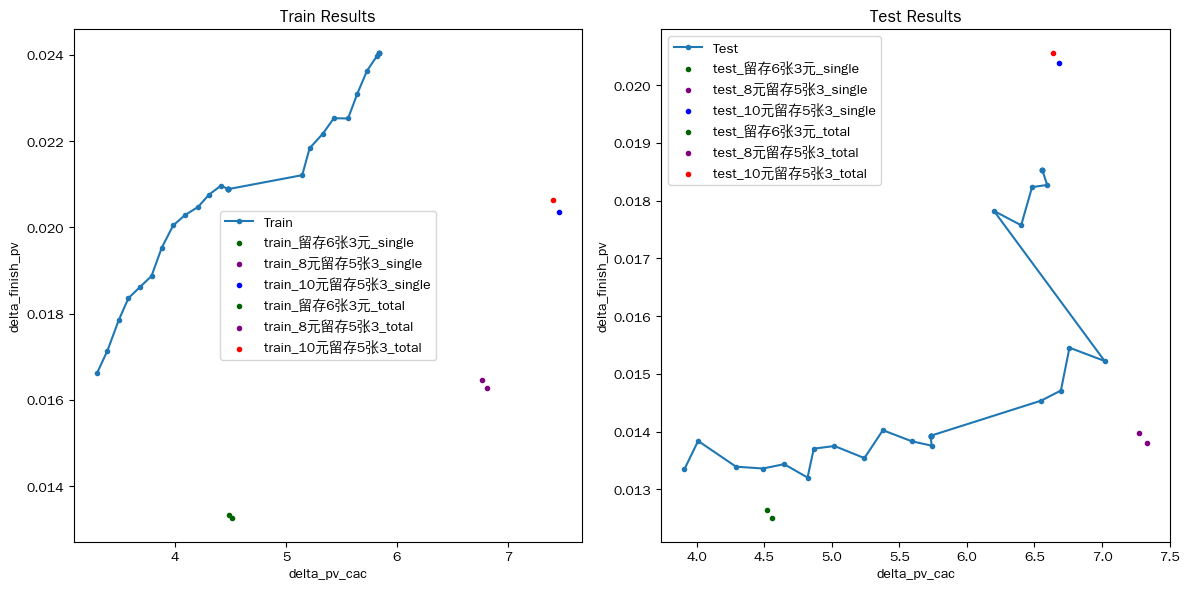


========== euen: running euen_v2 | s2 ==========
columns: ['cost_1', 'left1053', 'left63', 'left853_minus_left63']
all_columns: ['cost_1_per', 'left1053_per', 'left63_per', 'left853_minus_left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']


,cost_1_per,left1053_per,left63_per,counts
0,0.1,0.1,0.1,48312
11,0.1,0.2,0.2,26254
111,0.2,0.2,0.2,30812
122,0.2,0.3,0.3,27001
222,0.3,0.3,0.3,25005
233,0.3,0.4,0.4,23765
333,0.4,0.4,0.4,22757
344,0.4,0.5,0.5,21044
444,0.5,0.5,0.5,24318
455,0.5,0.6,0.6,20090


['left853_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left853_minus_left63_per,left63_per,counts
0,0.1,0.1,26886
88,0.9,0.9,15046


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
1,0.2,26343
2,0.3,32004
3,0.4,37358
4,0.5,38379
6,0.7,21173



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,8196
5,0.6,18780
7,0.8,18484
8,0.9,7170
9,1.0,8828


[22  7 13 18 16 24  1 25  5 17 15 11  2 23 21  9 20 19  8  3 12 14  4 10
  0  6]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   6427        7.0       32.0      62.595   
1              0   8元留存5张3   6419       16.0       95.0      26.098   
2              0      DS空白  26118       37.0      115.0       0.000   
3              0    留存6张3元   9348       22.0      121.0      54.501   
4              1  10元留存5张3   3412        6.0       21.0      50.288   
..           ...       ...    ...        ...        ...         ...   
99            24    留存6张3元   4078       55.0      147.0     192.165   
100           25  10元留存5张3   7895      145.0      398.0    1442.331   
101           25   8元留存5张3   7736      131.0      409.0     964.496   
102           25      DS空白  33802      399.0     1241.0      65.454   
103           25    留存6张3元  12025      176.0      466.0     714.676   

     delta_cvr  delta_cac  
0     0.000576  16.9115

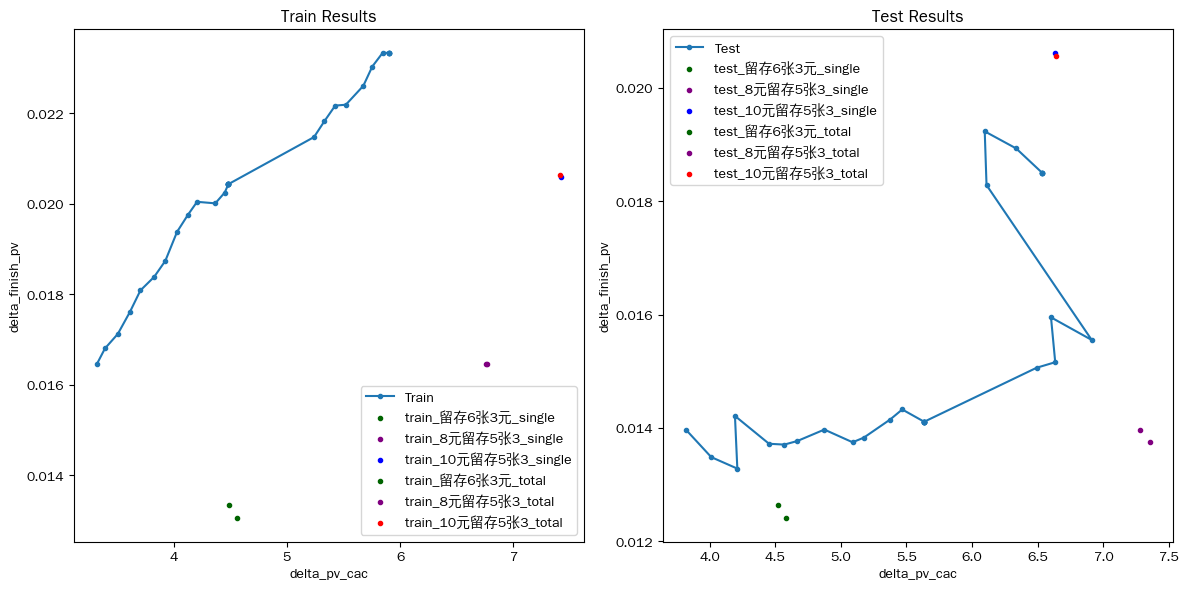


========== euen: running euen_v2 | s3 ==========
columns: ['cost_1', 'left1053', 'left63']
all_columns: ['cost_1_per', 'left1053_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']
(837501, 40) (843787, 40)
['cost_1_per', 'left1053_p

,cost_1_per,left1053_per,left63_per,counts
0,0.1,0.1,0.1,48312
11,0.1,0.2,0.2,26254
111,0.2,0.2,0.2,30812
122,0.2,0.3,0.3,27001
222,0.3,0.3,0.3,25005
233,0.3,0.4,0.4,23765
333,0.4,0.4,0.4,22757
344,0.4,0.5,0.5,21044
444,0.5,0.5,0.5,24318
455,0.5,0.6,0.6,20090


['left1053_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_per,left63_per,counts
0,0.1,0.1,27297
12,0.2,0.3,13288
23,0.3,0.4,16673
32,0.4,0.3,11215
34,0.4,0.5,18714
43,0.5,0.4,13167
54,0.6,0.5,12468
56,0.6,0.7,10803


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
1,0.2,26343
8,0.9,22216



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,7785
2,0.3,7501
3,0.4,7518
4,0.5,7197
5,0.6,18780
6,0.7,10370
7,0.8,18484
9,1.0,8828


[28  7 13 20 16 25  1 22  5 17 15 11  2 23  9 26 27  8  3 12 14 21  4 10
  0 24 19 18  6]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   6427        7.0       32.0      62.595   
1              0   8元留存5张3   6419       16.0       95.0      26.098   
2              0      DS空白  26118       37.0      115.0       0.000   
3              0    留存6张3元   9348       22.0      121.0      54.501   
4              1  10元留存5张3   3412        6.0       21.0      50.288   
..           ...       ...    ...        ...        ...         ...   
111           27    留存6张3元   4395       90.0      249.0     407.190   
112           28  10元留存5张3  11058      217.0      609.0    1816.258   
113           28   8元留存5张3  11031      186.0      566.0    1155.250   
114           28      DS空白  47385      611.0     1937.0     110.637   
115           28    留存6张3元  16989      241.0      657.0     919.323   

     delta_cvr  delta_cac  
0     0.000576

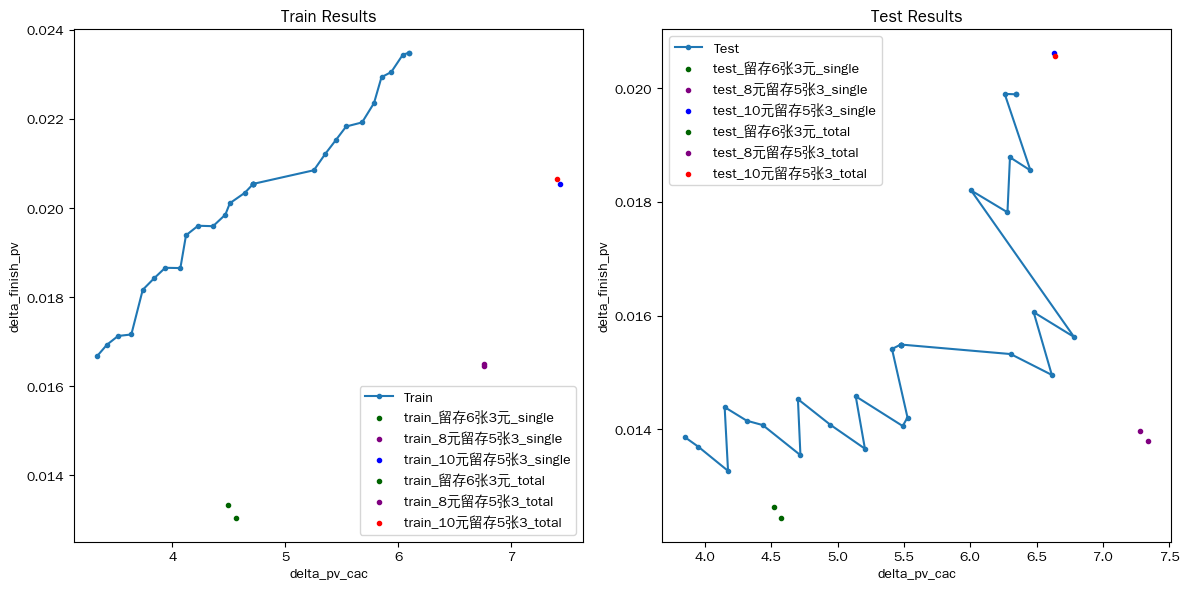


========== euen: running euen_v2 | s4 ==========
columns: ['cost_1', 'left853', 'left63']
all_columns: ['cost_1_per', 'left853_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']
(837501, 40) (843787, 40)
['cost_1_per', 'left853_per'

,cost_1_per,left853_per,left63_per,counts
0,0.1,0.1,0.1,40626
11,0.1,0.2,0.2,26651
111,0.2,0.2,0.2,26387
122,0.2,0.3,0.3,27934
222,0.3,0.3,0.3,24989
233,0.3,0.4,0.4,26085
333,0.4,0.4,0.4,25673
344,0.4,0.5,0.5,23968
444,0.5,0.5,0.5,29033
455,0.5,0.6,0.6,20003


['left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left853_per,left63_per,counts
0,0.1,0.1,33426
12,0.2,0.3,10618
21,0.3,0.2,13050
23,0.3,0.4,10295
32,0.4,0.3,14398
34,0.4,0.5,10318
43,0.5,0.4,14379
45,0.5,0.6,10562
54,0.6,0.5,12763
88,0.9,0.9,10702


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage

============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,9342
1,0.2,17321
2,0.3,6071
3,0.4,7448
4,0.5,7659
5,0.6,12770
6,0.7,14197
7,0.8,9325
8,0.9,2880
9,1.0,5124


[27  7 12 20 15  1 21  5 16 14 10 18  8  9 26 25  3 13  6  4 11 17  0  2
 23 24 22 19]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   5416        6.0       25.0      59.410   
1              0   8元留存5张3   5412       13.0       71.0      24.514   
2              0      DS空白  21915       36.0      107.0       0.000   
3              0    留存6张3元   7883       19.0      105.0      52.345   
4              1  10元留存5张3   3506        3.0        4.0      25.266   
..           ...       ...    ...        ...        ...         ...   
107           26    留存6张3元   2080       40.0      106.0     137.810   
108           27  10元留存5张3  12010      187.0      521.0    1494.116   
109           27   8元留存5张3  12035      167.0      560.0    1011.957   
110           27      DS空白  49994      526.0     1675.0      80.324   
111           27    留存6张3元  18098      214.0      621.0     732.862   

     delta_cvr  delta_cac  
0    -0.000267 -4

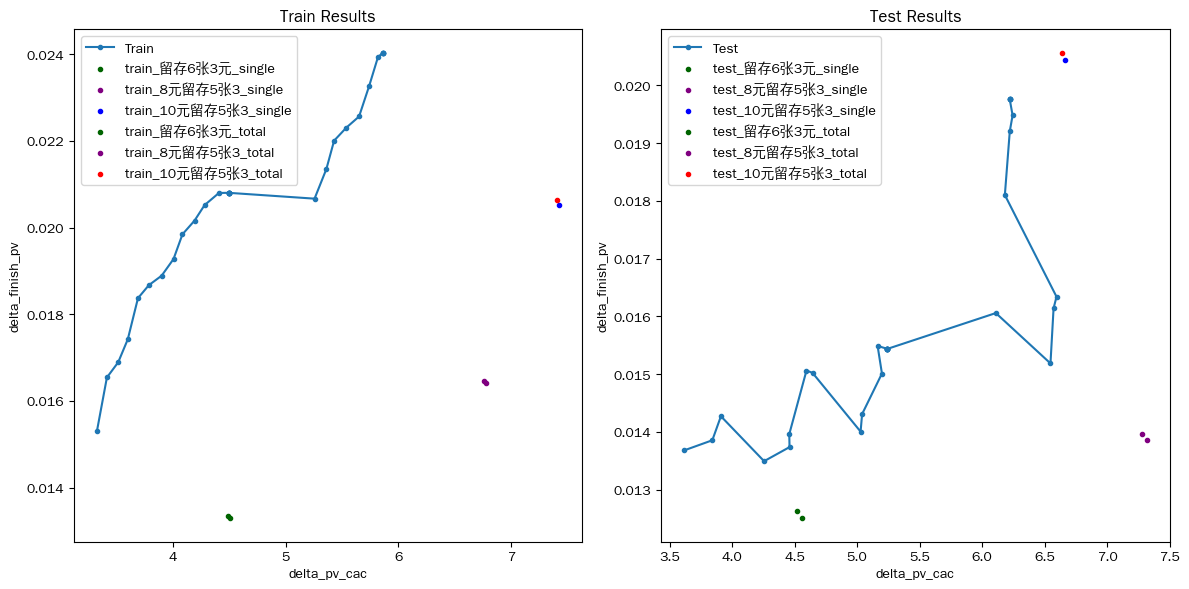


========== euen: running euen_v2 | s5 ==========
columns: ['cost_1', 'left1053_minus_left63', 'left63', 'left853']
all_columns: ['cost_1_per', 'left1053_minus_left63_per', 'left63_per', 'left853_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']


,cost_1_per,left1053_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,15822
10,0.1,0.2,0.1,13513
11,0.1,0.2,0.2,10134
505,0.6,0.1,0.6,10510
666,0.7,0.7,0.7,21347
767,0.8,0.7,0.8,16384
777,0.8,0.8,0.8,39487
878,0.9,0.8,0.9,14767
888,0.9,0.9,0.9,50635
989,1.0,0.9,1.0,10240


['left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left853_per,left63_per,counts
0,0.1,0.1,49067
11,0.2,0.2,53313
12,0.2,0.3,10618
21,0.3,0.2,11827
22,0.3,0.3,58334
23,0.3,0.4,10295
32,0.4,0.3,14398
33,0.4,0.4,57519
34,0.4,0.5,10318
43,0.5,0.4,14379


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage

============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,4992
1,0.2,8135
2,0.3,660
3,0.4,1687
4,0.5,2179
5,0.6,7396
6,0.7,7528
7,0.8,3358
8,0.9,1635
9,1.0,4675


[28 21  4 18 16 27 25  2 17  8  9  6  7 10 24 12 11 23 14 26 13  3  5 20
 22  0 19  1 15]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   2181        2.0       13.0       7.163   
1              0   8元留存5张3   2130        5.0       23.0       4.546   
2              0      DS空白   8365        9.0       43.0       0.000   
3              0    留存6张3元   3146        6.0       41.0      34.503   
4              1  10元留存5张3   1796        0.0        0.0       6.168   
..           ...       ...    ...        ...        ...         ...   
111           27    留存6张3元   3354       95.0      240.0     301.272   
112           28  10元留存5张3   5481      101.0      268.0     775.675   
113           28   8元留存5张3   5468       87.0      282.0     498.842   
114           28      DS空白  22731      310.0      970.0      35.000   
115           28    留存6张3元   8565      124.0      356.0     381.782   

     delta_cvr  delta_cac  
0     0.000820

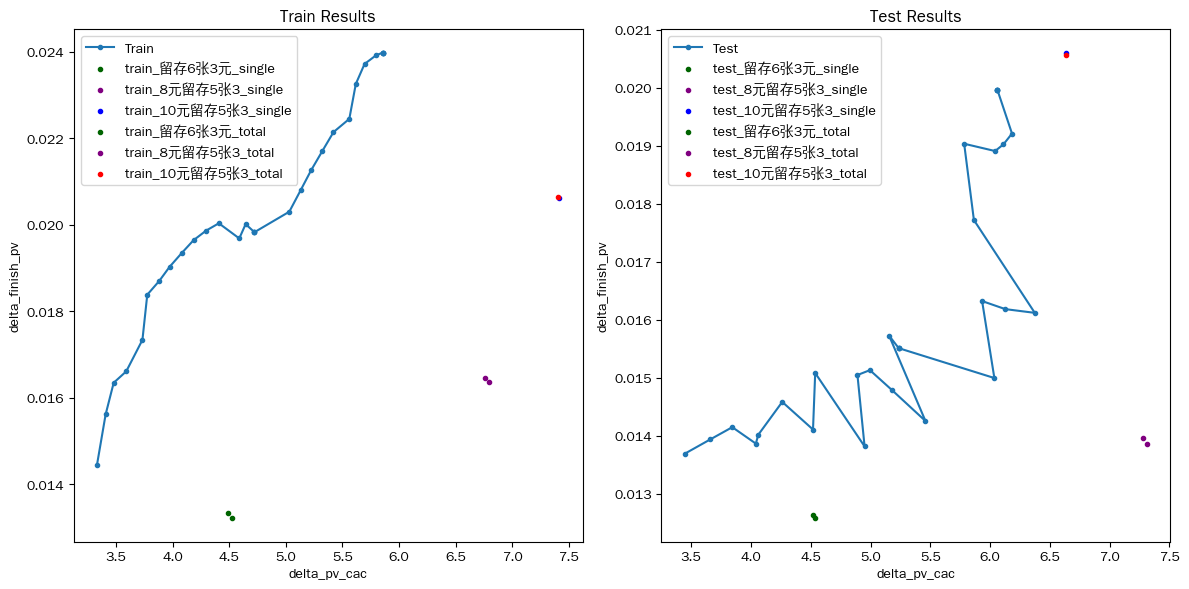


========== euen: running euen_v3 | s1 ==========
columns: ['cost_1', 'left1053', 'left853', 'left63']
all_columns: ['cost_1_per', 'left1053_per', 'left853_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']
(837501, 41) (843787, 41)


,cost_1_per,left1053_per,left853_per,left63_per,counts
0,0.1,0.1,0.1,0.1,53897
111,0.1,0.2,0.2,0.2,17056
1111,0.2,0.2,0.2,0.2,26134
1222,0.2,0.3,0.3,0.3,16293
2111,0.3,0.2,0.2,0.2,11433
2222,0.3,0.3,0.3,0.3,16996
2333,0.3,0.4,0.4,0.4,12399
3222,0.4,0.3,0.3,0.3,10231
3333,0.4,0.4,0.4,0.4,14928
3444,0.4,0.5,0.5,0.5,12066


['left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left853_per,left63_per,counts
0,0.1,0.1,22936
11,0.2,0.2,12793
12,0.2,0.3,10359
22,0.3,0.3,16020
23,0.3,0.4,13359
32,0.4,0.3,13341
33,0.4,0.4,26350
34,0.4,0.5,15371
43,0.5,0.4,15989
44,0.5,0.5,24609


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage

============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,6448
1,0.2,16235
2,0.3,551
3,0.4,896
4,0.5,1400
5,0.6,1570
6,0.7,10063
7,0.8,4928
8,0.9,7491
9,1.0,2075


[13  8 15  1 34 17 14  2 29 18 38 21 19 20 10 25 32 23 22  5 12 36 40 35
 31 26 27  7 11 16  0  9 28 33  4  3 30 37 24  6 39]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   7232        7.0       20.0      48.380   
1              0   8元留存5张3   7361       14.0      104.0      34.592   
2              0      DS空白  28959       24.0       76.0       0.000   
3              0    留存6张3元  10345        8.0       63.0      30.160   
4              1  10元留存5张3   2199        3.0       17.0      31.980   
..           ...       ...    ...        ...        ...         ...   
159           39    留存6张3元   2455       78.0      219.0     394.148   
160           40  10元留存5张3   6690      127.0      376.0     886.235   
161           40   8元留存5张3   6763       98.0      323.0     533.155   
162           40      DS空白  28162      330.0     1007.0      45.000   
163           40    留存6张3元  10042      140.0      394.0     433.410   

     d

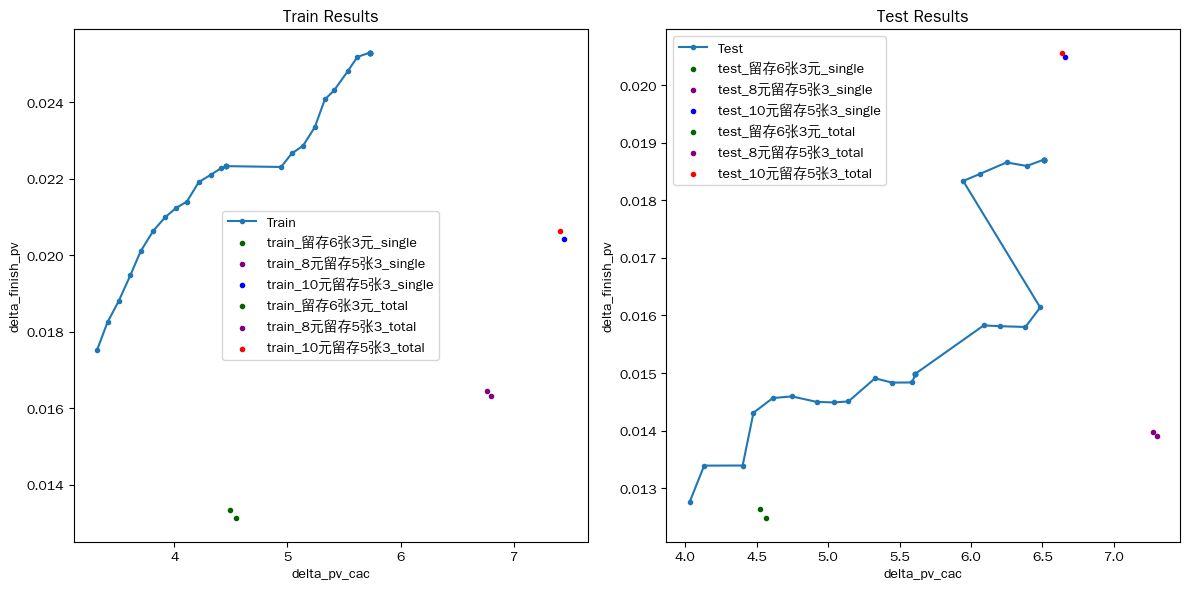


========== euen: running euen_v3 | s2 ==========
columns: ['cost_1', 'left1053', 'left63', 'left853_minus_left63']
all_columns: ['cost_1_per', 'left1053_per', 'left63_per', 'left853_minus_left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']


,cost_1_per,left1053_per,left63_per,counts
0,0.1,0.1,0.1,56104
11,0.1,0.2,0.2,19770
100,0.2,0.1,0.1,10793
111,0.2,0.2,0.2,32008
122,0.2,0.3,0.3,22745
211,0.3,0.2,0.2,13781
222,0.3,0.3,0.3,23640
233,0.3,0.4,0.4,20852
322,0.4,0.3,0.3,13158
333,0.4,0.4,0.4,21651


['left853_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================

No Large Combinations in this stage
['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
2,0.3,24248
3,0.4,28054
4,0.5,29602
5,0.6,28466
6,0.7,25106
7,0.8,27834
8,0.9,20483



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
1,0.2,23291



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,6448
2,0.3,9356
3,0.4,10825
4,0.5,10649
5,0.6,1570
6,0.7,18384
7,0.8,4928
8,0.9,12231
9,1.0,9603


[15  8 17  1 37 20 16  2 21 26 22 11 25 31  5 23 14 34 33 29 10  3 28  7
 13 12 19  6  0  9 27 32  4 30 35 24 36 18]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   7374        7.0       20.0      48.657   
1              0   8元留存5张3   7509       14.0      104.0      34.655   
2              0      DS空白  29562       27.0       85.0       0.000   
3              0    留存6张3元  10529        8.0       63.0      30.578   
4              1  10元留存5张3   2445        3.0       17.0      33.276   
..           ...       ...    ...        ...        ...         ...   
147           36    留存6张3元   4589       15.0       56.0      55.634   
148           37  10元留存5张3  10746      207.0      590.0    1585.188   
149           37   8元留存5张3  10800      179.0      552.0    1165.292   
150           37      DS空白  46423      547.0     1627.0      70.183   
151           37    留存6张3元  16025      226.0      626.0     865.137   

     delta_cvr 

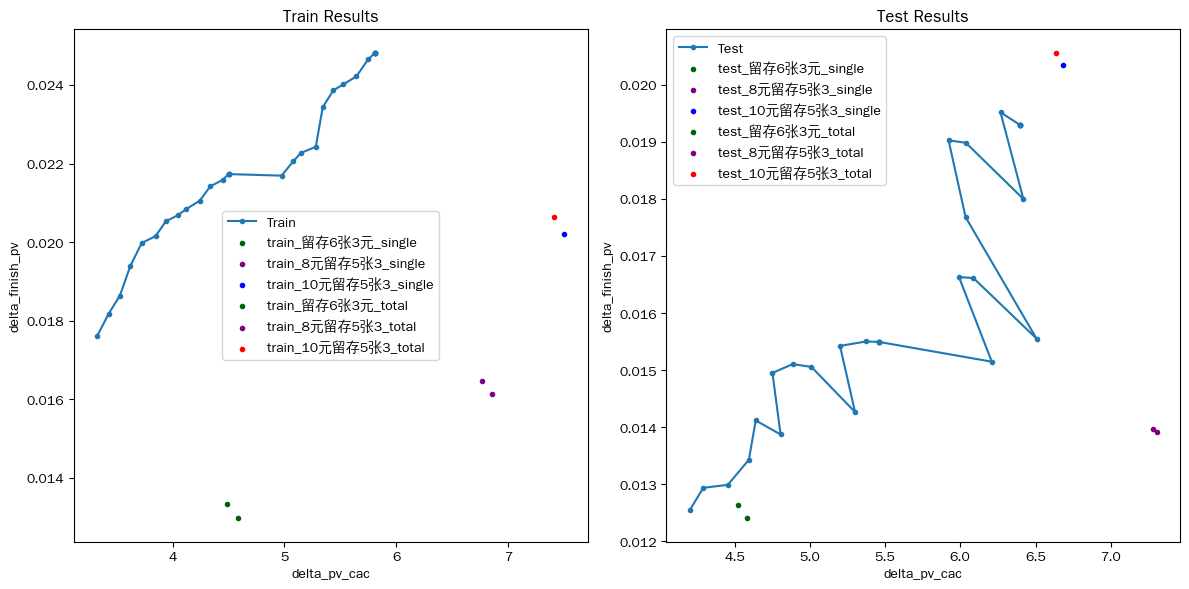


========== euen: running euen_v3 | s5 ==========
columns: ['cost_1', 'left1053_minus_left63', 'left63', 'left853']
all_columns: ['cost_1_per', 'left1053_minus_left63_per', 'left63_per', 'left853_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']


,cost_1_per,left1053_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,54508
11,0.1,0.2,0.2,15720
100,0.2,0.1,0.1,10539
111,0.2,0.2,0.2,26097
122,0.2,0.3,0.3,16807
211,0.3,0.2,0.2,11889
222,0.3,0.3,0.3,18480
223,0.3,0.3,0.4,10402
233,0.3,0.4,0.4,14777
322,0.4,0.3,0.3,11316


['left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left853_per,left63_per,counts
0,0.1,0.1,15031
11,0.2,0.2,23135
22,0.3,0.3,26768
33,0.4,0.4,17572
44,0.5,0.5,16857
45,0.5,0.6,10629
55,0.6,0.6,22425
66,0.7,0.7,25402
77,0.8,0.8,36641
88,0.9,0.9,28246


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage

============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,3203
1,0.2,6810
2,0.3,10420
3,0.4,11975
4,0.5,13230
5,0.6,5396
6,0.7,10713
7,0.8,8215
8,0.9,3783
9,1.0,9819


[20 10 36  1 35 37 21  3 32 25 29 27 19 28 14 26  4 34 30 38 18 33 13  9
 24 17 16 23  7  0 12  5  8 22  6 15 31  2 11]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   7339        7.0       20.0      48.618   
1              0   8元留存5张3   7415       15.0      105.0      34.655   
2              0      DS空白  29290       25.0       93.0       0.000   
3              0    留存6张3元  10464        8.0       63.0      30.521   
4              1  10元留存5张3   2055        4.0       18.0      42.322   
..           ...       ...    ...        ...        ...         ...   
151           37    留存6张3元   5585      153.0      333.0     435.495   
152           38  10元留存5张3  10561      183.0      525.0    1548.162   
153           38   8元留存5张3  10730      161.0      443.0     978.687   
154           38      DS空白  45994      487.0     1436.0      40.344   
155           38    留存6张3元  16279      194.0      557.0     808.276   

     delta_c

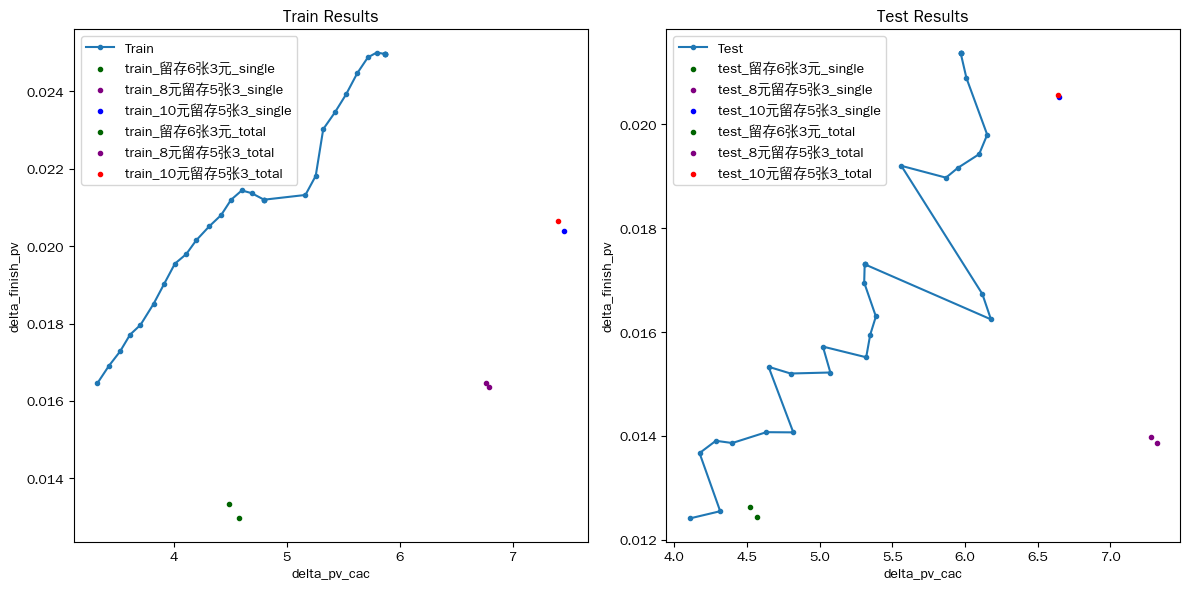

In [32]:
# 搜索 EUEN 的最佳 stage
euen_stage_results = run_stage_search(
    euen_scheme_dfs,
    euen_stage_configs,
    search_name='euen'
)


========== eeuen: running eeuen_v2 | s1 ==========
columns: ['exposure_prob', 'left1053_minus_left63', 'left853_minus_left63', 'left63', 'cost_1', 'left853']
all_columns: ['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per', 'cost_1_per', 'left853_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-0

,exposure_prob_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
20,0.1,0.1,0.3,0.1,11411
30,0.1,0.1,0.4,0.1,12643
40,0.1,0.1,0.5,0.1,10218
7999,0.8,1.0,1.0,1.0,10161
8999,0.9,1.0,1.0,1.0,15994
9999,1.0,1.0,1.0,1.0,12790


['cost_1_per', 'left1053_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left1053_minus_left63_per,left63_per,counts
11,0.1,0.2,0.2,16976
132,0.2,0.4,0.3,11522
888,0.9,0.9,0.9,11573
898,0.9,1.0,0.9,12378
989,1.0,0.9,1.0,15975


['cost_1_per', 'left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,34248
1,0.2,34799
2,0.3,37438
3,0.4,38820
4,0.5,34850
5,0.6,33046
6,0.7,34327
7,0.8,32261



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
8,0.9,18747
9,1.0,8414


[31 21 27  6 28 24 18 30  4  3  2 10  9  5 19 32 29 20 15 26 35 17 16 14
 22 33 34 11 23 13  0 12 25  8  7  1]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1567        2.0       15.0       3.665   
1              0   8元留存5张3   1487        6.0       13.0       2.659   
2              0      DS空白   6118       11.0       41.0       0.000   
3              0    留存6张3元   2239        2.0        4.0       3.118   
4              1  10元留存5张3   1988        6.0       23.0      17.101   
..           ...       ...    ...        ...        ...         ...   
139           34    留存6张3元   6181       89.0      266.0     415.717   
140           35  10元留存5张3   3617       93.0      297.0    1083.684   
141           35   8元留存5张3   3445       69.0      196.0     708.086   
142           35      DS空白  14650      155.0      358.0      40.506   
143           35    留存6张3元   5449      117.0      325.0     715.397   

     delta_cvr  delta

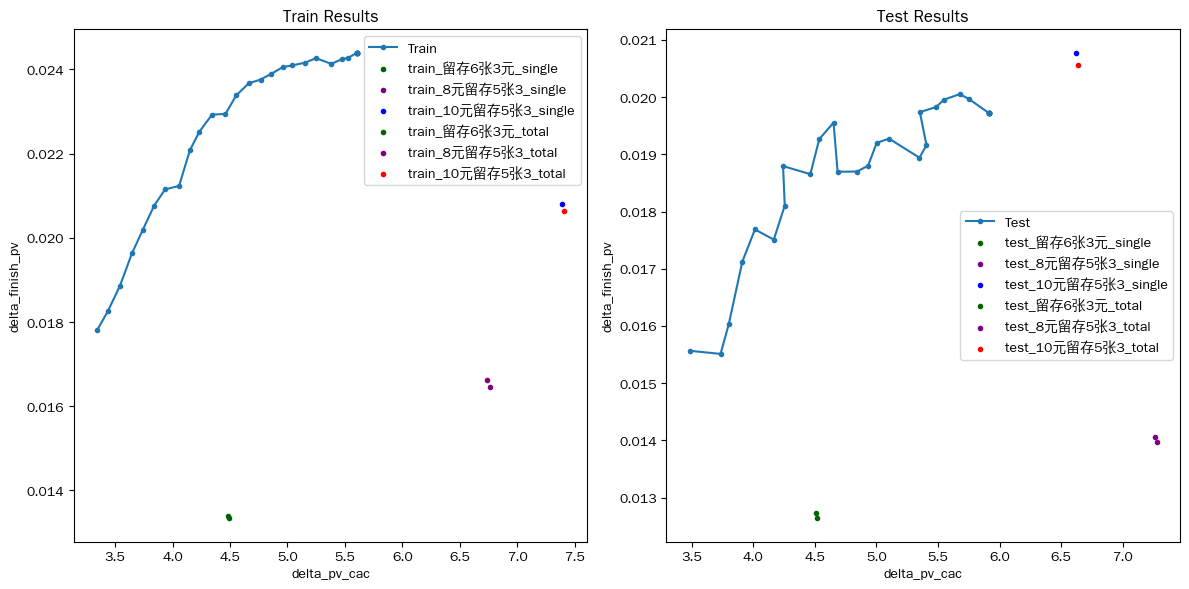


========== eeuen: running eeuen_v2 | s2 ==========
columns: ['exposure_prob', 'left1053_minus_left63', 'left853_minus_left63', 'left63', 'cost_1', 'left1053', 'left853']
all_columns: ['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per', 'cost_1_per', 'left1053_per', 'left853_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08

,exposure_prob_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
20,0.1,0.1,0.3,0.1,11411
30,0.1,0.1,0.4,0.1,12643
40,0.1,0.1,0.5,0.1,10218
7999,0.8,1.0,1.0,1.0,10161
8999,0.9,1.0,1.0,1.0,15994
9999,1.0,1.0,1.0,1.0,12790


['cost_1_per', 'left1053_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left1053_per,left63_per,counts
0,0.1,0.1,0.1,12180
1,0.1,0.1,0.2,13595
11,0.1,0.2,0.2,22871
111,0.2,0.2,0.2,14287
122,0.2,0.3,0.3,21161
233,0.3,0.4,0.4,17366
344,0.4,0.5,0.5,15357
444,0.5,0.5,0.5,10306
455,0.5,0.6,0.6,14601
555,0.6,0.6,0.6,12006


['cost_1_per', 'left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,36315
1,0.2,33004
2,0.3,34979
3,0.4,36014
4,0.5,32202
5,0.6,29580
6,0.7,29439
7,0.8,33959
8,0.9,22266



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
9,1.0,15488


[32 19 29 28 20 13 31  4  3  2 37 23  5 14 33 30 15 27 22 36 12 35 11 26
 18 34 24 21 10  7 16  0 17  8  6 25  1  9]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1567        2.0       15.0       3.665   
1              0   8元留存5张3   1487        6.0       13.0       2.659   
2              0      DS空白   6118       11.0       41.0       0.000   
3              0    留存6张3元   2239        2.0        4.0       3.118   
4              1  10元留存5张3   1988        6.0       23.0      17.101   
..           ...       ...    ...        ...        ...         ...   
147           36    留存6张3元   4353      160.0      382.0     630.534   
148           37  10元留存5张3   1965       60.0      172.0     634.266   
149           37   8元留存5张3   2030       44.0      125.0     529.645   
150           37      DS空白   8405       62.0      162.0      15.021   
151           37    留存6张3元   3088       76.0      208.0     478.580   

     delta_cvr 

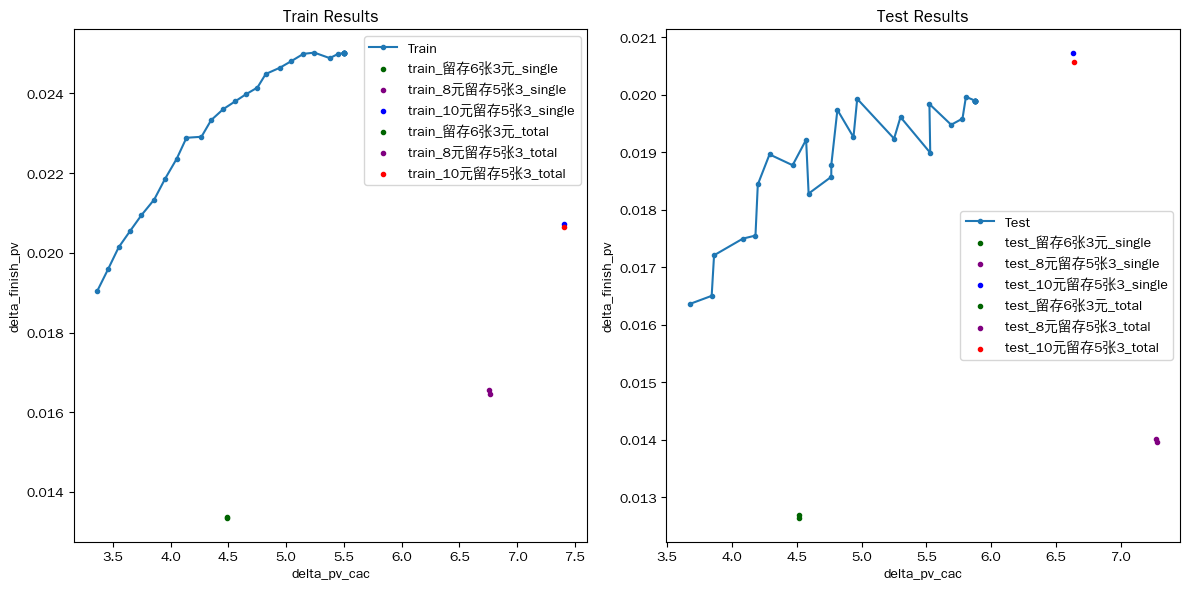


========== eeuen: running eeuen_v2 | s3 ==========
columns: ['exposure_prob', 'left1053_minus_left63', 'left853_minus_left63', 'left63', 'cost_1']
all_columns: ['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per', 'cost_1_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026

,exposure_prob_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
20,0.1,0.1,0.3,0.1,11411
30,0.1,0.1,0.4,0.1,12643
40,0.1,0.1,0.5,0.1,10218
7999,0.8,1.0,1.0,1.0,10161
8999,0.9,1.0,1.0,1.0,15994
9999,1.0,1.0,1.0,1.0,12790


['exposure_prob_per', 'left1053_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,exposure_prob_per,left1053_minus_left63_per,left63_per,counts
1,0.1,0.1,0.2,10255
111,0.2,0.2,0.2,14784
121,0.2,0.3,0.2,12084
232,0.3,0.4,0.3,10105
989,1.0,0.9,1.0,12217


['cost_1_per', 'left853_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,cost_1_per,left853_minus_left63_per,left63_per,counts
10,0.1,0.2,0.1,12250
122,0.2,0.3,0.3,10940
243,0.3,0.5,0.4,10818
354,0.4,0.6,0.5,13014
464,0.5,0.7,0.5,10803
465,0.5,0.7,0.6,14132
475,0.5,0.8,0.6,10272
575,0.6,0.8,0.6,13223
576,0.6,0.8,0.7,12528
686,0.7,0.9,0.7,12094


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,36245
1,0.2,46634
2,0.3,62729
3,0.4,73111
4,0.5,60247
5,0.6,46437
6,0.7,59216
7,0.8,42985
8,0.9,43484
9,1.0,21524



============================== Final Small Combinations ==============================

No Small Combinations in final stage
[31 19 29 27 22 30  4  3  2 36 25  5 17 15 32 28 16 35 34 33 24 11 21  9
  6 14 10  0 20 12  8 13 18 23  1 26  7]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1567        2.0       15.0       3.665   
1              0   8元留存5张3   1487        6.0       13.0       2.659   
2              0      DS空白   6118       11.0       41.0       0.000   
3              0    留存6张3元   2239        2.0        4.0       3.118   
4              1  10元留存5张3   1988        6.0       23.0      17.101   
..           ...       ...    ...        ...        ...         ...   
143           35    留存6张3元   8453      182.0      453.0     920.364   
144           36  10元留存5张3   2743      128.0      389.0    1317.668   
145           36   8元留存5张3   2757      122.0      372.0    1177.026   
146           36      DS空白  11629  

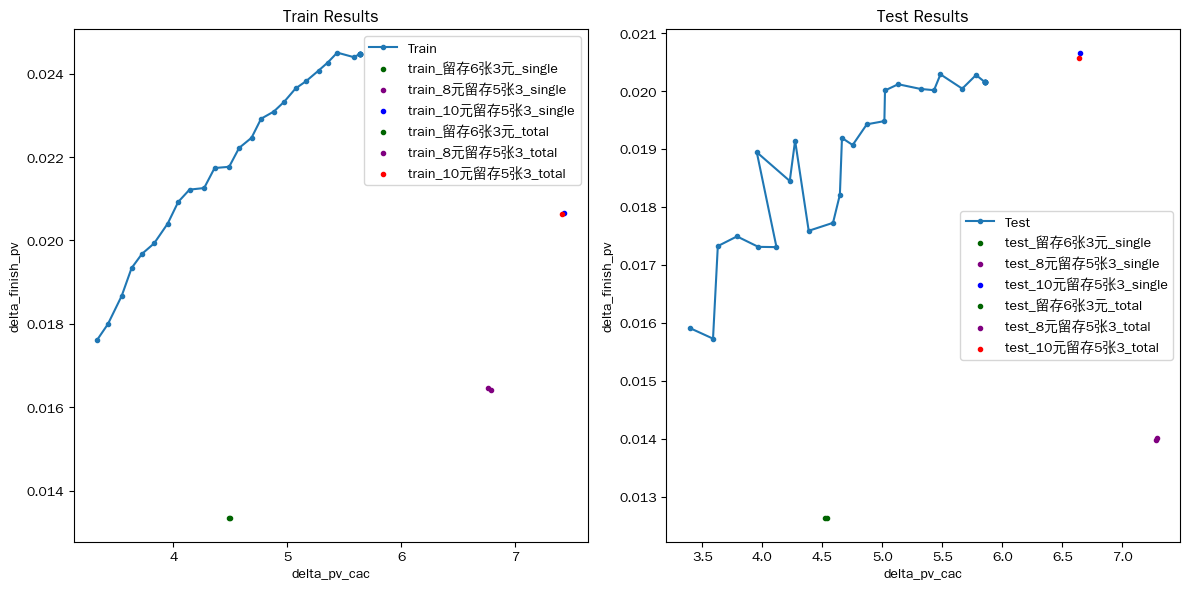


========== eeuen: running eeuen_v2 | s4 ==========
columns: ['exposure_prob', 'left1053_minus_left63', 'left853_minus_left63', 'left63', 'cost_1']
all_columns: ['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per', 'cost_1_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026

,exposure_prob_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
20,0.1,0.1,0.3,0.1,11411
30,0.1,0.1,0.4,0.1,12643
40,0.1,0.1,0.5,0.1,10218
7999,0.8,1.0,1.0,1.0,10161
8999,0.9,1.0,1.0,1.0,15994
9999,1.0,1.0,1.0,1.0,12790


['cost_1_per', 'left1053_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left1053_minus_left63_per,left63_per,counts
11,0.1,0.2,0.2,16976
132,0.2,0.4,0.3,11522
888,0.9,0.9,0.9,11573
898,0.9,1.0,0.9,12378
989,1.0,0.9,1.0,15975


['cost_1_per', 'left853_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,36245
1,0.2,55770
2,0.3,72252
3,0.4,73111
4,0.5,60247
5,0.6,46437
6,0.7,59216
7,0.8,42985
8,0.9,36905



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
9,1.0,17822


[29 18 26  6 25 21 28  4  3  2 10 23  5 16 14 30 27 15 33 32 31 34 22 11
 20 13  0 19 12 17  8  7  1  9 24]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1567        2.0       15.0       3.665   
1              0   8元留存5张3   1487        6.0       13.0       2.659   
2              0      DS空白   6118       11.0       41.0       0.000   
3              0    留存6张3元   2239        2.0        4.0       3.118   
4              1  10元留存5张3   1988        6.0       23.0      17.101   
..           ...       ...    ...        ...        ...         ...   
135           33    留存6张3元   7216      153.0      388.0     758.583   
136           34  10元留存5张3   2251      109.0      320.0    1052.658   
137           34   8元留存5张3   2256      103.0      298.0     971.509   
138           34      DS空白   9637      178.0      480.0      15.000   
139           34    留存6张3元   3678      173.0      452.0     776.347   

     delta_cvr  delta_ca

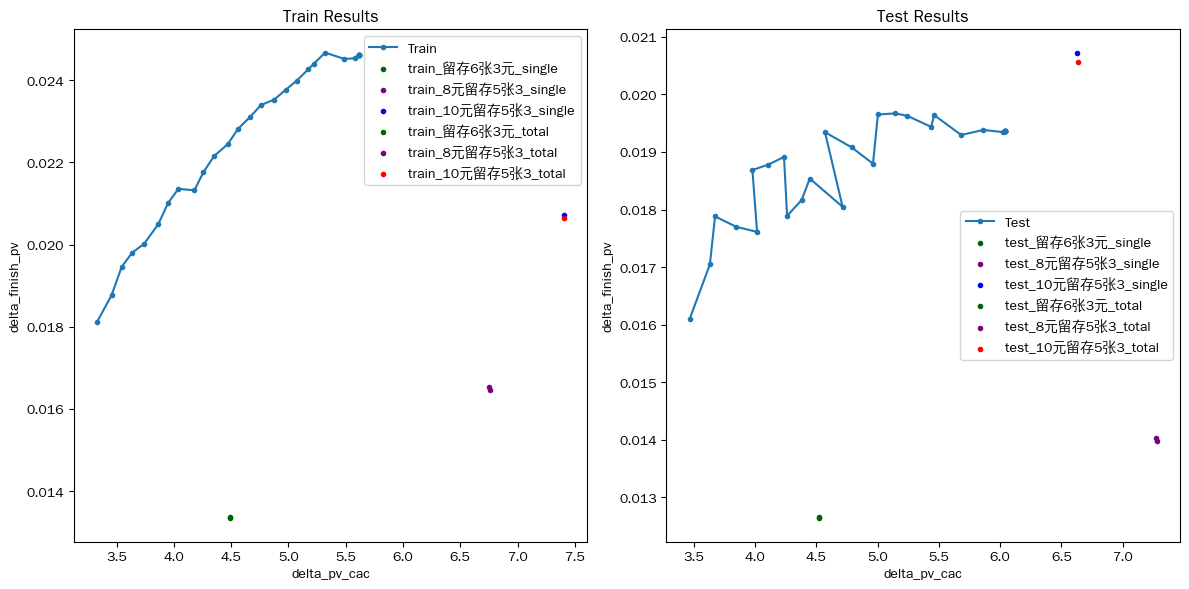


========== eeuen: running eeuen_v2 | s5 ==========
columns: ['exposure_prob', 'left1053_minus_left63', 'left853_minus_left63', 'left63', 'cost_1', 'left853']
all_columns: ['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per', 'cost_1_per', 'left853_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-0

,exposure_prob_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
20,0.1,0.1,0.3,0.1,11411
30,0.1,0.1,0.4,0.1,12643
40,0.1,0.1,0.5,0.1,10218
7999,0.8,1.0,1.0,1.0,10161
8999,0.9,1.0,1.0,1.0,15994
9999,1.0,1.0,1.0,1.0,12790


['exposure_prob_per', 'left853_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,exposure_prob_per,left853_minus_left63_per,left63_per,counts
111,0.2,0.2,0.2,15259
121,0.2,0.3,0.2,10350
575,0.6,0.8,0.6,10436
686,0.7,0.9,0.7,10355
687,0.7,0.9,0.8,10373
787,0.8,0.9,0.8,11399
798,0.8,1.0,0.9,12894
807,0.9,0.1,0.8,11688
907,1.0,0.1,0.8,10587
908,1.0,0.1,0.9,25676


['cost_1_per', 'left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,34248
1,0.2,31394
2,0.3,40575
3,0.4,38820
4,0.5,34850
5,0.6,29737
6,0.7,29039



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
7,0.8,12672
8,0.9,5488
9,1.0,5334


[38 27 34 18 35 10 24 37  4  3  2 31 15  5  8 39 25 36 26 21 33 23 30 22
 20 28 32 41 13 40 11 17 29 19 12 16  0  9  6  7  1 14]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1567        2.0       15.0       3.665   
1              0   8元留存5张3   1487        6.0       13.0       2.659   
2              0      DS空白   6118       11.0       41.0       0.000   
3              0    留存6张3元   2239        2.0        4.0       3.118   
4              1  10元留存5张3   1988        6.0       23.0      17.101   
..           ...       ...    ...        ...        ...         ...   
163           40    留存6张3元   5592       79.0      209.0     326.092   
164           41  10元留存5张3   3005      128.0      391.0    1342.826   
165           41   8元留存5张3   2987      115.0      316.0     744.021   
166           41      DS空白  12872      306.0      766.0      45.162   
167           41    留存6张3元   4630      154.0      452.0     635.485   

   

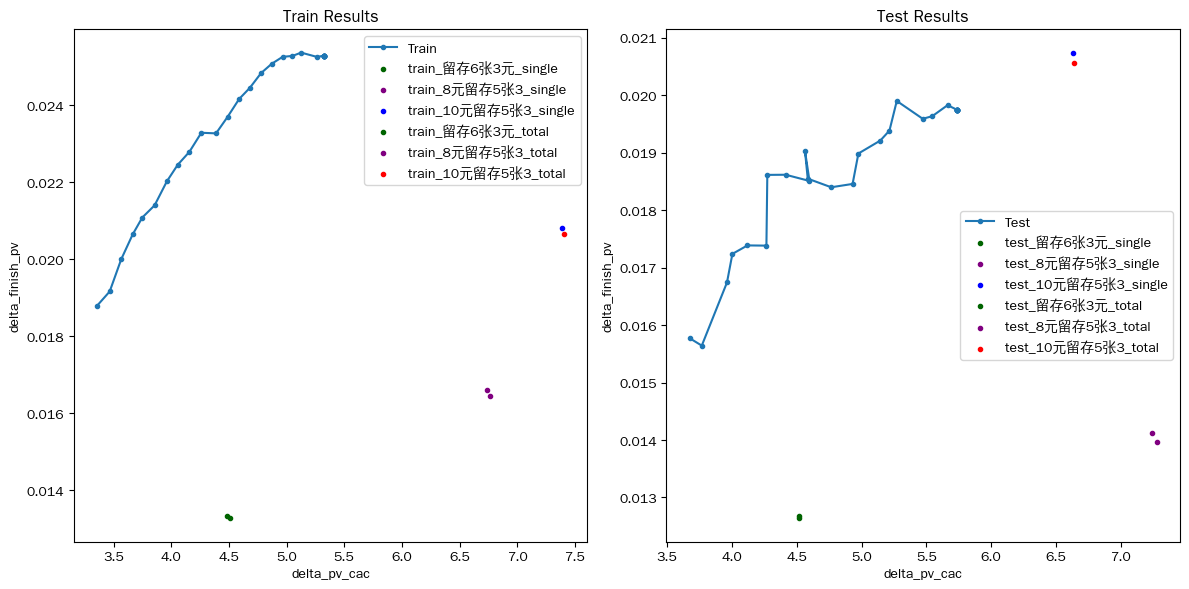


========== eeuen: running eeuen_v3 | s1 ==========
columns: ['exposure_prob', 'left1053_minus_left63', 'left853_minus_left63', 'left63', 'cost_1', 'left853']
all_columns: ['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per', 'cost_1_per', 'left853_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-0

,exposure_prob_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
12,0.1,0.1,0.2,0.3,13326
7999,0.8,1.0,1.0,1.0,13930
8999,0.9,1.0,1.0,1.0,18773
9888,1.0,0.9,0.9,0.9,12240
9899,1.0,0.9,1.0,1.0,10230
9999,1.0,1.0,1.0,1.0,18491


['cost_1_per', 'left1053_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left1053_minus_left63_per,left63_per,counts
1,0.1,0.1,0.2,15854
12,0.1,0.2,0.3,10548
123,0.2,0.3,0.4,10403
334,0.4,0.4,0.5,10242
445,0.5,0.5,0.6,16503
556,0.6,0.6,0.7,17751
656,0.7,0.6,0.7,10874
666,0.7,0.7,0.7,16184
667,0.7,0.7,0.8,11955
767,0.8,0.7,0.8,15573


['cost_1_per', 'left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,49667
1,0.2,52004
2,0.3,44841
3,0.4,46255
4,0.5,47344
5,0.6,44144
6,0.7,39100
7,0.8,22392



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
8,0.9,14314
9,1.0,6924


[34 10 23 33 14 38 22  2  1 36  6  4 41  5 39 37 28  9 29 15 35 27 26 16
 18 11 13 31 32 40  7  8  3 12 20 17  0 24 30 19 25 21]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1851        4.0        9.0       3.581   
1              0   8元留存5张3   1876        5.0       15.0       2.280   
2              0      DS空白   6836        8.0       19.0       0.000   
3              0    留存6张3元   2763        6.0       41.0      28.238   
4              1  10元留存5张3   1862      156.0      409.0    1316.166   
..           ...       ...    ...        ...        ...         ...   
163           40    留存6张3元   4306       62.0      163.0     306.626   
164           41  10元留存5张3   2754       95.0      282.0    1042.229   
165           41   8元留存5张3   2741       95.0      320.0     760.021   
166           41      DS空白  11532      227.0      555.0      25.000   
167           41    留存6张3元   4211      128.0      346.0     575.877   

   

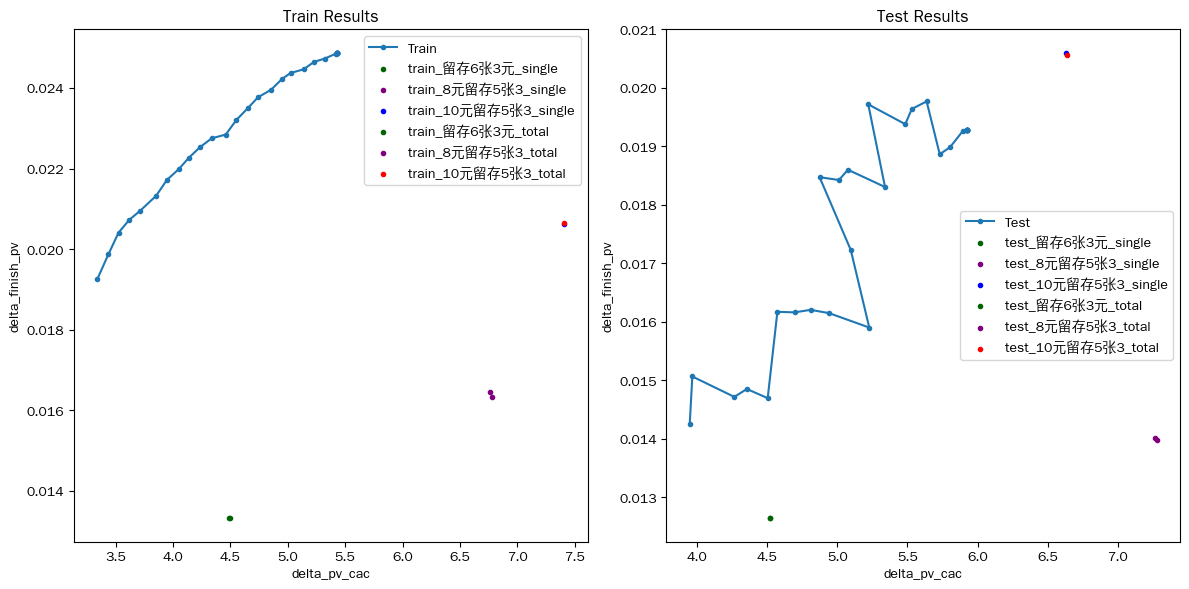


========== eeuen: running eeuen_v3 | s2 ==========
columns: ['exposure_prob', 'left1053_minus_left63', 'left853_minus_left63', 'left63', 'cost_1', 'left1053', 'left853']
all_columns: ['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per', 'cost_1_per', 'left1053_per', 'left853_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08

,exposure_prob_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
12,0.1,0.1,0.2,0.3,13326
7999,0.8,1.0,1.0,1.0,13930
8999,0.9,1.0,1.0,1.0,18773
9888,1.0,0.9,0.9,0.9,12240
9899,1.0,0.9,1.0,1.0,10230
9999,1.0,1.0,1.0,1.0,18491


['cost_1_per', 'left1053_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left1053_per,left63_per,counts
1,0.1,0.1,0.2,11440
11,0.1,0.2,0.2,11950
12,0.1,0.2,0.3,11687
23,0.1,0.3,0.4,10131
100,0.2,0.1,0.1,10519
111,0.2,0.2,0.2,11636
122,0.2,0.3,0.3,14845
123,0.2,0.3,0.4,12121
133,0.2,0.4,0.4,12096
200,0.3,0.1,0.1,10714


['cost_1_per', 'left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,50947
1,0.2,48148
2,0.3,43941
3,0.4,36360
4,0.5,43522
5,0.6,28112
6,0.7,30972
7,0.8,25533



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
8,0.9,17901
9,1.0,10674


[35 20 12 34 32  2  1 37  8  4 42  5 40 38 23 24 39 19 31 28 36 27 17 29
 26 10 33 41 25 15  3 14  7  0 18  9 13 22 21  6 16 11 30]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1851        4.0        9.0       3.581   
1              0   8元留存5张3   1876        5.0       15.0       2.280   
2              0      DS空白   6836        8.0       19.0       0.000   
3              0    留存6张3元   2763        6.0       41.0      28.238   
4              1  10元留存5张3   1862      156.0      409.0    1316.166   
..           ...       ...    ...        ...        ...         ...   
167           41    留存6张3元   4913       66.0      168.0     330.146   
168           42  10元留存5张3   3672      114.0      317.0    1221.260   
169           42   8元留存5张3   3731      117.0      387.0    1034.580   
170           42      DS空白  15540      237.0      556.0      25.281   
171           42    留存6张3元   5632      158.0      417.0     737.570   



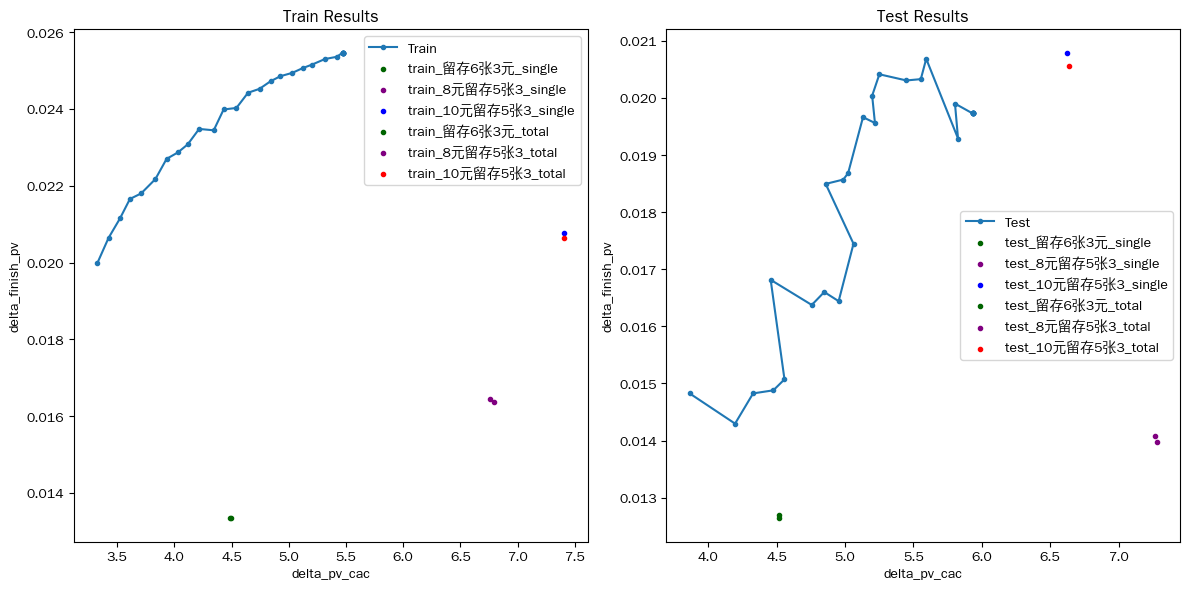


========== eeuen: running eeuen_v3 | s3 ==========
columns: ['exposure_prob', 'left1053_minus_left63', 'left853_minus_left63', 'left63', 'cost_1']
all_columns: ['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per', 'cost_1_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026

,exposure_prob_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
12,0.1,0.1,0.2,0.3,13326
7999,0.8,1.0,1.0,1.0,13930
8999,0.9,1.0,1.0,1.0,18773
9888,1.0,0.9,0.9,0.9,12240
9899,1.0,0.9,1.0,1.0,10230
9999,1.0,1.0,1.0,1.0,18491


['exposure_prob_per', 'left1053_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,exposure_prob_per,left1053_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,13198
1,0.1,0.1,0.2,16547
112,0.2,0.2,0.3,11336
434,0.5,0.4,0.5,10828
545,0.6,0.5,0.6,16482
645,0.7,0.5,0.6,11746
656,0.7,0.6,0.7,18691
756,0.8,0.6,0.7,10411
766,0.8,0.7,0.7,10378
767,0.8,0.7,0.8,17298


['cost_1_per', 'left853_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,70232
1,0.2,66627
2,0.3,59137
3,0.4,73599
4,0.5,73184
5,0.6,55671
6,0.7,44429
7,0.8,50027
9,1.0,22226



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
8,0.9,16631


[25 11 22 24 29 27  2  1 23  7  4 30  5 28 26  9 18 16 15 31 12 13 10 17
 21 20  3  6  0  8 19 14]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1851        4.0        9.0       3.581   
1              0   8元留存5张3   1876        5.0       15.0       2.280   
2              0      DS空白   6836        8.0       19.0       0.000   
3              0    留存6张3元   2763        6.0       41.0      28.238   
4              1  10元留存5张3   1862      156.0      409.0    1316.166   
..           ...       ...    ...        ...        ...         ...   
123           30    留存6张3元   4476      202.0      472.0     783.130   
124           31  10元留存5张3   2067       55.0      163.0     561.604   
125           31   8元留存5张3   2116       68.0      203.0     477.982   
126           31      DS空白   9084      175.0      464.0      30.000   
127           31    留存6张3元   3364      103.0      320.0     449.787   

     delta_cvr  delta_cac  
0    

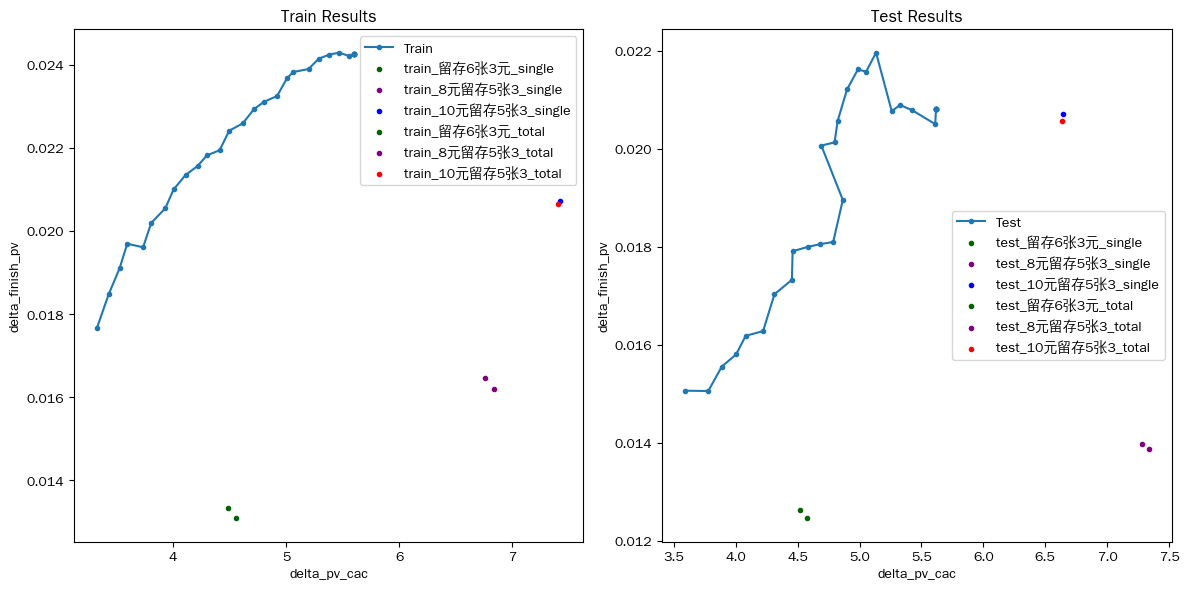


========== eeuen: running eeuen_v3 | s4 ==========
columns: ['exposure_prob', 'left1053_minus_left63', 'left853_minus_left63', 'left63', 'cost_1']
all_columns: ['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per', 'cost_1_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026

,exposure_prob_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
12,0.1,0.1,0.2,0.3,13326
7999,0.8,1.0,1.0,1.0,13930
8999,0.9,1.0,1.0,1.0,18773
9888,1.0,0.9,0.9,0.9,12240
9899,1.0,0.9,1.0,1.0,10230
9999,1.0,1.0,1.0,1.0,18491


['cost_1_per', 'left1053_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left1053_minus_left63_per,left63_per,counts
1,0.1,0.1,0.2,15854
12,0.1,0.2,0.3,10548
123,0.2,0.3,0.4,10403
334,0.4,0.4,0.5,10242
445,0.5,0.5,0.6,16503
556,0.6,0.6,0.7,17751
656,0.7,0.6,0.7,10874
666,0.7,0.7,0.7,16184
667,0.7,0.7,0.8,11955
767,0.8,0.7,0.8,15573


['cost_1_per', 'left853_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,83430
1,0.2,67320
2,0.3,59925
3,0.4,63196
4,0.5,73770
5,0.6,67396
6,0.7,39100
7,0.8,32944
9,1.0,22226



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
8,0.9,17210


[22 10 23 21 14 26  2  1 24  6  4 29  5 27 25  9 15 30 16 18 11 13 28 20
  7  8  3 12 17  0 19]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1851        4.0        9.0       3.581   
1              0   8元留存5张3   1876        5.0       15.0       2.280   
2              0      DS空白   6836        8.0       19.0       0.000   
3              0    留存6张3元   2763        6.0       41.0      28.238   
4              1  10元留存5张3   1862      156.0      409.0    1316.166   
..           ...       ...    ...        ...        ...         ...   
119           29    留存6张3元   4476      202.0      472.0     783.130   
120           30  10元留存5张3   2195       68.0      194.0     710.647   
121           30   8元留存5张3   2207       73.0      224.0     537.612   
122           30      DS空白   9347      187.0      482.0      30.000   
123           30    留存6张3元   3461       99.0      294.0     445.946   

     delta_cvr  delta_cac  
0     0.

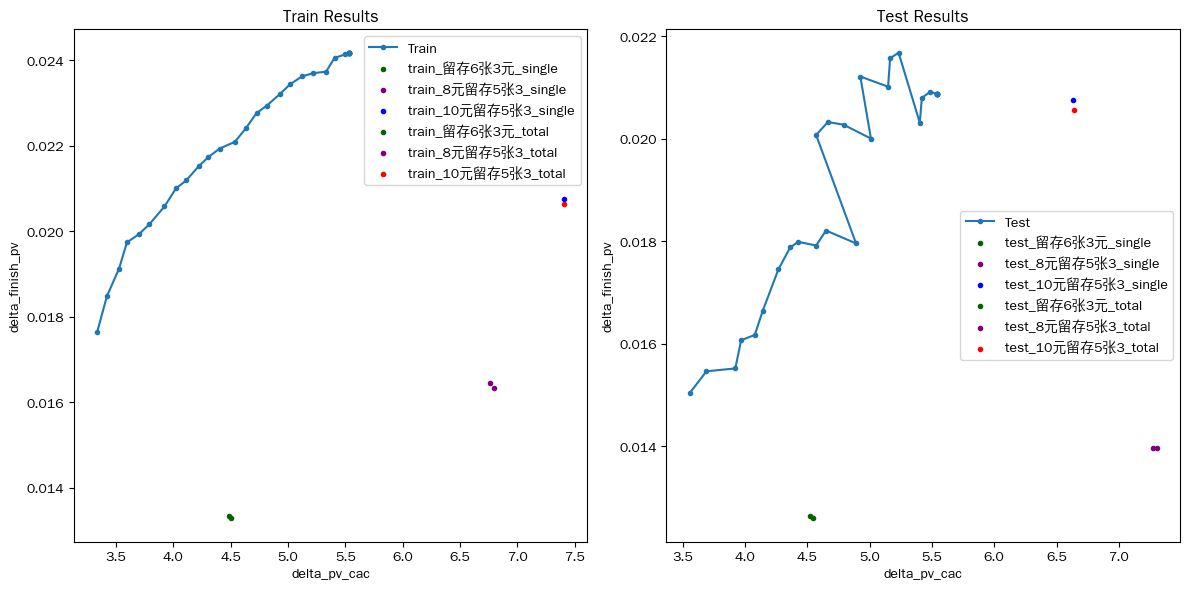


========== eeuen: running eeuen_v3 | s5 ==========
columns: ['exposure_prob', 'left1053_minus_left63', 'left853_minus_left63', 'left63', 'cost_1', 'left853']
all_columns: ['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per', 'cost_1_per', 'left853_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-0

,exposure_prob_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
12,0.1,0.1,0.2,0.3,13326
7999,0.8,1.0,1.0,1.0,13930
8999,0.9,1.0,1.0,1.0,18773
9888,1.0,0.9,0.9,0.9,12240
9899,1.0,0.9,1.0,1.0,10230
9999,1.0,1.0,1.0,1.0,18491


['exposure_prob_per', 'left853_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,exposure_prob_per,left853_minus_left63_per,left63_per,counts
21,0.1,0.3,0.2,10138
505,0.6,0.1,0.6,10058
777,0.8,0.8,0.8,12632
788,0.8,0.9,0.9,12232
888,0.9,0.9,0.9,14925


['cost_1_per', 'left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,49667
1,0.2,45849
2,0.3,41170
3,0.4,39633
4,0.5,48741
5,0.6,29710
6,0.7,36890
7,0.8,27331
8,0.9,20549



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
9,1.0,6924


[31 25 17 30 29 15  2  1 33 14  4 39  5 36 34 23 26 35 22 24  8 32 38 37
 21 10 27  7 16 19  3 12  9  0 18 28 11  6 20 13]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1851        4.0        9.0       3.581   
1              0   8元留存5张3   1876        5.0       15.0       2.280   
2              0      DS空白   6836        8.0       19.0       0.000   
3              0    留存6张3元   2763        6.0       41.0      28.238   
4              1  10元留存5张3   1862      156.0      409.0    1316.166   
..           ...       ...    ...        ...        ...         ...   
155           38    留存6张3元   4104      104.0      279.0     458.436   
156           39  10元留存5张3    894       33.0      100.0     376.165   
157           39   8元留存5张3    913       27.0      104.0     275.108   
158           39      DS空白   3765       63.0      133.0       0.000   
159           39    留存6张3元   1352       41.0       88.0     186.730   

     delt

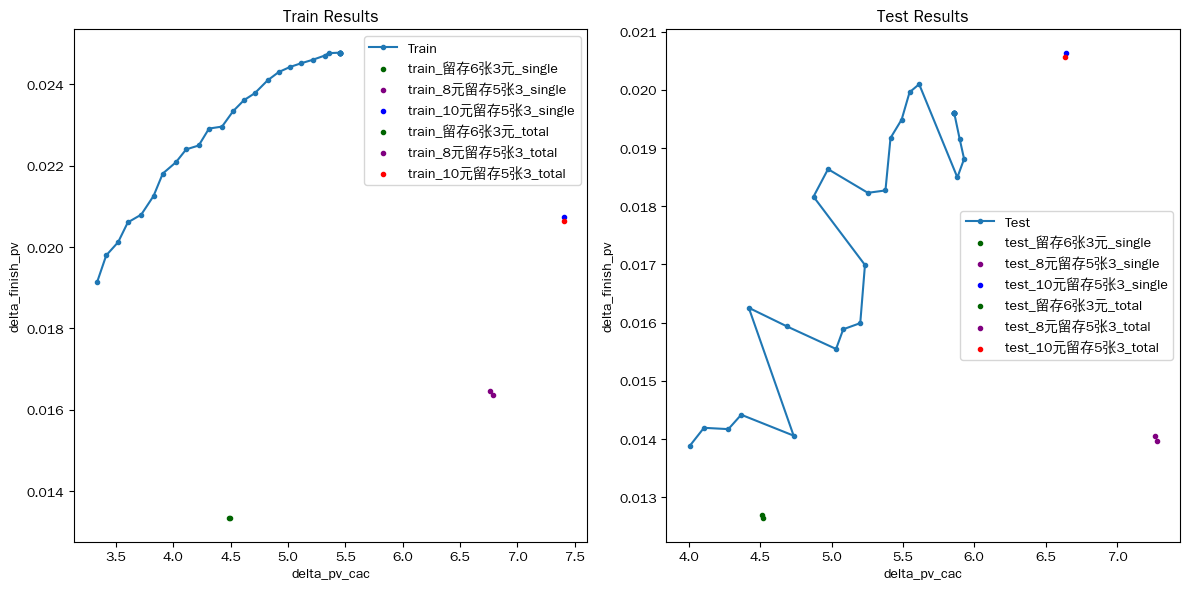

In [48]:
# 搜索 EEUEN 的最佳 stage
eeuen_stage_results = run_stage_search(
    eeuen_scheme_dfs,
    eeuen_stage_configs,
    search_name='eeuen'
)

In [49]:
# 合并 EUEN / EEUEN 搜索结果
stage_results = {}

if 'euen_stage_results' in globals():
    stage_results.update(euen_stage_results)

if 'eeuen_stage_results' in globals():
    stage_results.update(eeuen_stage_results)

stage_results.keys()

dict_keys([('euen_v2', 's1'), ('euen_v2', 's2'), ('euen_v2', 's3'), ('euen_v2', 's4'), ('euen_v2', 's5'), ('euen_v3', 's1'), ('euen_v3', 's2'), ('euen_v3', 's3'), ('euen_v3', 's4'), ('euen_v3', 's5'), ('eeuen_v2', 's1'), ('eeuen_v2', 's2'), ('eeuen_v2', 's3'), ('eeuen_v2', 's4'), ('eeuen_v2', 's5'), ('eeuen_v3', 's1'), ('eeuen_v3', 's2'), ('eeuen_v3', 's3'), ('eeuen_v3', 's4'), ('eeuen_v3', 's5')])

In [50]:

# 7. 汇总 train/test 仿真结果

def build_stage_result_df(result_list, scheme_name, stage_name, data_type, search_name):
    df = pd.DataFrame(
        result_list,
        columns=[
            '约束cac',
            '实际增量cac',
            '实际增量cvr',
            '实际增量首单cvr',
            '留存频次',
        ]
    )
    df['search_name'] = search_name
    df['scheme'] = scheme_name
    df['stage_name'] = stage_name
    df['data_type'] = data_type
    return df


summary_list = []

for (scheme_name, stage_name), res in stage_results.items():
    summary_list.append(build_stage_result_df(res['train_list'], scheme_name, stage_name, 'train', res['search_name']))
    summary_list.append(build_stage_result_df(res['test_list'], scheme_name, stage_name, 'test', res['search_name']))

stage_summary_df = pd.concat(summary_list, ignore_index=True)

stage_summary_df[
    ['search_name', 'scheme', 'stage_name', 'data_type', '约束cac', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']
].head(10)

,search_name,scheme,stage_name,data_type,约束cac,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
0,euen,euen_v2,s1,train,3.5,3.296566,0.016622,0.005885,2.824695
1,euen,euen_v2,s1,train,3.6,3.390304,0.017142,0.005945,2.883638
2,euen,euen_v2,s1,train,3.7,3.491802,0.017847,0.006138,2.907647
3,euen,euen_v2,s1,train,3.8,3.579752,0.018362,0.006325,2.903278
4,euen,euen_v2,s1,train,3.9,3.686996,0.018627,0.006489,2.870554
5,euen,euen_v2,s1,train,4.0,3.787625,0.018874,0.006749,2.796709
6,euen,euen_v2,s1,train,4.1,3.879575,0.019529,0.006596,2.960801
7,euen,euen_v2,s1,train,4.2,3.982961,0.020048,0.006792,2.951578
8,euen,euen_v2,s1,train,4.3,4.093110,0.020295,0.007060,2.874648
9,euen,euen_v2,s1,train,4.4,4.206901,0.020475,0.006861,2.984204


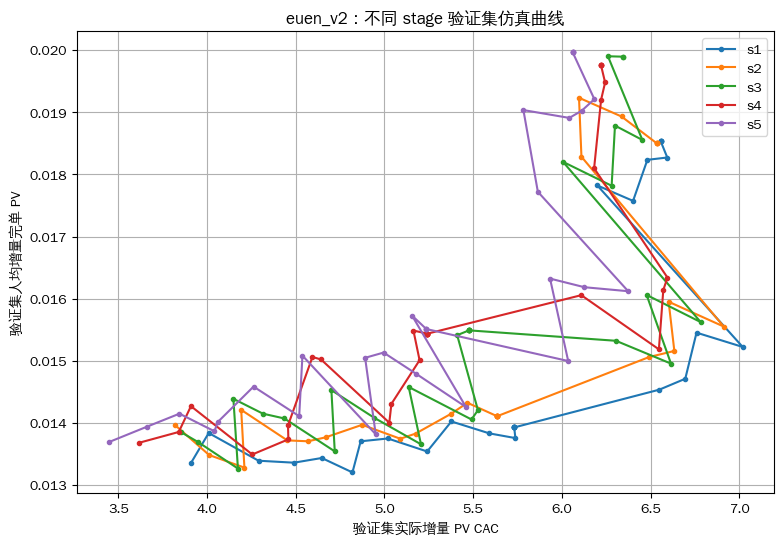

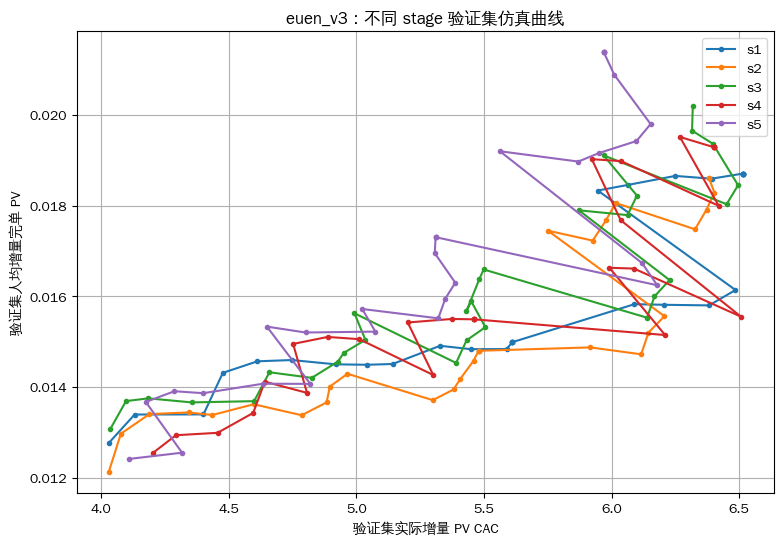

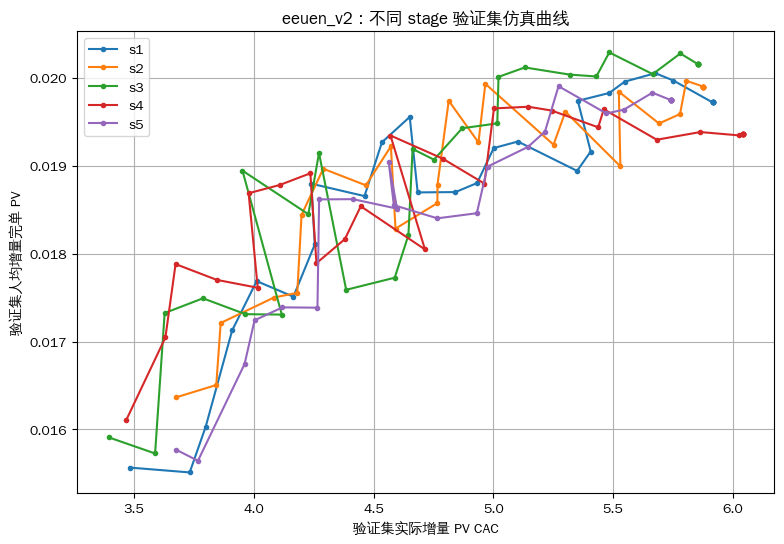

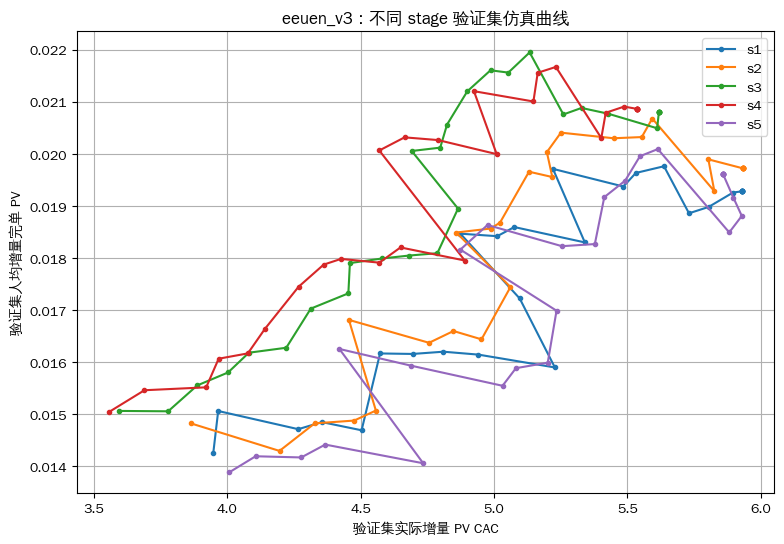

In [51]:

# 8. 一个模型一个图：不同 stage 下验证集仿真曲线

for scheme_name in ['euen_v2', 'euen_v3', 'eeuen_v2', 'eeuen_v3']:
    plt.figure(figsize=(9, 6))

    stage_names = (
        stage_summary_df[
            (stage_summary_df['scheme'] == scheme_name) &
            (stage_summary_df['data_type'] == 'test')
        ]['stage_name']
        .drop_duplicates()
        .tolist()
    )

    for stage_name in stage_names:
        plot_df = stage_summary_df[
            (stage_summary_df['scheme'] == scheme_name) &
            (stage_summary_df['stage_name'] == stage_name) &
            (stage_summary_df['data_type'] == 'test')
        ].replace([np.inf, -np.inf], np.nan).dropna(
            subset=['实际增量cac', '实际增量cvr']
        ).sort_values('约束cac')

        # ).sort_values('实际增量cac')

        plt.plot(
            plot_df['实际增量cac'],
            plot_df['实际增量cvr'],
            marker='.',
            label=stage_name
        )

    plt.xlabel('验证集实际增量 PV CAC')
    plt.ylabel('验证集人均增量完单 PV')
    plt.title(f'{scheme_name}：不同 stage 验证集仿真曲线')
    plt.legend()
    plt.grid(True)
    plt.show()

In [52]:
# 最佳参数

best_stage_map = {
    'euen_v2': 's5',
    'euen_v3': 's5',
    'eeuen_v2': 's3',
    'eeuen_v3': 's3',
}

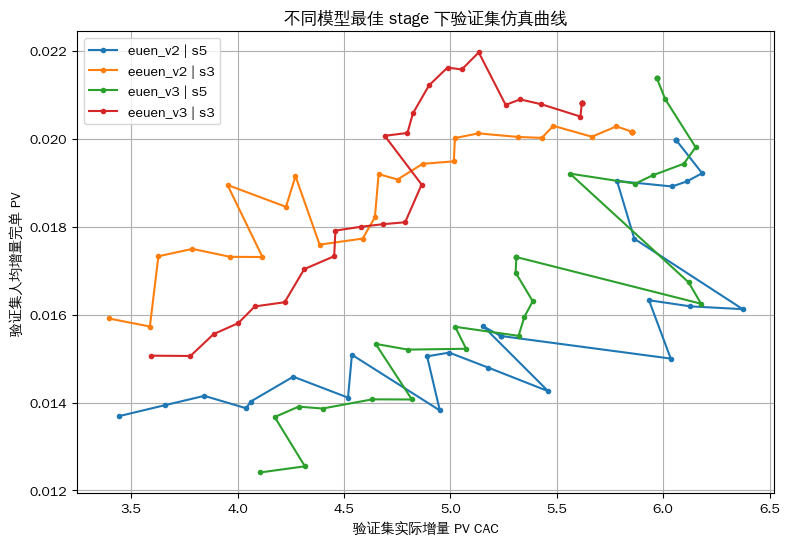

In [53]:
best_stage_summary_df = pd.concat([
    stage_summary_df[
        (stage_summary_df['scheme'] == scheme) &
        (stage_summary_df['stage_name'] == stage_name) &
        (stage_summary_df['data_type'] == 'test')
    ]
    for scheme, stage_name in best_stage_map.items()
], ignore_index=True)

plt.figure(figsize=(9, 6))

for scheme_name in ['euen_v2', 'eeuen_v2', 'euen_v3', 'eeuen_v3']:
    plot_df = best_stage_summary_df[
        best_stage_summary_df['scheme'] == scheme_name
    ].replace([np.inf, -np.inf], np.nan).dropna(
        subset=['实际增量cac', '实际增量cvr']
   # ).sort_values('实际增量cac')
    ).sort_values('约束cac')

    plt.plot(
        plot_df['实际增量cac'],
        plot_df['实际增量cvr'],
        marker='.',
        label=f"{scheme_name} | {best_stage_map[scheme_name]}"
    )

plt.xlabel('验证集实际增量 PV CAC')
plt.ylabel('验证集人均增量完单 PV')
plt.title('不同模型最佳 stage 下验证集仿真曲线')
plt.legend()
plt.grid(True)
plt.show()

In [40]:
# euen搜索参数

euen_stage_configs = {
    's1': [
        (['cost_1_per', 'left853_minus_left63_per', 'left63_per'], 10000),
        (['left853_per', 'left63_per'], 10000),
        (['left63_per'], 20000),
    ],
    
    's2': [
        (['cost_1_per', 'left1053_minus_left63_per', 'left63_per'], 10000),
        (['left1053_per', 'left853_per'], 15000),
        (['left63_per'], 15000),
    ],
    
    's3': [
        (['cost_1_per', 'left1053_per', 'left63_per'], 10000),
        (['left1053_per', 'left63_per'], 10000),
        (['left63_per'], 20000),
    ],
    
    's4': [
        (['cost_1_per', 'left853_per', 'left63_per'], 10000),
        (['left853_per', 'left63_per'], 10000),
        (['left63_per'], 20000),
    ],
  
    's5': [
        (['cost_1_per', 'left1053_minus_left63_per', 'left63_per'], 10000),
        (['left853_per', 'left63_per'], 10000),
        (['left63_per'], 20000),
    ],

}

In [41]:
# eeuen搜索参数

eeuen_stage_configs = {
     's1': [
        (['exposure_prob_per', 'left1053_minus_left63_per', 'left63_per'], 10000),
        (['exposure_prob_per','left853_minus_left63_per', 'left63_per'], 10000),
        (['cost_1_per','left853_per', 'left63_per'], 10000),
        (['left63_per'], 20000),
    ],
    
     's2': [
        (['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 10000),
        (['cost_1_per','left1053_per', 'left63_per'], 10000),
        (['cost_1_per','left853_per', 'left63_per'], 10000),
        (['left63_per'], 20000),
    ],
    

    's3': [
        (['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 10000),
        (['cost_1_per','left1053_minus_left63_per', 'left63_per'], 10000),
        (['cost_1_per','left853_minus_left63_per', 'left63_per'], 10000),
        (['left63_per'], 20000),
    ],
    
    
    's4': [
        (['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 10000),
        (['cost_1_per','left1053_minus_left63_per', 'left853_per'], 10000),
        (['left853_per', 'left63_per'], 10000),
        (['left63_per'], 20000),
    ],
    
    
    
     's5': [
        (['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 10000),
        (['cost_1_per','left1053_minus_left63_per', 'left63_per'], 10000),
        (['cost_1_per','left853_minus_left63_per', 'left63_per'], 10000),
        (['left63_per'], 20000),
    ],

    
}


========== euen: running euen_v2 | s1 ==========
columns: ['cost_1', 'left853_minus_left63', 'left63', 'left853']
all_columns: ['cost_1_per', 'left853_minus_left63_per', 'left63_per', 'left853_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']
(8

,cost_1_per,left853_minus_left63_per,left63_per,counts
111,0.2,0.2,0.2,10854
555,0.6,0.6,0.6,10583
565,0.6,0.7,0.6,12377
666,0.7,0.7,0.7,17915
676,0.7,0.8,0.7,10925
777,0.8,0.8,0.8,38347
888,0.9,0.9,0.9,62296
999,1.0,1.0,1.0,76218


['left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left853_per,left63_per,counts
0,0.1,0.1,74052
11,0.2,0.2,51213
12,0.2,0.3,10618
21,0.3,0.2,13050
22,0.3,0.3,58334
23,0.3,0.4,10295
32,0.4,0.3,14398
33,0.4,0.4,57519
34,0.4,0.5,10318
43,0.5,0.4,14379


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage

============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,9342
1,0.2,8292
2,0.3,660
3,0.4,1687
4,0.5,2179
5,0.6,5225
6,0.7,7218
7,0.8,4968
8,0.9,2880
9,1.0,7332


[25 18  4 15  8  6 22  9 14  7 23 21  3 12 24 20  5 11  1 10  2  0 17 19
 16 13]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1358        3.0        7.0      28.167   
1              0   8元留存5张3   1390        3.0       11.0       5.987   
2              0      DS空白   5907        8.0       27.0       0.021   
3              0    留存6张3元   2199        5.0       11.0      15.056   
4              1  10元留存5张3   1355        9.0       26.0      80.161   
..           ...       ...    ...        ...        ...         ...   
99            24    留存6张3元   3635       74.0      196.0     305.906   
100           25  10元留存5张3   6483      122.0      311.0     946.581   
101           25   8元留存5张3   6527      113.0      369.0     700.402   
102           25      DS空白  26774      380.0     1159.0      35.000   
103           25    留存6张3元   9999      157.0      439.0     524.000   

     delta_cvr  delta_cac  
0     0.000584  35.5290

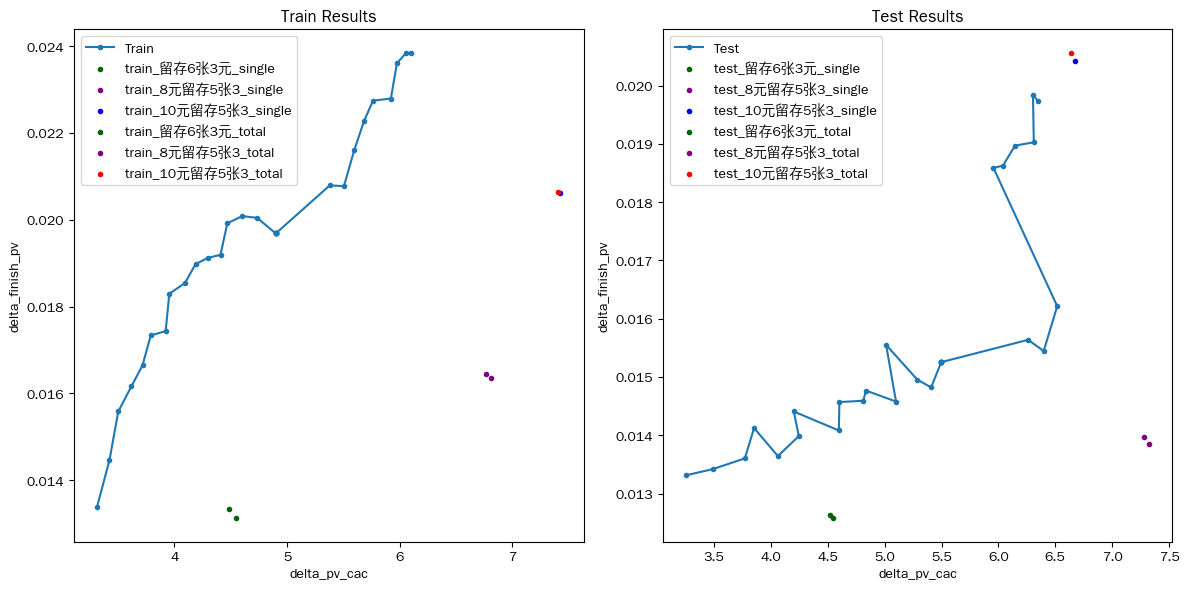


========== euen: running euen_v2 | s2 ==========
columns: ['cost_1', 'left1053_minus_left63', 'left63', 'left1053', 'left853']
all_columns: ['cost_1_per', 'left1053_minus_left63_per', 'left63_per', 'left1053_per', 'left853_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '

,cost_1_per,left1053_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,15822
10,0.1,0.2,0.1,13513
11,0.1,0.2,0.2,10134
505,0.6,0.1,0.6,10510
666,0.7,0.7,0.7,21347
767,0.8,0.7,0.8,16384
777,0.8,0.8,0.8,39487
878,0.9,0.8,0.9,14767
888,0.9,0.9,0.9,50635
989,1.0,0.9,1.0,10240


['left1053_per', 'left853_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_per,left853_per,counts
0,0.1,0.1,43576
11,0.2,0.2,47426
12,0.2,0.3,19461
22,0.3,0.3,46353
23,0.3,0.4,22977
33,0.4,0.4,42415
34,0.4,0.5,23616
44,0.5,0.5,41589
45,0.5,0.6,16779
55,0.6,0.6,47095


['left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
1,0.2,16157
2,0.3,16023
3,0.4,19280
4,0.5,20474
5,0.6,18892
6,0.7,20365
7,0.8,27524
8,0.9,18542



============================== Final Small Combinations ==============================
Small Combinations (<15000 samples):


,left63_per,counts
0,0.1,10854
9,1.0,4675


[24 18  4 16 11 29 27  2  8 30  9  6  7 10 20 21 13 17 23 12 26 14 28 15
  3  5 25 22  0  1 19]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   2181        2.0       13.0       7.163   
1              0   8元留存5张3   2130        5.0       23.0       4.546   
2              0      DS空白   8365        9.0       43.0       0.000   
3              0    留存6张3元   3146        6.0       41.0      34.503   
4              1  10元留存5张3   1796        0.0        0.0       6.168   
..           ...       ...    ...        ...        ...         ...   
119           29    留存6张3元   3670      106.0      271.0     355.201   
120           30  10元留存5张3   1978       57.0      161.0     478.507   
121           30   8元留存5张3   1958       54.0      162.0     234.554   
122           30      DS空白   8557      198.0      659.0       5.000   
123           30    留存6张3元   3036       65.0      207.0     232.442   

     delta_cvr  delta_cac  
0     0.

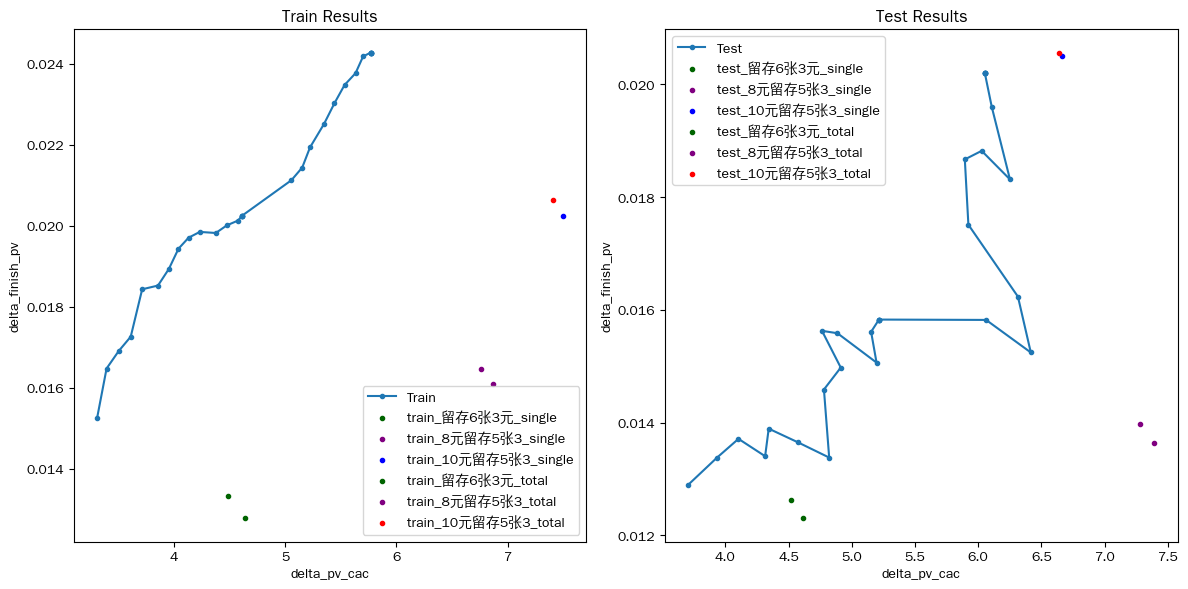


========== euen: running euen_v2 | s3 ==========
columns: ['cost_1', 'left1053', 'left63']
all_columns: ['cost_1_per', 'left1053_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']
(837501, 40) (843787, 40)
['cost_1_per', 'left1053_p

,cost_1_per,left1053_per,left63_per,counts
0,0.1,0.1,0.1,48312
11,0.1,0.2,0.2,26254
111,0.2,0.2,0.2,30812
122,0.2,0.3,0.3,27001
222,0.3,0.3,0.3,25005
233,0.3,0.4,0.4,23765
333,0.4,0.4,0.4,22757
344,0.4,0.5,0.5,21044
444,0.5,0.5,0.5,24318
455,0.5,0.6,0.6,20090


['left1053_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_per,left63_per,counts
0,0.1,0.1,27297
12,0.2,0.3,13288
23,0.3,0.4,16673
32,0.4,0.3,11215
34,0.4,0.5,18714
43,0.5,0.4,13167
54,0.6,0.5,12468
56,0.6,0.7,10803


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
1,0.2,26343
8,0.9,22216



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,7785
2,0.3,7501
3,0.4,7518
4,0.5,7197
5,0.6,18780
6,0.7,10370
7,0.8,18484
9,1.0,8828


[28  7 13 20 16 25  1 22  5 17 15 11  2 23  9 26 27  8  3 12 14 21  4 10
  0 24 19 18  6]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   6427        7.0       32.0      62.595   
1              0   8元留存5张3   6419       16.0       95.0      26.098   
2              0      DS空白  26118       37.0      115.0       0.000   
3              0    留存6张3元   9348       22.0      121.0      54.501   
4              1  10元留存5张3   3412        6.0       21.0      50.288   
..           ...       ...    ...        ...        ...         ...   
111           27    留存6张3元   4395       90.0      249.0     407.190   
112           28  10元留存5张3  11058      217.0      609.0    1816.258   
113           28   8元留存5张3  11031      186.0      566.0    1155.250   
114           28      DS空白  47385      611.0     1937.0     110.637   
115           28    留存6张3元  16989      241.0      657.0     919.323   

     delta_cvr  delta_cac  
0     0.000576

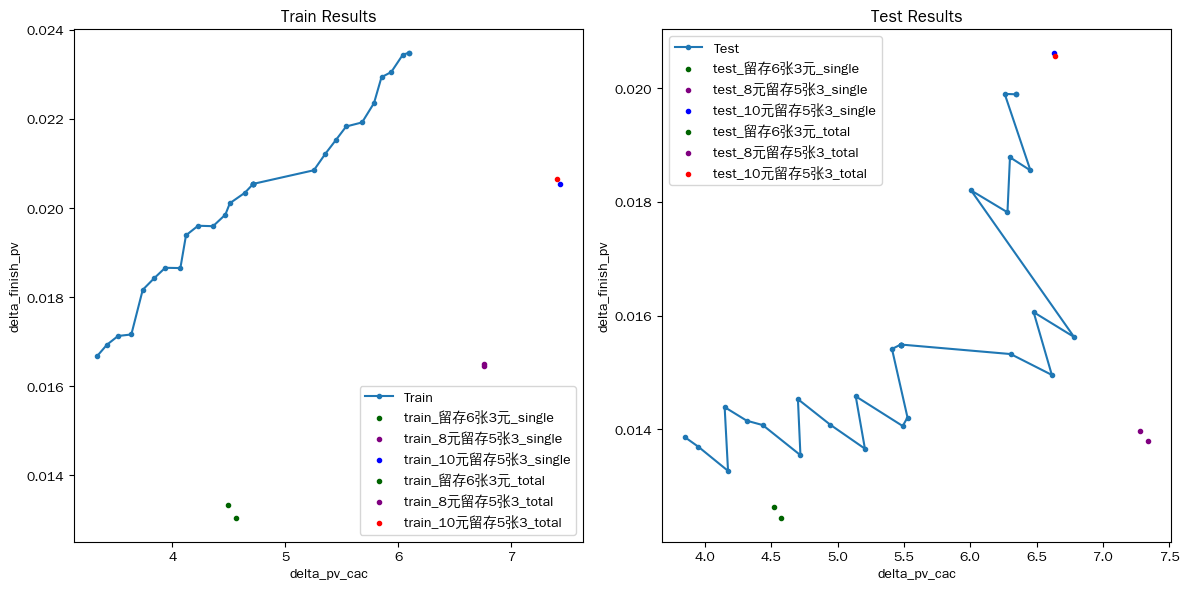


========== euen: running euen_v2 | s4 ==========
columns: ['cost_1', 'left853', 'left63']
all_columns: ['cost_1_per', 'left853_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']
(837501, 40) (843787, 40)
['cost_1_per', 'left853_per'

,cost_1_per,left853_per,left63_per,counts
0,0.1,0.1,0.1,40626
11,0.1,0.2,0.2,26651
111,0.2,0.2,0.2,26387
122,0.2,0.3,0.3,27934
222,0.3,0.3,0.3,24989
233,0.3,0.4,0.4,26085
333,0.4,0.4,0.4,25673
344,0.4,0.5,0.5,23968
444,0.5,0.5,0.5,29033
455,0.5,0.6,0.6,20003


['left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left853_per,left63_per,counts
0,0.1,0.1,33426
12,0.2,0.3,10618
21,0.3,0.2,13050
23,0.3,0.4,10295
32,0.4,0.3,14398
34,0.4,0.5,10318
43,0.5,0.4,14379
45,0.5,0.6,10562
54,0.6,0.5,12763
88,0.9,0.9,10702


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage

============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,9342
1,0.2,17321
2,0.3,6071
3,0.4,7448
4,0.5,7659
5,0.6,12770
6,0.7,14197
7,0.8,9325
8,0.9,2880
9,1.0,5124


[27  7 12 20 15  1 21  5 16 14 10 18  8  9 26 25  3 13  6  4 11 17  0  2
 23 24 22 19]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   5416        6.0       25.0      59.410   
1              0   8元留存5张3   5412       13.0       71.0      24.514   
2              0      DS空白  21915       36.0      107.0       0.000   
3              0    留存6张3元   7883       19.0      105.0      52.345   
4              1  10元留存5张3   3506        3.0        4.0      25.266   
..           ...       ...    ...        ...        ...         ...   
107           26    留存6张3元   2080       40.0      106.0     137.810   
108           27  10元留存5张3  12010      187.0      521.0    1494.116   
109           27   8元留存5张3  12035      167.0      560.0    1011.957   
110           27      DS空白  49994      526.0     1675.0      80.324   
111           27    留存6张3元  18098      214.0      621.0     732.862   

     delta_cvr  delta_cac  
0    -0.000267 -4

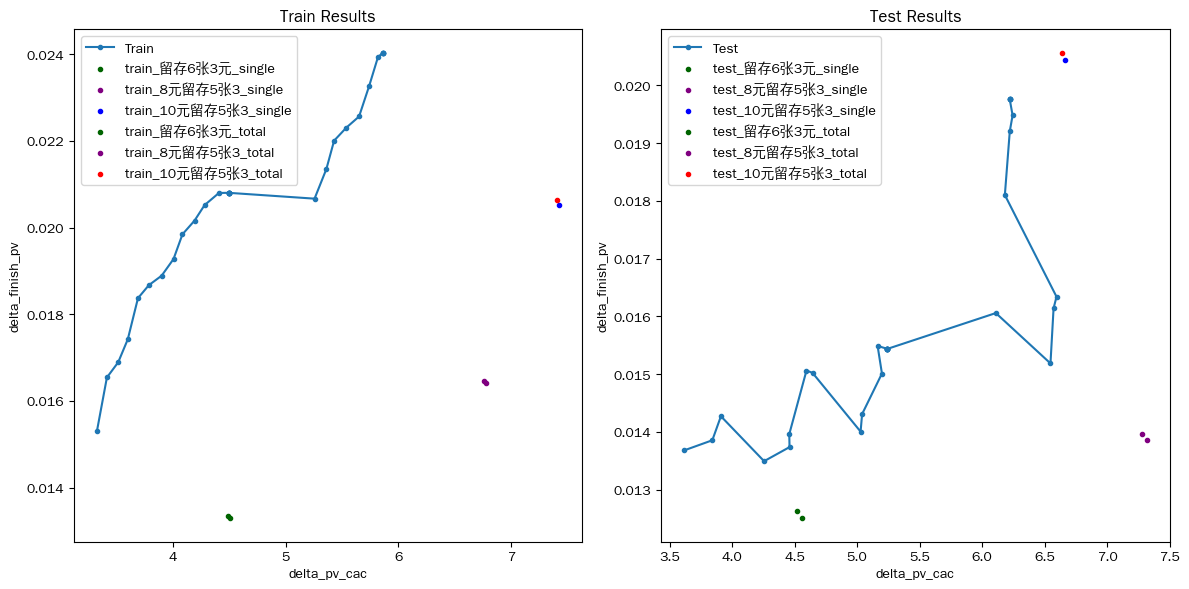


========== euen: running euen_v2 | s5 ==========
columns: ['cost_1', 'left1053_minus_left63', 'left63', 'left853']
all_columns: ['cost_1_per', 'left1053_minus_left63_per', 'left63_per', 'left853_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']


,cost_1_per,left1053_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,15822
10,0.1,0.2,0.1,13513
11,0.1,0.2,0.2,10134
505,0.6,0.1,0.6,10510
666,0.7,0.7,0.7,21347
767,0.8,0.7,0.8,16384
777,0.8,0.8,0.8,39487
878,0.9,0.8,0.9,14767
888,0.9,0.9,0.9,50635
989,1.0,0.9,1.0,10240


['left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left853_per,left63_per,counts
0,0.1,0.1,49067
11,0.2,0.2,53313
12,0.2,0.3,10618
21,0.3,0.2,11827
22,0.3,0.3,58334
23,0.3,0.4,10295
32,0.4,0.3,14398
33,0.4,0.4,57519
34,0.4,0.5,10318
43,0.5,0.4,14379


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage

============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,4992
1,0.2,8135
2,0.3,660
3,0.4,1687
4,0.5,2179
5,0.6,7396
6,0.7,7528
7,0.8,3358
8,0.9,1635
9,1.0,4675


[28 21  4 18 16 27 25  2 17  8  9  6  7 10 24 12 11 23 14 26 13  3  5 20
 22  0 19  1 15]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   2181        2.0       13.0       7.163   
1              0   8元留存5张3   2130        5.0       23.0       4.546   
2              0      DS空白   8365        9.0       43.0       0.000   
3              0    留存6张3元   3146        6.0       41.0      34.503   
4              1  10元留存5张3   1796        0.0        0.0       6.168   
..           ...       ...    ...        ...        ...         ...   
111           27    留存6张3元   3354       95.0      240.0     301.272   
112           28  10元留存5张3   5481      101.0      268.0     775.675   
113           28   8元留存5张3   5468       87.0      282.0     498.842   
114           28      DS空白  22731      310.0      970.0      35.000   
115           28    留存6张3元   8565      124.0      356.0     381.782   

     delta_cvr  delta_cac  
0     0.000820

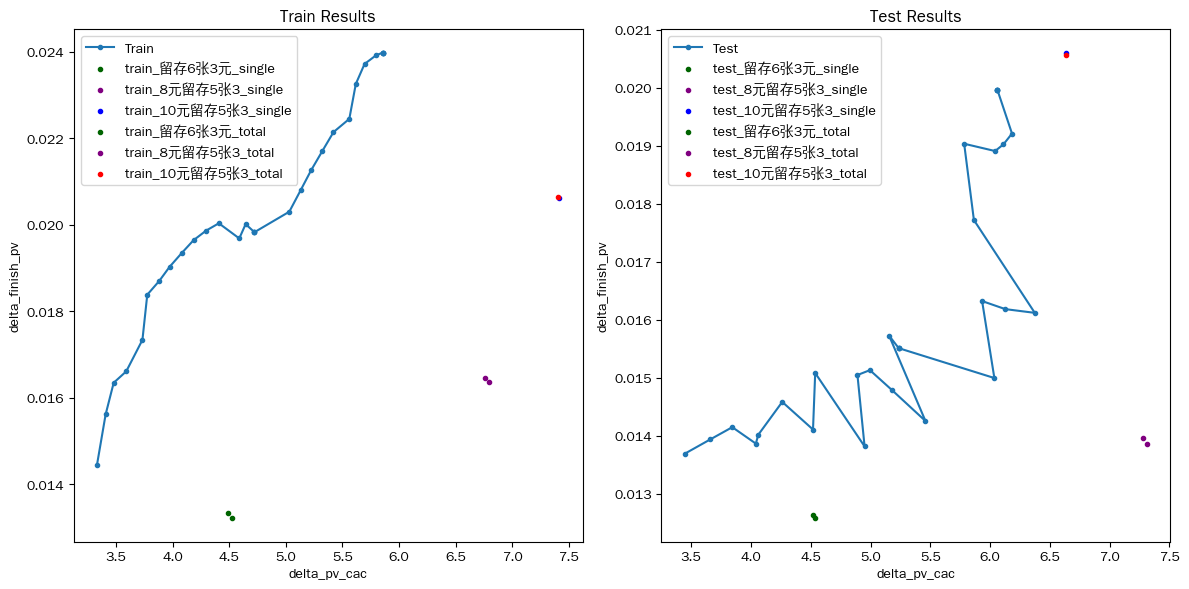


========== euen: running euen_v3 | s1 ==========
columns: ['cost_1', 'left853_minus_left63', 'left63', 'left853']
all_columns: ['cost_1_per', 'left853_minus_left63_per', 'left63_per', 'left853_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']
(8

,cost_1_per,left853_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,39676
10,0.1,0.2,0.1,13859
121,0.2,0.3,0.2,11258
788,0.8,0.9,0.9,11229
878,0.9,0.8,0.9,14415
888,0.9,0.9,0.9,26018
989,1.0,0.9,1.0,12172
999,1.0,1.0,1.0,59822


['left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left853_per,left63_per,counts
0,0.1,0.1,23798
11,0.2,0.2,56235
12,0.2,0.3,10359
22,0.3,0.3,59540
23,0.3,0.4,13359
32,0.4,0.3,13341
33,0.4,0.4,53677
34,0.4,0.5,15371
43,0.5,0.4,15989
44,0.5,0.5,51321


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage

============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,5948
1,0.2,16158
2,0.3,551
3,0.4,896
4,0.5,1400
5,0.6,1570
6,0.7,10063
7,0.8,4928
8,0.9,7226
9,1.0,11708


[21 13 25  8  3 16  5 12  2  7  4 26  6 14 19 10  9 24 27 23 17 18  0 15
 22  1 20 11]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   5225        5.0       11.0      26.922   
1              0   8元留存5张3   5467       10.0       75.0      29.766   
2              0      DS空白  21383       17.0       53.0       0.000   
3              0    留存6张3元   7601        7.0       56.0      22.810   
4              1  10元留存5张3   1924        2.0        9.0      21.069   
..           ...       ...    ...        ...        ...         ...   
107           26    留存6张3元   4938      131.0      363.0     597.424   
108           27  10元留存5张3   7776      179.0      520.0    1346.028   
109           27   8元留存5张3   7975      155.0      473.0     996.381   
110           27      DS空白  32940      448.0     1325.0      45.000   
111           27    留存6张3元  11757      200.0      550.0     718.364   

     delta_cvr  delta_cac  
0    -0.000373 -1

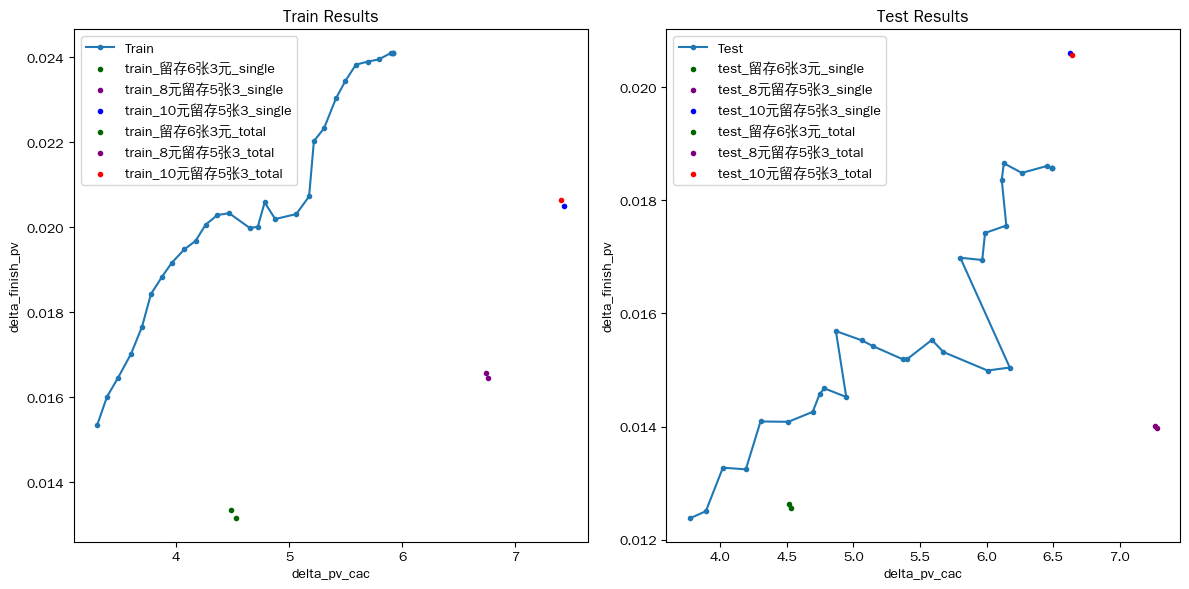


========== euen: running euen_v3 | s2 ==========
columns: ['cost_1', 'left1053_minus_left63', 'left63', 'left1053', 'left853']
all_columns: ['cost_1_per', 'left1053_minus_left63_per', 'left63_per', 'left1053_per', 'left853_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '

,cost_1_per,left1053_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,54508
11,0.1,0.2,0.2,15720
100,0.2,0.1,0.1,10539
111,0.2,0.2,0.2,26097
122,0.2,0.3,0.3,16807
211,0.3,0.2,0.2,11889
222,0.3,0.3,0.3,18480
223,0.3,0.3,0.4,10402
233,0.3,0.4,0.4,14777
322,0.4,0.3,0.3,11316


['left1053_per', 'left853_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_per,left853_per,counts
11,0.2,0.2,18708
22,0.3,0.3,19588
77,0.8,0.8,28497
88,0.9,0.9,18570


['left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
0,0.1,17086
2,0.3,18414
3,0.4,28275
4,0.5,30062
5,0.6,38396
6,0.7,35520
7,0.8,16802



============================== Final Small Combinations ==============================
Small Combinations (<15000 samples):


,left63_per,counts
1,0.2,12755
8,0.9,14617
9,1.0,8980


[20 10 30  1 37 31 21  3 35 25 39 32 27 19 14 26  4 36 33 29 18 38 13  9
 24 17 16 23  7  0 28 12  5  8 22 34  6 15  2 11]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   7339        7.0       20.0      48.618   
1              0   8元留存5张3   7415       15.0      105.0      34.655   
2              0      DS空白  29290       25.0       93.0       0.000   
3              0    留存6张3元  10464        8.0       63.0      30.521   
4              1  10元留存5张3   2055        4.0       18.0      42.322   
..           ...       ...    ...        ...        ...         ...   
155           38    留存6张3元   3318       51.0      120.0     178.073   
156           39  10元留存5张3   4664      127.0      348.0     960.446   
157           39   8元留存5张3   4701      119.0      290.0     642.669   
158           39      DS空白  19637      348.0      927.0       0.000   
159           39    留存6张3元   7350      166.0      436.0     545.333   

     delt

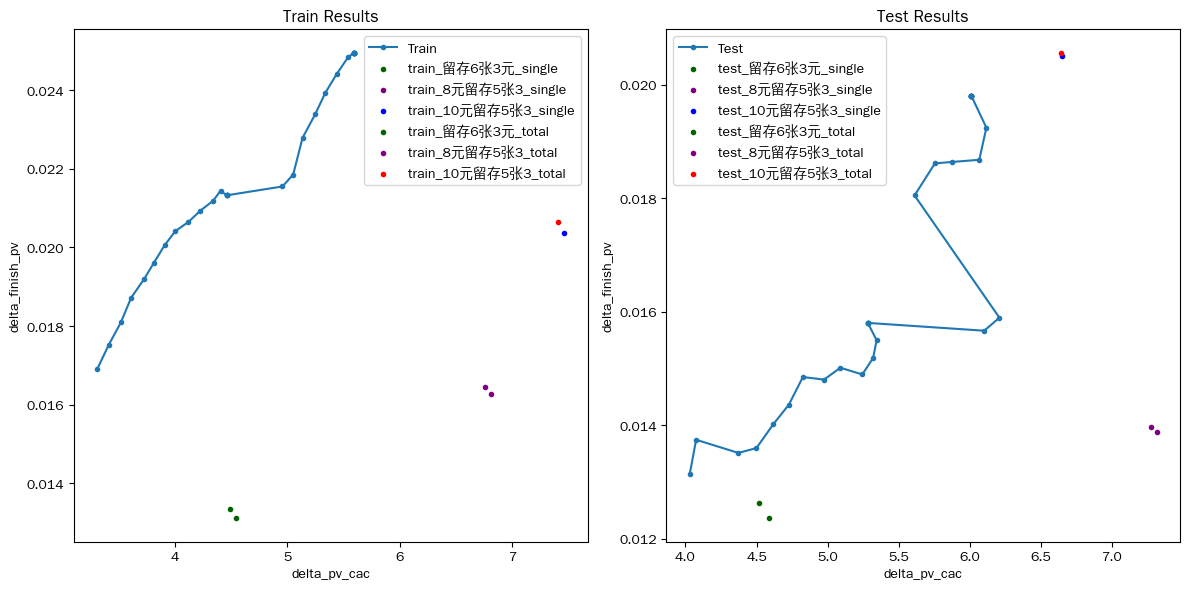


========== euen: running euen_v3 | s3 ==========
columns: ['cost_1', 'left1053', 'left63']
all_columns: ['cost_1_per', 'left1053_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']
(837501, 40) (843787, 40)
['cost_1_per', 'left1053_p

,cost_1_per,left1053_per,left63_per,counts
0,0.1,0.1,0.1,56104
11,0.1,0.2,0.2,19770
100,0.2,0.1,0.1,10793
111,0.2,0.2,0.2,32008
122,0.2,0.3,0.3,22745
211,0.3,0.2,0.2,13781
222,0.3,0.3,0.3,23640
233,0.3,0.4,0.4,20852
322,0.4,0.3,0.3,13158
333,0.4,0.4,0.4,21651


['left1053_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_per,left63_per,counts
0,0.1,0.1,10447
33,0.4,0.4,10800
34,0.4,0.5,10566
45,0.5,0.6,11794
56,0.6,0.7,11423
67,0.7,0.8,10463
77,0.8,0.8,10984


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
2,0.3,24248
8,0.9,20483



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,5937
1,0.2,18092
3,0.4,17254
4,0.5,19036
5,0.6,16672
6,0.7,13683
7,0.8,6387
9,1.0,14359


[16  9 19  1 29 22 18  3 34 23 33 24 12  4 27 32  6 15 20 11  8 14 13 21
  0 10  5  7 31 17 25 26  2 28 30]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   7533        7.0       20.0      49.286   
1              0   8元留存5张3   7644       15.0      105.0      34.928   
2              0      DS空白  30167       27.0       97.0       0.000   
3              0    留存6张3元  10760        8.0       63.0      31.076   
4              1  10元留存5张3   2571        4.0       18.0      43.647   
..           ...       ...    ...        ...        ...         ...   
135           33    留存6张3元   4107      129.0      309.0     382.786   
136           34  10元留存5张3  13898      195.0      504.0    1717.483   
137           34   8元留存5张3  14139      186.0      504.0    1203.307   
138           34      DS空白  61683      544.0     1580.0     100.475   
139           34    留存6张3元  21700      225.0      654.0    1008.036   

     delta_cvr  delta_ca

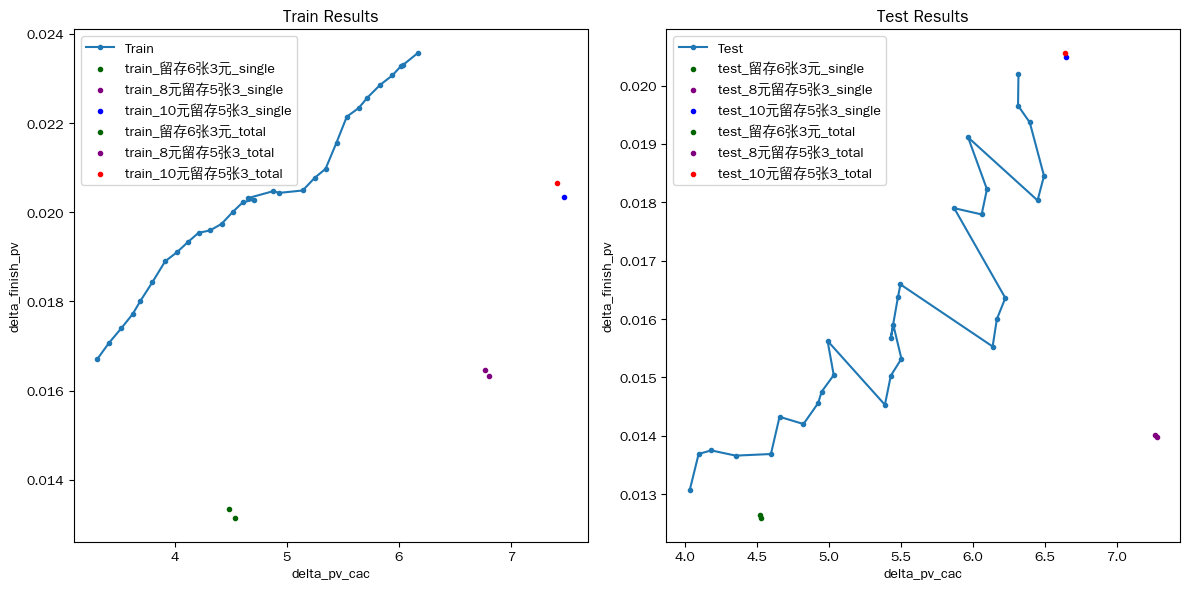


========== euen: running euen_v3 | s4 ==========
columns: ['cost_1', 'left853', 'left63']
all_columns: ['cost_1_per', 'left853_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']
(837501, 40) (843787, 40)
['cost_1_per', 'left853_per'

,cost_1_per,left853_per,left63_per,counts
0,0.1,0.1,0.1,54974
11,0.1,0.2,0.2,19163
111,0.2,0.2,0.2,28905
122,0.2,0.3,0.3,20168
211,0.3,0.2,0.2,12292
222,0.3,0.3,0.3,19456
233,0.3,0.4,0.4,16449
322,0.4,0.3,0.3,11111
333,0.4,0.4,0.4,16603
344,0.4,0.5,0.5,15992


['left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left853_per,left63_per,counts
0,0.1,0.1,21859
12,0.2,0.3,10359
23,0.3,0.4,13359
32,0.4,0.3,13341
34,0.4,0.5,15371
43,0.5,0.4,15989
45,0.5,0.6,15598
54,0.6,0.5,15835
55,0.6,0.6,19229
56,0.6,0.7,13152


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
1,0.2,23291



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,6448
2,0.3,9356
3,0.4,10825
4,0.5,10649
5,0.6,1570
6,0.7,18384
7,0.8,4928
8,0.9,12231
9,1.0,9603


[15  8 17  1 37 20 16  2 21 26 22 11 25 31  5 23 14 34 33 29 10  3 28  7
 13 12 19  6  0  9 27 32  4 30 35 24 36 18]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   7374        7.0       20.0      48.657   
1              0   8元留存5张3   7509       14.0      104.0      34.655   
2              0      DS空白  29562       27.0       85.0       0.000   
3              0    留存6张3元  10529        8.0       63.0      30.578   
4              1  10元留存5张3   2445        3.0       17.0      33.276   
..           ...       ...    ...        ...        ...         ...   
147           36    留存6张3元   4589       15.0       56.0      55.634   
148           37  10元留存5张3  10746      207.0      590.0    1585.188   
149           37   8元留存5张3  10800      179.0      552.0    1165.292   
150           37      DS空白  46423      547.0     1627.0      70.183   
151           37    留存6张3元  16025      226.0      626.0     865.137   

     delta_cvr 

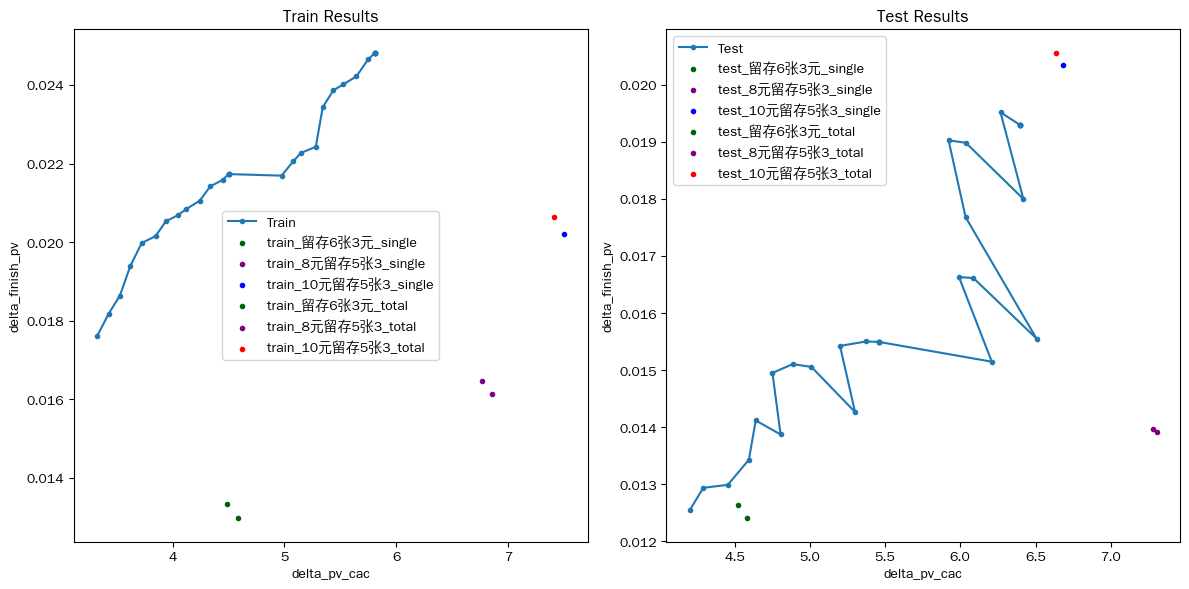


========== euen: running euen_v3 | s5 ==========
columns: ['cost_1', 'left1053_minus_left63', 'left63', 'left853']
all_columns: ['cost_1_per', 'left1053_minus_left63_per', 'left63_per', 'left853_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-06']


,cost_1_per,left1053_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,54508
11,0.1,0.2,0.2,15720
100,0.2,0.1,0.1,10539
111,0.2,0.2,0.2,26097
122,0.2,0.3,0.3,16807
211,0.3,0.2,0.2,11889
222,0.3,0.3,0.3,18480
223,0.3,0.3,0.4,10402
233,0.3,0.4,0.4,14777
322,0.4,0.3,0.3,11316


['left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left853_per,left63_per,counts
0,0.1,0.1,15031
11,0.2,0.2,23135
22,0.3,0.3,26768
33,0.4,0.4,17572
44,0.5,0.5,16857
45,0.5,0.6,10629
55,0.6,0.6,22425
66,0.7,0.7,25402
77,0.8,0.8,36641
88,0.9,0.9,28246


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage

============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,3203
1,0.2,6810
2,0.3,10420
3,0.4,11975
4,0.5,13230
5,0.6,5396
6,0.7,10713
7,0.8,8215
8,0.9,3783
9,1.0,9819


[20 10 36  1 35 37 21  3 32 25 29 27 19 28 14 26  4 34 30 38 18 33 13  9
 24 17 16 23  7  0 12  5  8 22  6 15 31  2 11]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   7339        7.0       20.0      48.618   
1              0   8元留存5张3   7415       15.0      105.0      34.655   
2              0      DS空白  29290       25.0       93.0       0.000   
3              0    留存6张3元  10464        8.0       63.0      30.521   
4              1  10元留存5张3   2055        4.0       18.0      42.322   
..           ...       ...    ...        ...        ...         ...   
151           37    留存6张3元   5585      153.0      333.0     435.495   
152           38  10元留存5张3  10561      183.0      525.0    1548.162   
153           38   8元留存5张3  10730      161.0      443.0     978.687   
154           38      DS空白  45994      487.0     1436.0      40.344   
155           38    留存6张3元  16279      194.0      557.0     808.276   

     delta_c

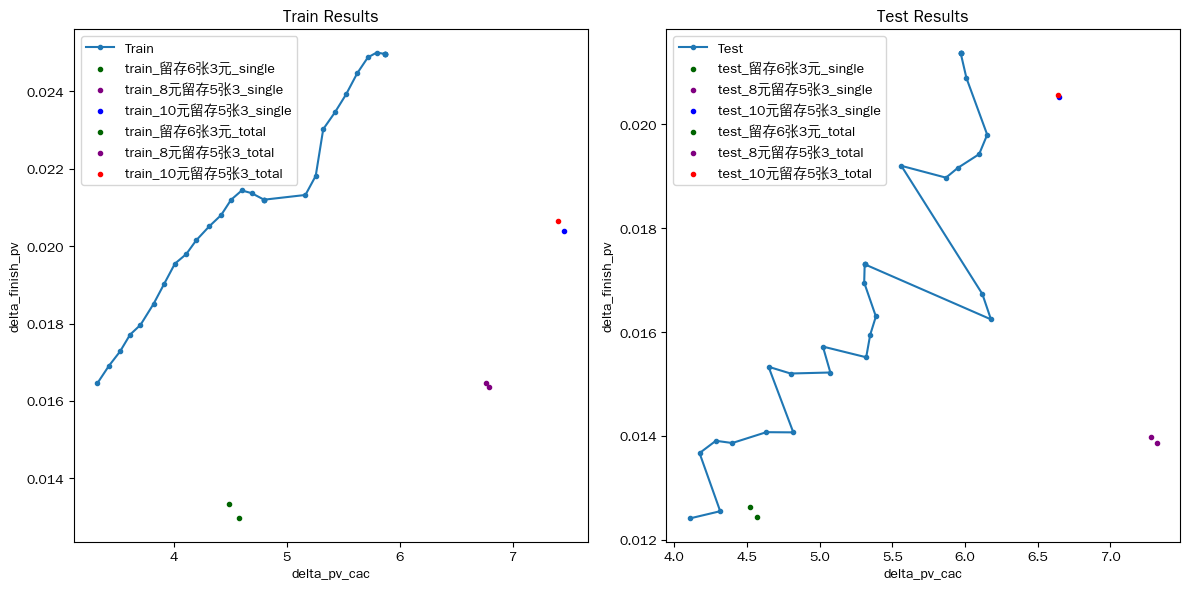

In [42]:
# 搜索 EUEN 的最佳 stage
euen_stage_results = run_stage_search(
    euen_scheme_dfs,
    euen_stage_configs,
    search_name='euen'
)



========== eeuen: running eeuen_v2 | s1 ==========
columns: ['exposure_prob', 'left1053_minus_left63', 'left63', 'left853_minus_left63', 'cost_1', 'left853']
all_columns: ['exposure_prob_per', 'left1053_minus_left63_per', 'left63_per', 'left853_minus_left63_per', 'cost_1_per', 'left853_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-0

,exposure_prob_per,left1053_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,42267
1,0.1,0.1,0.2,10255
111,0.2,0.2,0.2,14784
121,0.2,0.3,0.2,12084
232,0.3,0.4,0.3,10105
799,0.8,1.0,1.0,10274
899,0.9,1.0,1.0,17775
989,1.0,0.9,1.0,12217
999,1.0,1.0,1.0,18302


['exposure_prob_per', 'left853_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,exposure_prob_per,left853_minus_left63_per,left63_per,counts
575,0.6,0.8,0.6,10436
686,0.7,0.9,0.7,10355
687,0.7,0.9,0.8,10373
787,0.8,0.9,0.8,11399
798,0.8,1.0,0.9,12894
807,0.9,0.1,0.8,11688
907,1.0,0.1,0.8,10587
908,1.0,0.1,0.9,25676


['cost_1_per', 'left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,40500
1,0.2,25777
2,0.3,35778
3,0.4,38820
4,0.5,34850
5,0.6,29737
6,0.7,29039



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
7,0.8,12672
8,0.9,5488
9,1.0,6845


[36 26 34 19 33 11 23 35  6  5  0  8 16  9 37 24 32 25 20 31 22 29 21 18
 27 30 39 14 38 12 28 17  4 13  1  7 10  2  3 15]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   6413       26.0       96.0     112.744   
1              0   8元留存5张3   6001       37.0      125.0      54.248   
2              0      DS空白  20858      135.0      600.0       0.000   
3              0    留存6张3元   8995       45.0      182.0      79.483   
4              1  10元留存5张3   1343        1.0        7.0      19.600   
..           ...       ...    ...        ...        ...         ...   
155           38    留存6张3元   5592       79.0      209.0     326.092   
156           39  10元留存5张3   3226      132.0      401.0    1385.322   
157           39   8元留存5张3   3223      113.0      317.0     768.662   
158           39      DS空白  13583      304.0      762.0      45.183   
159           39    留存6张3元   4973      157.0      459.0     689.748   

     delt

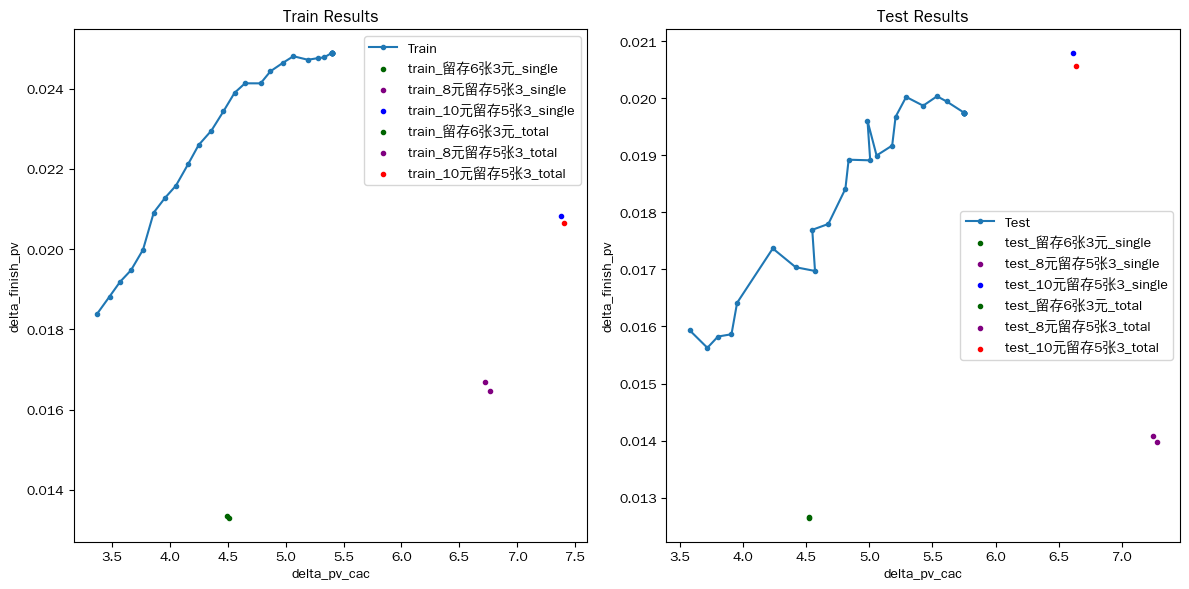


========== eeuen: running eeuen_v2 | s2 ==========
columns: ['exposure_prob', 'left1053_minus_left63', 'left853_minus_left63', 'left63', 'cost_1', 'left1053', 'left853']
all_columns: ['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per', 'cost_1_per', 'left1053_per', 'left853_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08

,exposure_prob_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
20,0.1,0.1,0.3,0.1,11411
30,0.1,0.1,0.4,0.1,12643
40,0.1,0.1,0.5,0.1,10218
7999,0.8,1.0,1.0,1.0,10161
8999,0.9,1.0,1.0,1.0,15994
9999,1.0,1.0,1.0,1.0,12790


['cost_1_per', 'left1053_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left1053_per,left63_per,counts
0,0.1,0.1,0.1,12180
1,0.1,0.1,0.2,13595
11,0.1,0.2,0.2,22871
111,0.2,0.2,0.2,14287
122,0.2,0.3,0.3,21161
233,0.3,0.4,0.4,17366
344,0.4,0.5,0.5,15357
444,0.5,0.5,0.5,10306
455,0.5,0.6,0.6,14601
555,0.6,0.6,0.6,12006


['cost_1_per', 'left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,36315
1,0.2,33004
2,0.3,34979
3,0.4,36014
4,0.5,32202
5,0.6,29580
6,0.7,29439
7,0.8,33959
8,0.9,22266



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
9,1.0,15488


[32 19 29 28 20 13 31  4  3  2 37 23  5 14 33 30 15 27 22 36 12 35 11 26
 18 34 24 21 10  7 16  0 17  8  6 25  1  9]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1567        2.0       15.0       3.665   
1              0   8元留存5张3   1487        6.0       13.0       2.659   
2              0      DS空白   6118       11.0       41.0       0.000   
3              0    留存6张3元   2239        2.0        4.0       3.118   
4              1  10元留存5张3   1988        6.0       23.0      17.101   
..           ...       ...    ...        ...        ...         ...   
147           36    留存6张3元   4353      160.0      382.0     630.534   
148           37  10元留存5张3   1965       60.0      172.0     634.266   
149           37   8元留存5张3   2030       44.0      125.0     529.645   
150           37      DS空白   8405       62.0      162.0      15.021   
151           37    留存6张3元   3088       76.0      208.0     478.580   

     delta_cvr 

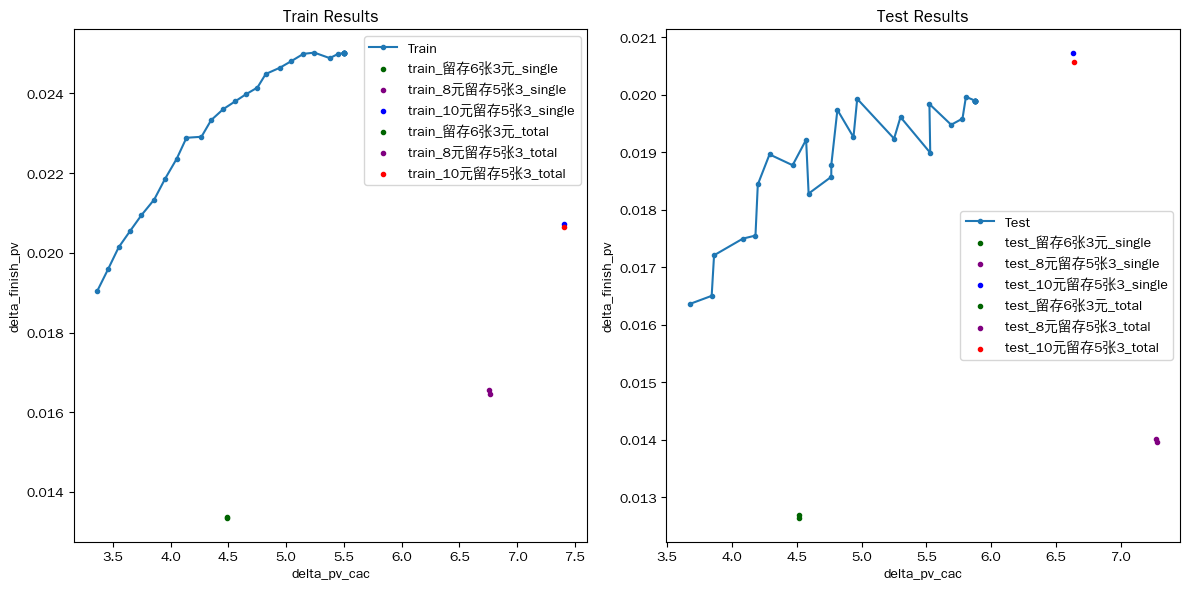


========== eeuen: running eeuen_v2 | s3 ==========
columns: ['exposure_prob', 'left1053_minus_left63', 'left853_minus_left63', 'left63', 'cost_1']
all_columns: ['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per', 'cost_1_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026

,exposure_prob_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
20,0.1,0.1,0.3,0.1,11411
30,0.1,0.1,0.4,0.1,12643
40,0.1,0.1,0.5,0.1,10218
7999,0.8,1.0,1.0,1.0,10161
8999,0.9,1.0,1.0,1.0,15994
9999,1.0,1.0,1.0,1.0,12790


['cost_1_per', 'left1053_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left1053_minus_left63_per,left63_per,counts
11,0.1,0.2,0.2,16976
132,0.2,0.4,0.3,11522
888,0.9,0.9,0.9,11573
898,0.9,1.0,0.9,12378
989,1.0,0.9,1.0,15975


['cost_1_per', 'left853_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,36245
1,0.2,55770
2,0.3,72252
3,0.4,73111
4,0.5,60247
5,0.6,46437
6,0.7,59216
7,0.8,42985
8,0.9,36905



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
9,1.0,17822


[29 18 26  6 25 21 28  4  3  2 10 23  5 16 14 30 27 15 33 32 31 34 22 11
 20 13  0 19 12 17  8  7  1  9 24]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1567        2.0       15.0       3.665   
1              0   8元留存5张3   1487        6.0       13.0       2.659   
2              0      DS空白   6118       11.0       41.0       0.000   
3              0    留存6张3元   2239        2.0        4.0       3.118   
4              1  10元留存5张3   1988        6.0       23.0      17.101   
..           ...       ...    ...        ...        ...         ...   
135           33    留存6张3元   7216      153.0      388.0     758.583   
136           34  10元留存5张3   2251      109.0      320.0    1052.658   
137           34   8元留存5张3   2256      103.0      298.0     971.509   
138           34      DS空白   9637      178.0      480.0      15.000   
139           34    留存6张3元   3678      173.0      452.0     776.347   

     delta_cvr  delta_ca

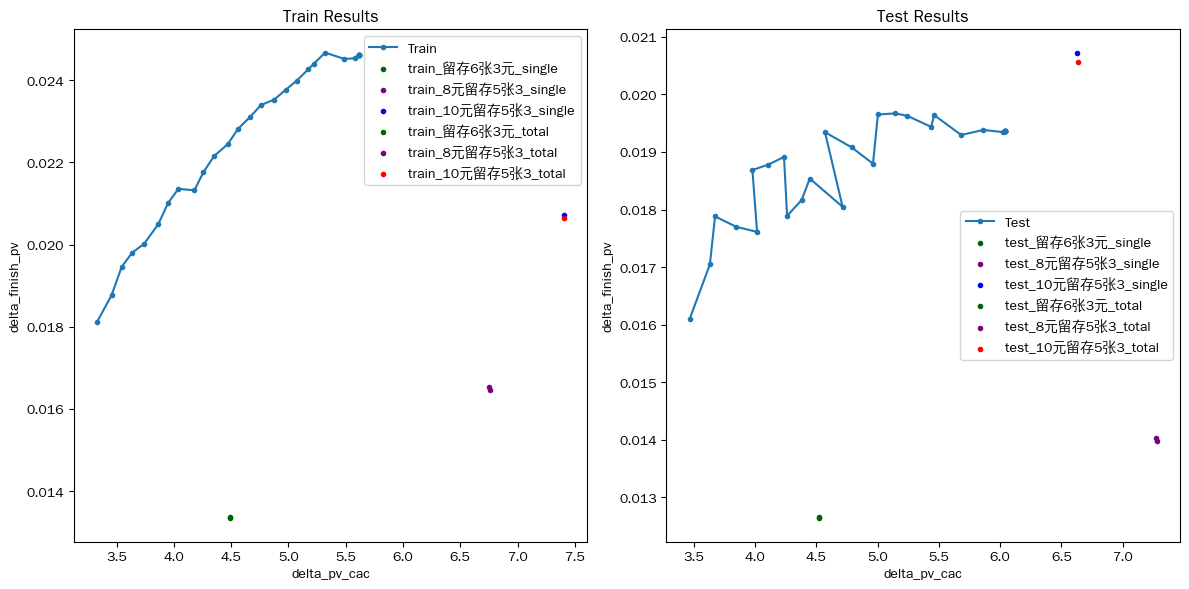


========== eeuen: running eeuen_v2 | s4 ==========
columns: ['exposure_prob', 'left1053_minus_left63', 'left853_minus_left63', 'left63', 'cost_1', 'left853']
all_columns: ['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per', 'cost_1_per', 'left853_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-0

,exposure_prob_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
20,0.1,0.1,0.3,0.1,11411
30,0.1,0.1,0.4,0.1,12643
40,0.1,0.1,0.5,0.1,10218
7999,0.8,1.0,1.0,1.0,10161
8999,0.9,1.0,1.0,1.0,15994
9999,1.0,1.0,1.0,1.0,12790


['cost_1_per', 'left1053_minus_left63_per', 'left853_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left1053_minus_left63_per,left853_per,counts
0,0.1,0.1,0.1,10012
10,0.1,0.2,0.1,12738
11,0.1,0.2,0.2,11018
888,0.9,0.9,0.9,12160
898,0.9,1.0,0.9,10577
989,1.0,0.9,1.0,15077


['left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left853_per,left63_per,counts
0,0.1,0.1,23708
11,0.2,0.2,41722
12,0.2,0.3,14752
21,0.3,0.2,13067
22,0.3,0.3,56107
23,0.3,0.4,12944
32,0.4,0.3,11722
33,0.4,0.4,60942
44,0.5,0.5,66063
55,0.6,0.6,65619


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================

No Large Combinations in this stage

============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,11404
1,0.2,9291
2,0.3,485
3,0.4,10043
4,0.5,18001
5,0.6,6563
6,0.7,10126
7,0.8,11064
8,0.9,5745
9,1.0,4582


[30 23 16 13 25 20 19  4  3  2 11 26  5 21 17 22 15 12 27 24 14 28  7 18
  6  0 10  9  8 29  1]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1567        2.0       15.0       3.665   
1              0   8元留存5张3   1487        6.0       13.0       2.659   
2              0      DS空白   6118       11.0       41.0       0.000   
3              0    留存6张3元   2239        2.0        4.0       3.118   
4              1  10元留存5张3   1988        6.0       23.0      17.101   
..           ...       ...    ...        ...        ...         ...   
119           29    留存6张3元   2134       15.0       42.0     166.198   
120           30  10元留存5张3  11112      176.0      518.0    1526.894   
121           30   8元留存5张3  11167      137.0      428.0    1046.434   
122           30      DS空白  47934      523.0     1466.0      60.246   
123           30    留存6张3元  17091      219.0      633.0     843.318   

     delta_cvr  delta_cac  
0     0.

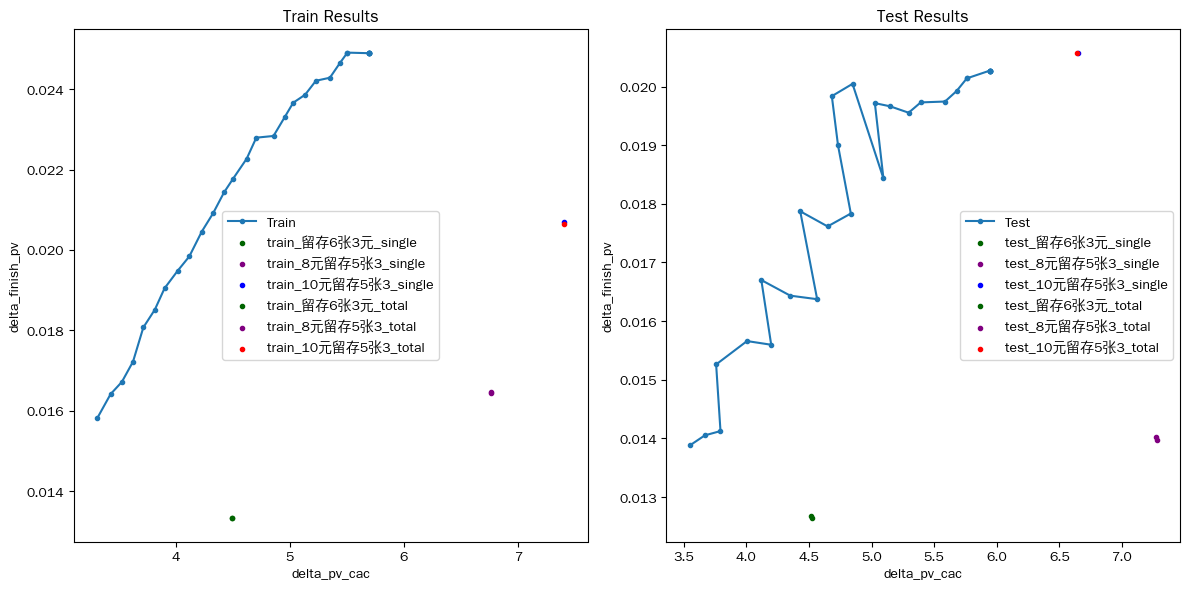


========== eeuen: running eeuen_v2 | s5 ==========
columns: ['cost_1', 'left1053_minus_left63', 'left853_minus_left63', 'left63']
all_columns: ['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '

,cost_1_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
8998,0.9,1.0,1.0,0.9,11023
9999,1.0,1.0,1.0,1.0,36732


['cost_1_per', 'left1053_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left1053_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,27176
11,0.1,0.2,0.2,16976
132,0.2,0.4,0.3,11522
888,0.9,0.9,0.9,11573
989,1.0,0.9,1.0,15975


['cost_1_per', 'left853_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,cost_1_per,left853_minus_left63_per,left63_per,counts
11,0.1,0.2,0.2,11011
243,0.3,0.5,0.4,10818
354,0.4,0.6,0.5,13014
464,0.5,0.7,0.5,10803
465,0.5,0.7,0.6,14132
475,0.5,0.8,0.6,10272
575,0.6,0.8,0.6,13223
576,0.6,0.8,0.7,12528
686,0.7,0.9,0.7,12094
687,0.7,0.9,0.8,10995


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,55591
1,0.2,55770
2,0.3,72252
3,0.4,73111
4,0.5,60247
5,0.6,46437
6,0.7,59216
7,0.8,42985
8,0.9,38208
9,1.0,20035



============================== Final Small Combinations ==============================

No Small Combinations in final stage
[24 13 20  3 22 17 23 29  2  6 18  1 12  9 25 21 10 28 27 26 16 15  8 14
  7 11  0  4  5 19]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1423       78.0      197.0     713.350   
1              0   8元留存5张3   1454       60.0      177.0     476.904   
2              0      DS空白   6071      204.0      454.0       0.000   
3              0    留存6张3元   2075       94.0      223.0     298.454   
4              1  10元留存5张3   4820      549.0     1591.0    5457.097   
..           ...       ...    ...        ...        ...         ...   
115           28    留存6张3元   7452      158.0      396.0     775.867   
116           29  10元留存5张3   2529      108.0      316.0    1076.715   
117           29   8元留存5张3   2577      106.0      310.0    1069.167   
118           29      DS空白  10808      144.0      371.0 

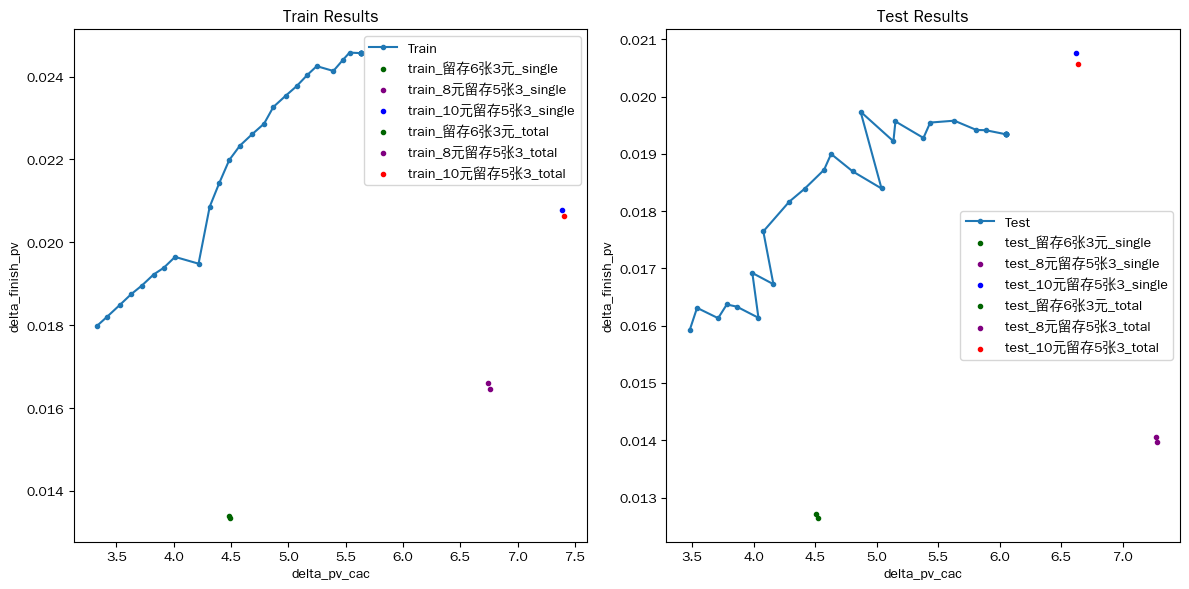


========== eeuen: running eeuen_v3 | s1 ==========
columns: ['exposure_prob', 'left1053_minus_left63', 'left63', 'left853_minus_left63', 'cost_1', 'left853']
all_columns: ['exposure_prob_per', 'left1053_minus_left63_per', 'left63_per', 'left853_minus_left63_per', 'cost_1_per', 'left853_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-0

,exposure_prob_per,left1053_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,13198
1,0.1,0.1,0.2,16547
2,0.1,0.1,0.3,20654
112,0.2,0.2,0.3,11336
434,0.5,0.4,0.5,10828
545,0.6,0.5,0.6,16482
645,0.7,0.5,0.6,11746
656,0.7,0.6,0.7,18691
756,0.8,0.6,0.7,10411
766,0.8,0.7,0.7,10378


['exposure_prob_per', 'left853_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,exposure_prob_per,left853_minus_left63_per,left63_per,counts
788,0.8,0.9,0.9,12232


['cost_1_per', 'left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,60224
1,0.2,52321
2,0.3,51809
3,0.4,39633
4,0.5,45413
5,0.6,45057
6,0.7,34200
7,0.8,20711



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
8,0.9,14456
9,1.0,12515


[33  6 34 32 29 26 22 14 11 31  1 16 17 37 35 27 36  4 28 15 38 25 39 24
 12 10 30  7  8  5 13 20  0 18  2  3 19  9 23 21]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   2127       22.0       73.0      53.244   
1              0   8元留存5张3   1960       32.0      115.0      58.215   
2              0      DS空白   6064      101.0      428.0      25.000   
3              0    留存6张3元   3047       34.0      111.0      53.204   
4              1  10元留存5张3   2785        5.0       10.0      11.435   
..           ...       ...    ...        ...        ...         ...   
155           38    留存6张3元   4001       55.0      141.0     297.176   
156           39  10元留存5张3   3356      166.0      500.0    1464.497   
157           39   8元留存5张3   3473      148.0      420.0    1011.930   
158           39      DS空白  14681      451.0     1225.0      65.000   
159           39    留存6张3元   5461      242.0      595.0     775.976   

     delt

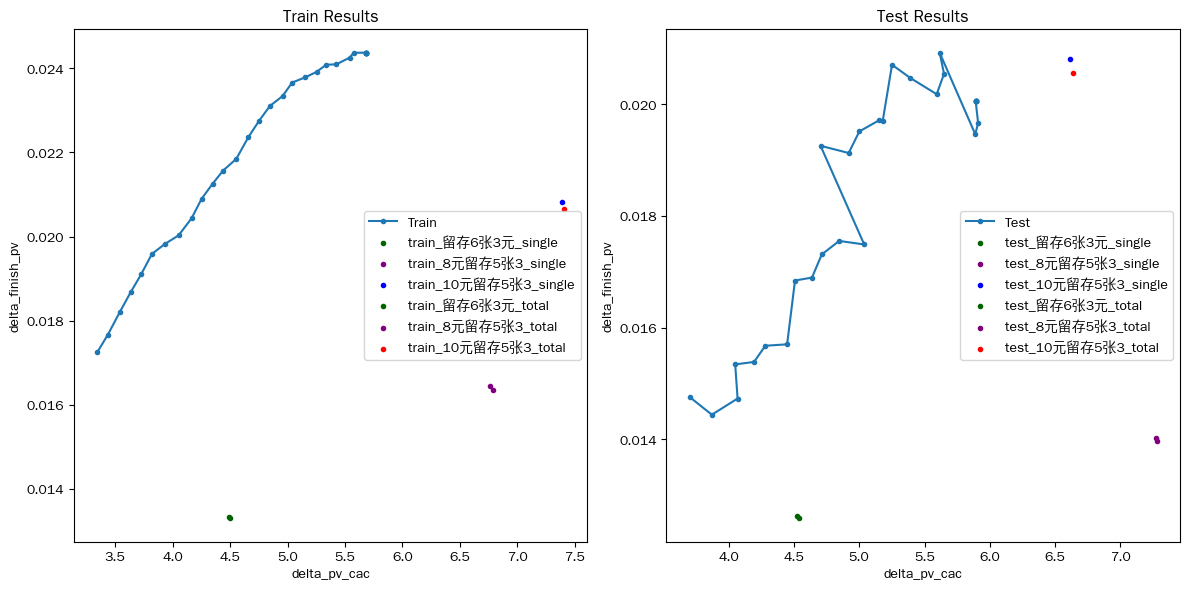


========== eeuen: running eeuen_v3 | s2 ==========
columns: ['exposure_prob', 'left1053_minus_left63', 'left853_minus_left63', 'left63', 'cost_1', 'left1053', 'left853']
all_columns: ['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per', 'cost_1_per', 'left1053_per', 'left853_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08

,exposure_prob_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
12,0.1,0.1,0.2,0.3,13326
7999,0.8,1.0,1.0,1.0,13930
8999,0.9,1.0,1.0,1.0,18773
9888,1.0,0.9,0.9,0.9,12240
9899,1.0,0.9,1.0,1.0,10230
9999,1.0,1.0,1.0,1.0,18491


['cost_1_per', 'left1053_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left1053_per,left63_per,counts
1,0.1,0.1,0.2,11440
11,0.1,0.2,0.2,11950
12,0.1,0.2,0.3,11687
23,0.1,0.3,0.4,10131
100,0.2,0.1,0.1,10519
111,0.2,0.2,0.2,11636
122,0.2,0.3,0.3,14845
123,0.2,0.3,0.4,12121
133,0.2,0.4,0.4,12096
200,0.3,0.1,0.1,10714


['cost_1_per', 'left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,50947
1,0.2,48148
2,0.3,43941
3,0.4,36360
4,0.5,43522
5,0.6,28112
6,0.7,30972
7,0.8,25533



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
8,0.9,17901
9,1.0,10674


[35 20 12 34 32  2  1 37  8  4 42  5 40 38 23 24 39 19 31 28 36 27 17 29
 26 10 33 41 25 15  3 14  7  0 18  9 13 22 21  6 16 11 30]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1851        4.0        9.0       3.581   
1              0   8元留存5张3   1876        5.0       15.0       2.280   
2              0      DS空白   6836        8.0       19.0       0.000   
3              0    留存6张3元   2763        6.0       41.0      28.238   
4              1  10元留存5张3   1862      156.0      409.0    1316.166   
..           ...       ...    ...        ...        ...         ...   
167           41    留存6张3元   4913       66.0      168.0     330.146   
168           42  10元留存5张3   3672      114.0      317.0    1221.260   
169           42   8元留存5张3   3731      117.0      387.0    1034.580   
170           42      DS空白  15540      237.0      556.0      25.281   
171           42    留存6张3元   5632      158.0      417.0     737.570   



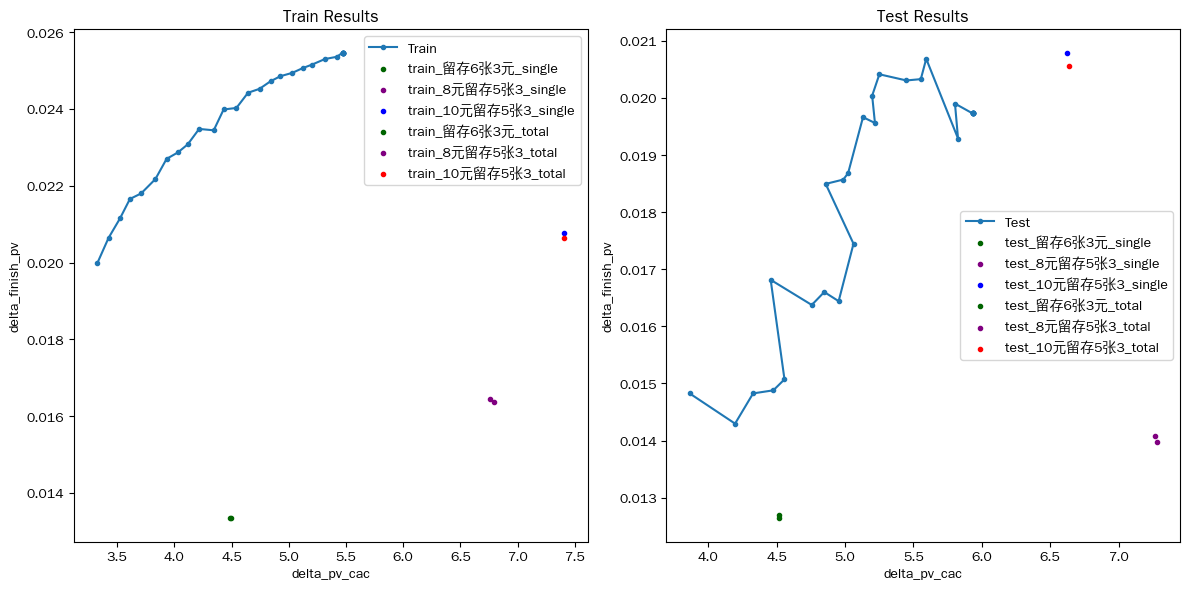


========== eeuen: running eeuen_v3 | s3 ==========
columns: ['exposure_prob', 'left1053_minus_left63', 'left853_minus_left63', 'left63', 'cost_1']
all_columns: ['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per', 'cost_1_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026

,exposure_prob_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
12,0.1,0.1,0.2,0.3,13326
7999,0.8,1.0,1.0,1.0,13930
8999,0.9,1.0,1.0,1.0,18773
9888,1.0,0.9,0.9,0.9,12240
9899,1.0,0.9,1.0,1.0,10230
9999,1.0,1.0,1.0,1.0,18491


['cost_1_per', 'left1053_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left1053_minus_left63_per,left63_per,counts
1,0.1,0.1,0.2,15854
12,0.1,0.2,0.3,10548
123,0.2,0.3,0.4,10403
334,0.4,0.4,0.5,10242
445,0.5,0.5,0.6,16503
556,0.6,0.6,0.7,17751
656,0.7,0.6,0.7,10874
666,0.7,0.7,0.7,16184
667,0.7,0.7,0.8,11955
767,0.8,0.7,0.8,15573


['cost_1_per', 'left853_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,83430
1,0.2,67320
2,0.3,59925
3,0.4,63196
4,0.5,73770
5,0.6,67396
6,0.7,39100
7,0.8,32944
9,1.0,22226



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
8,0.9,17210


[22 10 23 21 14 26  2  1 24  6  4 29  5 27 25  9 15 30 16 18 11 13 28 20
  7  8  3 12 17  0 19]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1851        4.0        9.0       3.581   
1              0   8元留存5张3   1876        5.0       15.0       2.280   
2              0      DS空白   6836        8.0       19.0       0.000   
3              0    留存6张3元   2763        6.0       41.0      28.238   
4              1  10元留存5张3   1862      156.0      409.0    1316.166   
..           ...       ...    ...        ...        ...         ...   
119           29    留存6张3元   4476      202.0      472.0     783.130   
120           30  10元留存5张3   2195       68.0      194.0     710.647   
121           30   8元留存5张3   2207       73.0      224.0     537.612   
122           30      DS空白   9347      187.0      482.0      30.000   
123           30    留存6张3元   3461       99.0      294.0     445.946   

     delta_cvr  delta_cac  
0     0.

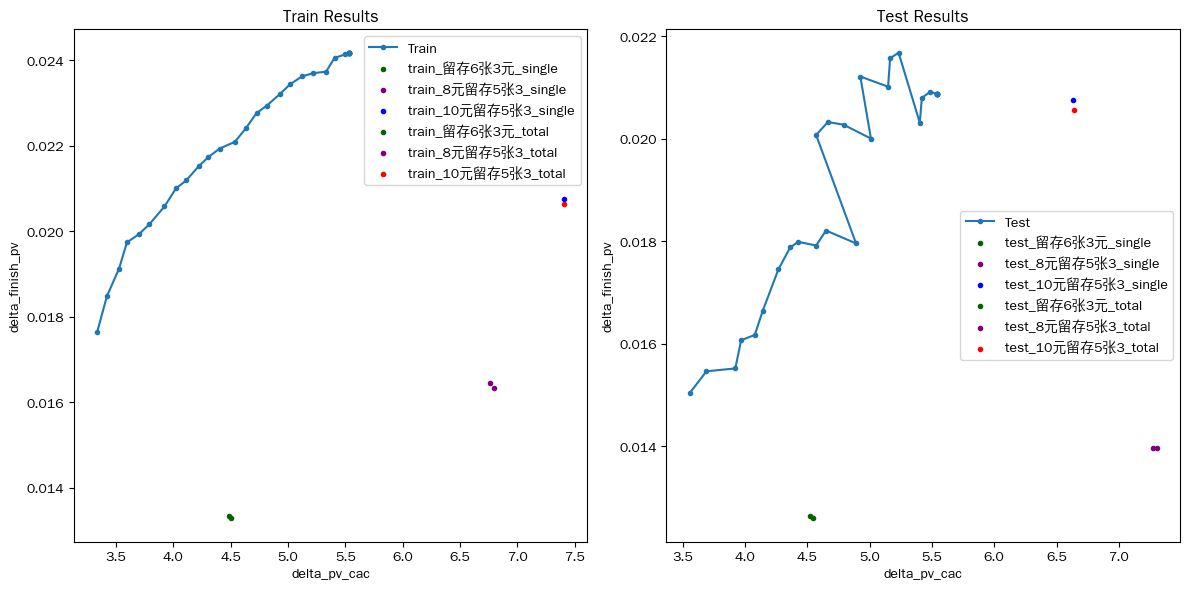


========== eeuen: running eeuen_v3 | s4 ==========
columns: ['exposure_prob', 'left1053_minus_left63', 'left853_minus_left63', 'left63', 'cost_1', 'left853']
all_columns: ['exposure_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per', 'cost_1_per', 'left853_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-0

,exposure_prob_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
12,0.1,0.1,0.2,0.3,13326
7999,0.8,1.0,1.0,1.0,13930
8999,0.9,1.0,1.0,1.0,18773
9888,1.0,0.9,0.9,0.9,12240
9899,1.0,0.9,1.0,1.0,10230
9999,1.0,1.0,1.0,1.0,18491


['cost_1_per', 'left1053_minus_left63_per', 'left853_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left1053_minus_left63_per,left853_per,counts
1,0.1,0.1,0.2,16603
2,0.1,0.1,0.3,11424
12,0.1,0.2,0.3,13136
112,0.2,0.2,0.3,12788
123,0.2,0.3,0.4,12336
223,0.3,0.3,0.4,11988
334,0.4,0.4,0.5,13964
445,0.5,0.5,0.6,16522
556,0.6,0.6,0.7,15921
656,0.7,0.6,0.7,10321


['left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left853_per,left63_per,counts
0,0.1,0.1,74740
11,0.2,0.2,43744
21,0.3,0.2,12431
22,0.3,0.3,17443
32,0.4,0.3,14106
33,0.4,0.4,28153
34,0.4,0.5,11732
43,0.5,0.4,13565
44,0.5,0.5,37820
45,0.5,0.6,14622


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================

No Large Combinations in this stage

============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,8690
1,0.2,14159
2,0.3,11914
3,0.4,9155
4,0.5,2214
5,0.6,10176
6,0.7,5378
7,0.8,11181
8,0.9,7954
9,1.0,2407


[39 13 23 24 22 17 32  2  1 25  6  4 37  5 33 31 34 12 18 36 26 16 29 19
  9 21 14 15 35  8 10  3 30 38 20  0 28 11  7 27]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1851        4.0        9.0       3.581   
1              0   8元留存5张3   1876        5.0       15.0       2.280   
2              0      DS空白   6836        8.0       19.0       0.000   
3              0    留存6张3元   2763        6.0       41.0      28.238   
4              1  10元留存5张3   1862      156.0      409.0    1316.166   
..           ...       ...    ...        ...        ...         ...   
155           38    留存6张3元   2323        1.0        2.0      45.544   
156           39  10元留存5张3  10713      159.0      425.0    1263.632   
157           39   8元留存5张3  10933      143.0      464.0    1020.566   
158           39      DS空白  45116      513.0     1553.0      20.538   
159           39    留存6张3元  16466      241.0      740.0     966.084   

     delt

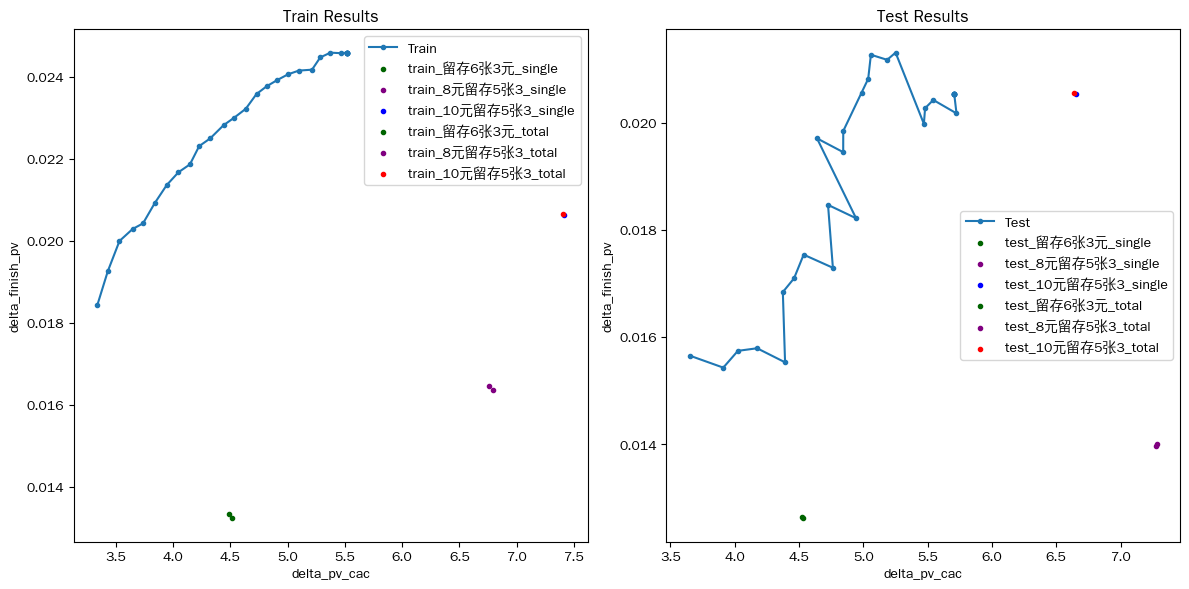


========== eeuen: running eeuen_v3 | s5 ==========
columns: ['cost_1', 'left1053_minus_left63', 'left853_minus_left63', 'left63']
all_columns: ['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-30']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-07-31']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-01']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-03']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-04']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '2026-07-29']
['2026-08-05']
['2026-07-23', '2026-07-24', '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28', '

,cost_1_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
12,0.1,0.1,0.2,0.3,13672
8788,0.9,0.8,0.9,0.9,12478
8888,0.9,0.9,0.9,0.9,16935
9899,1.0,0.9,1.0,1.0,10593
9999,1.0,1.0,1.0,1.0,52964


['cost_1_per', 'left1053_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left1053_minus_left63_per,left63_per,counts
1,0.1,0.1,0.2,15854
12,0.1,0.2,0.3,10548
123,0.2,0.3,0.4,10403
334,0.4,0.4,0.5,10242
445,0.5,0.5,0.6,16503
556,0.6,0.6,0.7,17751
656,0.7,0.6,0.7,10874
666,0.7,0.7,0.7,16184
667,0.7,0.7,0.8,11955
767,0.8,0.7,0.8,15573


['cost_1_per', 'left853_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,cost_1_per,left853_minus_left63_per,left63_per,counts
13,0.1,0.2,0.4,10447
788,0.8,0.9,0.9,14763


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,83430
1,0.2,67320
2,0.3,59579
3,0.4,63196
4,0.5,73770
5,0.6,67396
6,0.7,39100
7,0.8,32944
8,0.9,27140
9,1.0,20093



============================== Final Small Combinations ==============================

No Small Combinations in final stage
[23  9 20 19 13 24  4 28 21  5  3 25 22  8 14 27 15 10 11 26  1 18  6  7
  2 12  0 16 17]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1886        3.0        7.0       3.905   
1              0   8元留存5张3   1908        6.0       26.0       2.129   
2              0      DS空白   7040        7.0       30.0       0.000   
3              0    留存6张3元   2838        6.0       41.0      28.322   
4              1  10元留存5张3   1538       33.0       63.0     342.136   
..           ...       ...    ...        ...        ...         ...   
111           27    留存6张3元   5381      135.0      393.0     677.190   
112           28  10元留存5张3   2573      102.0      270.0    1054.134   
113           28   8元留存5张3   2615       94.0      258.0     809.402   
114           28      DS空白  10942      157.0      332.0    

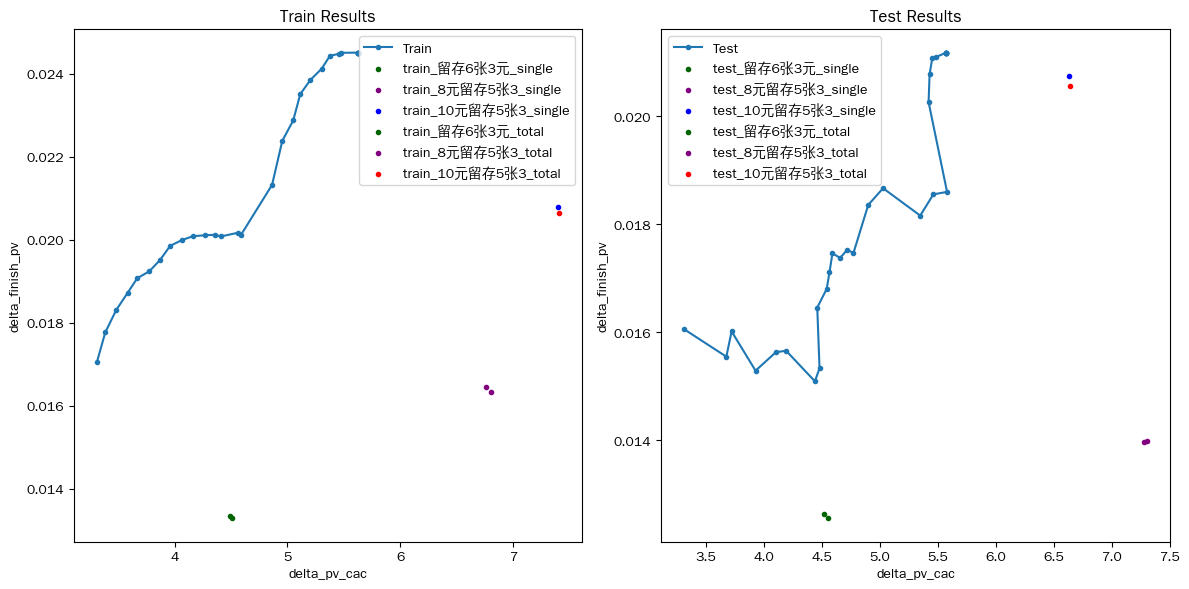

In [43]:
# 搜索 EEUEN 的最佳 stage
eeuen_stage_results = run_stage_search(
    eeuen_scheme_dfs,
    eeuen_stage_configs,
    search_name='eeuen'
)

In [35]:
# 合并 EUEN / EEUEN 搜索结果
stage_results = {}

if 'euen_stage_results' in globals():
    stage_results.update(euen_stage_results)

if 'eeuen_stage_results' in globals():
    stage_results.update(eeuen_stage_results)

stage_results.keys()

dict_keys([('euen_v2', 's1'), ('euen_v2', 's2'), ('euen_v2', 's3'), ('euen_v2', 's4'), ('euen_v2', 's5'), ('euen_v3', 's1'), ('euen_v3', 's2'), ('euen_v3', 's3'), ('euen_v3', 's4'), ('euen_v3', 's5')])

In [36]:

# 7. 汇总 train/test 仿真结果

def build_stage_result_df(result_list, scheme_name, stage_name, data_type, search_name):
    df = pd.DataFrame(
        result_list,
        columns=[
            '约束cac',
            '实际增量cac',
            '实际增量cvr',
            '实际增量首单cvr',
            '留存频次',
        ]
    )
    df['search_name'] = search_name
    df['scheme'] = scheme_name
    df['stage_name'] = stage_name
    df['data_type'] = data_type
    return df


summary_list = []

for (scheme_name, stage_name), res in stage_results.items():
    summary_list.append(build_stage_result_df(res['train_list'], scheme_name, stage_name, 'train', res['search_name']))
    summary_list.append(build_stage_result_df(res['test_list'], scheme_name, stage_name, 'test', res['search_name']))

stage_summary_df = pd.concat(summary_list, ignore_index=True)

stage_summary_df[
    ['search_name', 'scheme', 'stage_name', 'data_type', '约束cac', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']
].head(10)

,search_name,scheme,stage_name,data_type,约束cac,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
0,euen,euen_v2,s1,train,3.5,3.296566,0.016622,0.005885,2.824695
1,euen,euen_v2,s1,train,3.6,3.390304,0.017142,0.005945,2.883638
2,euen,euen_v2,s1,train,3.7,3.491802,0.017847,0.006138,2.907647
3,euen,euen_v2,s1,train,3.8,3.579752,0.018362,0.006325,2.903278
4,euen,euen_v2,s1,train,3.9,3.686996,0.018627,0.006489,2.870554
5,euen,euen_v2,s1,train,4.0,3.787625,0.018874,0.006749,2.796709
6,euen,euen_v2,s1,train,4.1,3.879575,0.019529,0.006596,2.960801
7,euen,euen_v2,s1,train,4.2,3.982961,0.020048,0.006792,2.951578
8,euen,euen_v2,s1,train,4.3,4.093110,0.020295,0.007060,2.874648
9,euen,euen_v2,s1,train,4.4,4.206901,0.020475,0.006861,2.984204


In [ ]:

# 8. 一个模型一个图：不同 stage 下验证集仿真曲线

for scheme_name in ['euen_v2', 'euen_v3', 'eeuen_v2', 'eeuen_v3']:
    plt.figure(figsize=(9, 6))

    stage_names = (
        stage_summary_df[
            (stage_summary_df['scheme'] == scheme_name) &
            (stage_summary_df['data_type'] == 'test')
        ]['stage_name']
        .drop_duplicates()
        .tolist()
    )

    for stage_name in stage_names:
        plot_df = stage_summary_df[
            (stage_summary_df['scheme'] == scheme_name) &
            (stage_summary_df['stage_name'] == stage_name) &
            (stage_summary_df['data_type'] == 'test')
        ].replace([np.inf, -np.inf], np.nan).dropna(
            subset=['实际增量cac', '实际增量cvr']
        ).sort_values('约束cac')

        # ).sort_values('实际增量cac')

        plt.plot(
            plot_df['实际增量cac'],
            plot_df['实际增量cvr'],
            marker='.',
            label=stage_name
        )

    plt.xlabel('验证集实际增量 PV CAC')
    plt.ylabel('验证集人均增量完单 PV')
    plt.title(f'{scheme_name}：不同 stage 验证集仿真曲线')
    plt.legend()
    plt.grid(True)
    plt.show()

In [47]:
# 最佳参数

best_stage_map = {
    'euen_v2': 's5',
    'euen_v3': 's5',
    'eeuen_v2': 's3',
    'eeuen_v3': 's3',
}

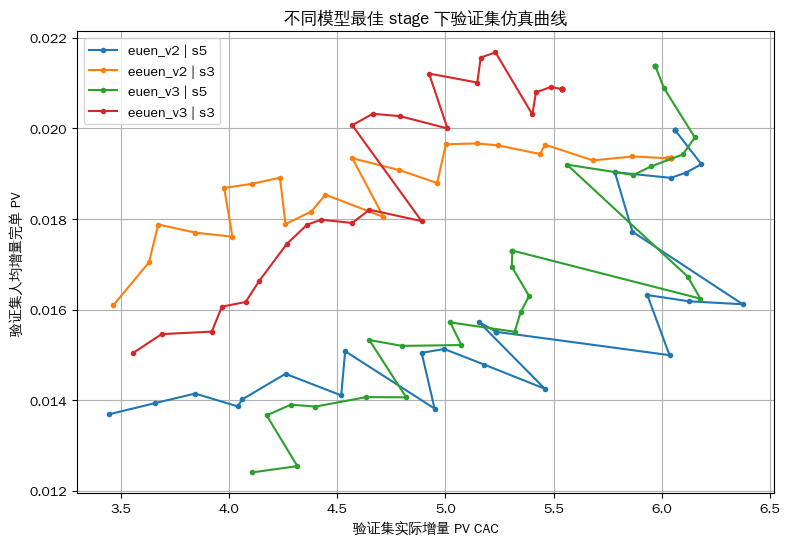

In [48]:
best_stage_summary_df = pd.concat([
    stage_summary_df[
        (stage_summary_df['scheme'] == scheme) &
        (stage_summary_df['stage_name'] == stage_name) &
        (stage_summary_df['data_type'] == 'test')
    ]
    for scheme, stage_name in best_stage_map.items()
], ignore_index=True)

plt.figure(figsize=(9, 6))

for scheme_name in ['euen_v2', 'eeuen_v2', 'euen_v3', 'eeuen_v3']:
    plot_df = best_stage_summary_df[
        best_stage_summary_df['scheme'] == scheme_name
    ].replace([np.inf, -np.inf], np.nan).dropna(
        subset=['实际增量cac', '实际增量cvr']
   # ).sort_values('实际增量cac')
    ).sort_values('约束cac')

    plt.plot(
        plot_df['实际增量cac'],
        plot_df['实际增量cvr'],
        marker='.',
        label=f"{scheme_name} | {best_stage_map[scheme_name]}"
    )

plt.xlabel('验证集实际增量 PV CAC')
plt.ylabel('验证集人均增量完单 PV')
plt.title('不同模型最佳 stage 下验证集仿真曲线')
plt.legend()
plt.grid(True)
plt.show()